In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch

# ── Reproducibility Seeds ─────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Paths (Auto-detect Kaggle vs Local) ───────────────────
KAGGLE_WATER = '/kaggle/input/datasets/mariyaabdul/marine-debris-fls/marine-debris-fls-datasets/md_fls_dataset/data/watertank-cropped'
LOCAL_WATER  = os.path.join(os.getcwd(), 'md_fls_dataset', 'data', 'watertank-cropped')

if os.path.exists(KAGGLE_WATER):
    WATER_PATH = KAGGLE_WATER
    WORK_DIR   = '/kaggle/working'
elif os.path.exists(LOCAL_WATER):
    WATER_PATH = LOCAL_WATER
    WORK_DIR   = os.path.join(os.getcwd(), 'outputs')
else:
    WATER_PATH = KAGGLE_WATER
    WORK_DIR   = '/kaggle/working'

MODEL_DIR   = os.path.join(WORK_DIR, 'models')
RESULTS_DIR = os.path.join(WORK_DIR, 'results')
FIGURES_DIR = os.path.join(WORK_DIR, 'figures')

for d in [MODEL_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Verify path exists ───────────────────────────────────
if os.path.exists(WATER_PATH):
    print(f"✅ Dataset path found: {WATER_PATH}")
else:
    print(f"❌ Path not found — check path above: {WATER_PATH}")

# ── List all classes ─────────────────────────────────────
classes = sorted([c for c in os.listdir(WATER_PATH)
                  if os.path.isdir(os.path.join(WATER_PATH, c))])

print(f"\nClasses found: {len(classes)}")
total = 0
for cls in classes:
    imgs = sorted([f for f in os.listdir(os.path.join(WATER_PATH, cls))
                   if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])
    total += len(imgs)
    print(f"  {cls:<25} → {len(imgs):>4} images")
print(f"\n  {'TOTAL':<25} → {total:>4} images")

# ── GPU Check ────────────────────────────────────────────
print(f"\nGPU available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name      : {torch.cuda.get_device_name(0)}")


✅ Dataset path found: /kaggle/input/datasets/mariyaabdul/marine-debris-fls/marine-debris-fls-datasets/md_fls_dataset/data/watertank-cropped

Classes found: 10
  bottle                    →  449 images
  can                       →  367 images
  chain                     →  226 images
  drink-carton              →  349 images
  hook                      →  133 images
  propeller                 →  137 images
  shampoo-bottle            →   99 images
  standing-bottle           →   65 images
  tire                      →  331 images
  valve                     →  208 images

  TOTAL                     → 2364 images

GPU available : True
GPU name      : Tesla T4


In [2]:
# ── Known vs Unknown Split ───────────────────────────────
KNOWN_CLASSES = [
    'bottle',
    'can',
    'tire',
    'drink-carton',
    'hook',
    'propeller'
]

UNKNOWN_CLASSES = [
    'chain',
    'valve',
    'shampoo-bottle',
    'standing-bottle'
]

# ── Class index mapping (known only) ─────────────────────
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(KNOWN_CLASSES)}
IDX_TO_CLASS = {idx: cls for cls, idx in CLASS_TO_IDX.items()}

NUM_CLASSES = len(KNOWN_CLASSES)

print("✅ Class split defined!")
print(f"\nKnown classes ({NUM_CLASSES}):")
for cls, idx in CLASS_TO_IDX.items():
    print(f"  {idx}: {cls}")

print(f"\nUnknown classes ({len(UNKNOWN_CLASSES)}):")
for cls in UNKNOWN_CLASSES:
    print(f"  - {cls}")

✅ Class split defined!

Known classes (6):
  0: bottle
  1: can
  2: tire
  3: drink-carton
  4: hook
  5: propeller

Unknown classes (4):
  - chain
  - valve
  - shampoo-bottle
  - standing-bottle


KNOWN CLASSES:


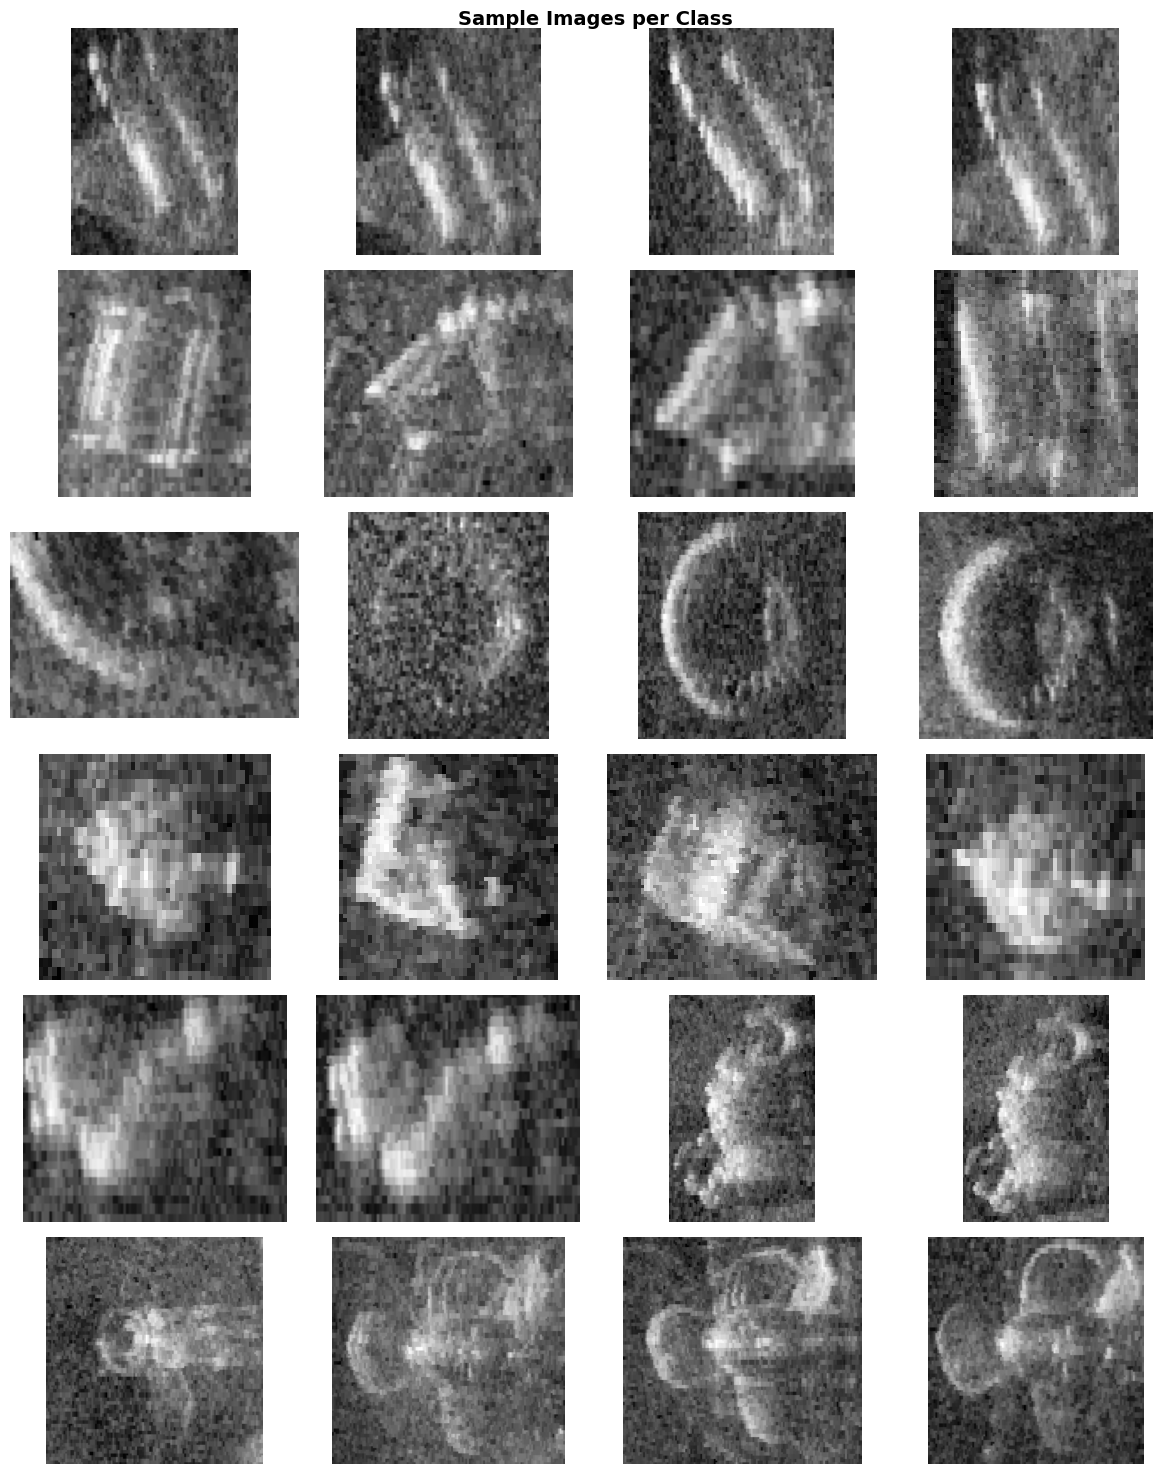

✅ Saved to figures/sample_images.png


In [3]:
def show_samples(dataset_path, classes, n=4):
    fig, axes = plt.subplots(
        len(classes), n,
        figsize=(n*3, len(classes)*2.5)
    )
    fig.suptitle('Sample Images per Class', 
                  fontsize=14, fontweight='bold')

    for row, cls in enumerate(classes):
        cls_path = os.path.join(dataset_path, cls)
        imgs     = [f for f in os.listdir(cls_path)
                    if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))]
        
        # pick n random samples
        import random
        samples = random.sample(imgs, min(n, len(imgs)))

        for col in range(n):
            ax = axes[row][col]
            if col < len(samples):
                img = Image.open(
                    os.path.join(cls_path, samples[col])
                ).convert('L')  # grayscale
                ax.imshow(img, cmap='gray')
                if col == 0:
                    ax.set_ylabel(cls, fontsize=9, 
                                  fontweight='bold')
            ax.axis('off')

    plt.tight_layout()
    plt.savefig(f'{FIGURES_DIR}/sample_images.png', 
                dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Saved to figures/sample_images.png")

# Show known classes
print("KNOWN CLASSES:")
show_samples(WATER_PATH, KNOWN_CLASSES)


UNKNOWN CLASSES:


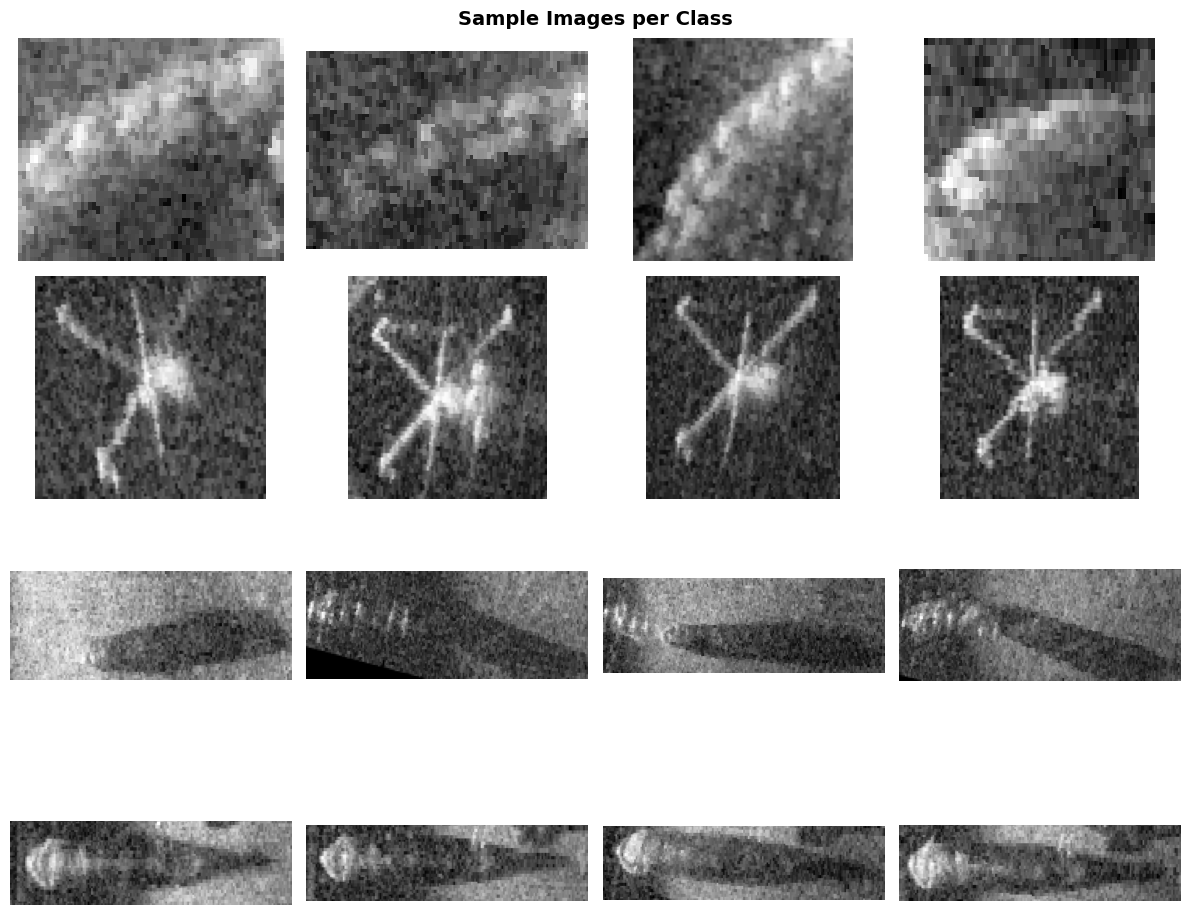

✅ Saved to figures/sample_images.png


In [4]:
print("UNKNOWN CLASSES:")
show_samples(WATER_PATH, UNKNOWN_CLASSES)

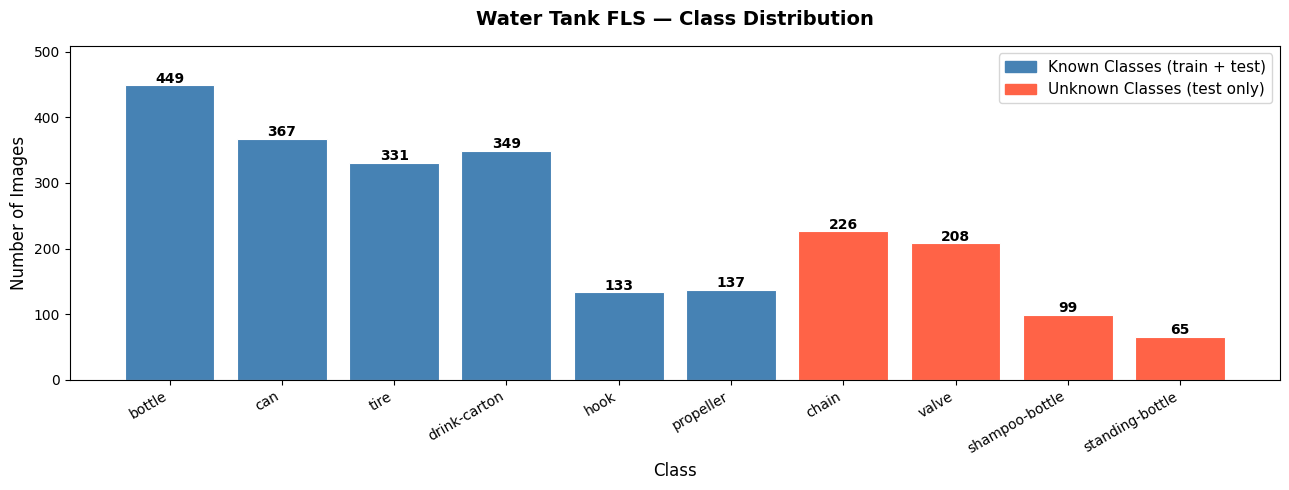

✅ Saved to figures/class_distribution.png


In [5]:
# ── Count images ─────────────────────────────────────────
class_counts = {}
for cls in KNOWN_CLASSES + UNKNOWN_CLASSES:
    imgs = [f for f in os.listdir(os.path.join(WATER_PATH, cls))
            if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))]
    class_counts[cls] = len(imgs)

# ── Plot ─────────────────────────────────────────────────
colors = ['steelblue' if c in KNOWN_CLASSES 
          else 'tomato' for c in class_counts]

fig, ax = plt.subplots(figsize=(13, 5))
bars    = ax.bar(class_counts.keys(),
                  class_counts.values(),
                  color=colors, edgecolor='white',
                  linewidth=0.8)

# Count labels on top of bars
for bar, val in zip(bars, class_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 4,
            str(val), ha='center',
            fontsize=10, fontweight='bold')

# Legend
legend = [
    mpatches.Patch(color='steelblue', label='Known Classes (train + test)'),
    mpatches.Patch(color='tomato',    label='Unknown Classes (test only)')
]
ax.legend(handles=legend, fontsize=11)
ax.set_title('Water Tank FLS — Class Distribution',
              fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Number of Images', fontsize=12)
ax.set_ylim(0, max(class_counts.values()) + 60)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/class_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved to figures/class_distribution.png")

In [6]:
# ── Check what sizes your images are ─────────────────────
print("Checking image sizes per class:")
print("=" * 55)
print(f"{'Class':<20} {'Min Size':>12} {'Max Size':>12} {'Mode':>12}")
print("-" * 55)

for cls in KNOWN_CLASSES + UNKNOWN_CLASSES:
    cls_path = os.path.join(WATER_PATH, cls)
    imgs     = sorted([f for f in os.listdir(cls_path)
                       if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])

    sizes = []
    for img_name in imgs[:50]:  # check first 50
        img = Image.open(os.path.join(cls_path, img_name))
        sizes.append(img.size)  # (width, height)

    sizes_arr = np.array(sizes)
    min_s = tuple(int(v) for v in sizes_arr.min(axis=0))
    max_s = tuple(int(v) for v in sizes_arr.max(axis=0))

    from collections import Counter
    mode_size = Counter(map(tuple, sizes)).most_common(1)[0][0]

    print(f"{cls:<20} "
          f"{str(min_s):>12} "
          f"{str(max_s):>12} "
          f"{str(mode_size):>12}")

print("\n✅ Size check complete!")
print("Note: ResNet-50 needs 224x224 — we will resize all images")


Checking image sizes per class:
Class                    Min Size     Max Size         Mode
-------------------------------------------------------
bottle                   (72, 57)    (103, 98)     (79, 97)
can                      (47, 55)    (105, 96)     (68, 80)
tire                     (80, 66)   (125, 128)     (85, 88)
drink-carton             (44, 47)     (88, 74)     (50, 52)
hook                     (89, 66)   (115, 173)    (115, 81)
propeller                (96, 80)   (142, 135)   (131, 128)
chain                    (48, 50)   (148, 235)     (63, 61)
valve                    (56, 78)   (100, 121)    (91, 102)
shampoo-bottle          (173, 67)    (251, 75)    (251, 69)
standing-bottle         (161, 42)    (181, 50)    (176, 48)

✅ Size check complete!
Note: ResNet-50 needs 224x224 — we will resize all images


In [7]:
# ── Compute class weights for imbalanced training ────────
known_counts = {cls: class_counts[cls] for cls in KNOWN_CLASSES}
max_count    = max(known_counts.values())
total_known  = sum(known_counts.values())

print("Class weights to handle imbalance:")
print("=" * 50)
print(f"{'Class':<20} {'Count':>6}  {'Weight':>8}  {'Bar'}")
print("-" * 50)

CLASS_WEIGHTS = []
for cls in KNOWN_CLASSES:
    count  = known_counts[cls]
    weight = max_count / count
    CLASS_WEIGHTS.append(weight)
    bar    = '█' * int(weight * 8)
    print(f"{cls:<20} {count:>6}  {weight:>8.2f}  {bar}")

print(f"\nTotal known images : {total_known}")
print(f"Class weights list : {[round(w,2) for w in CLASS_WEIGHTS]}")
print("\n⚠️  hook, propeller will be upweighted during training")
print("✅ Weights saved!")

Class weights to handle imbalance:
Class                 Count    Weight  Bar
--------------------------------------------------
bottle                  449      1.00  ████████
can                     367      1.22  █████████
tire                    331      1.36  ██████████
drink-carton            349      1.29  ██████████
hook                    133      3.38  ███████████████████████████
propeller               137      3.28  ██████████████████████████

Total known images : 1766
Class weights list : [1.0, 1.22, 1.36, 1.29, 3.38, 3.28]

⚠️  hook, propeller will be upweighted during training
✅ Weights saved!


In [8]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def analyze_image_quality(dataset_path, classes, samples_per_class=20):
    print("Image Quality Analysis:")
    print("=" * 70)
    print(f"{'Class':<20} {'Brightness':>12} {'Contrast':>10} {'Sharpness':>10} {'SNR':>8}")
    print("-" * 70)
    
    results = {}
    for cls in classes:
        cls_path = os.path.join(dataset_path, cls)
        imgs     = sorted([f for f in os.listdir(cls_path)
                           if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])
        
        brightness_list = []
        contrast_list   = []
        sharpness_list  = []
        snr_list        = []
        
        for img_name in imgs[:samples_per_class]:
            img = cv2.imread(os.path.join(cls_path, img_name),
                             cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
                
            brightness = np.mean(img)
            contrast   = np.std(img)
            sharpness  = cv2.Laplacian(img, cv2.CV_64F).var()
            snr        = brightness / contrast if contrast > 0 else 0
            
            brightness_list.append(brightness)
            contrast_list.append(contrast)
            sharpness_list.append(sharpness)
            snr_list.append(snr)
        
        results[cls] = {
            'brightness': float(np.mean(brightness_list)),
            'contrast'  : float(np.mean(contrast_list)),
            'sharpness' : float(np.mean(sharpness_list)),
            'snr'       : float(np.mean(snr_list))
        }
        
        tag = '⚠️' if np.mean(sharpness_list) < 100 else '✅'
        print(f"{cls:<20} "
              f"{np.mean(brightness_list):>12.2f} "
              f"{np.mean(contrast_list):>10.2f} "
              f"{np.mean(sharpness_list):>10.2f} "
              f"{np.mean(snr_list):>8.2f} {tag}")
    
    return results

quality_results = analyze_image_quality(
    WATER_PATH,
    KNOWN_CLASSES + UNKNOWN_CLASSES
)


Image Quality Analysis:
Class                  Brightness   Contrast  Sharpness      SNR
----------------------------------------------------------------------
bottle                     103.60      38.68    2409.97     2.69 ✅
can                        114.27      37.45    2095.25     3.13 ✅
tire                        76.91      36.15    2540.81     2.15 ✅
drink-carton               109.62      45.53    2447.17     2.45 ✅
hook                       108.15      41.60    1474.82     2.62 ✅
propeller                  117.35      32.61    1366.53     3.67 ✅
chain                      120.40      39.69    1642.07     3.05 ✅
valve                       75.92      38.43    2839.29     1.98 ✅
shampoo-bottle             115.94      41.39    2577.12     2.79 ✅
standing-bottle            117.53      39.24    1991.57     3.01 ✅


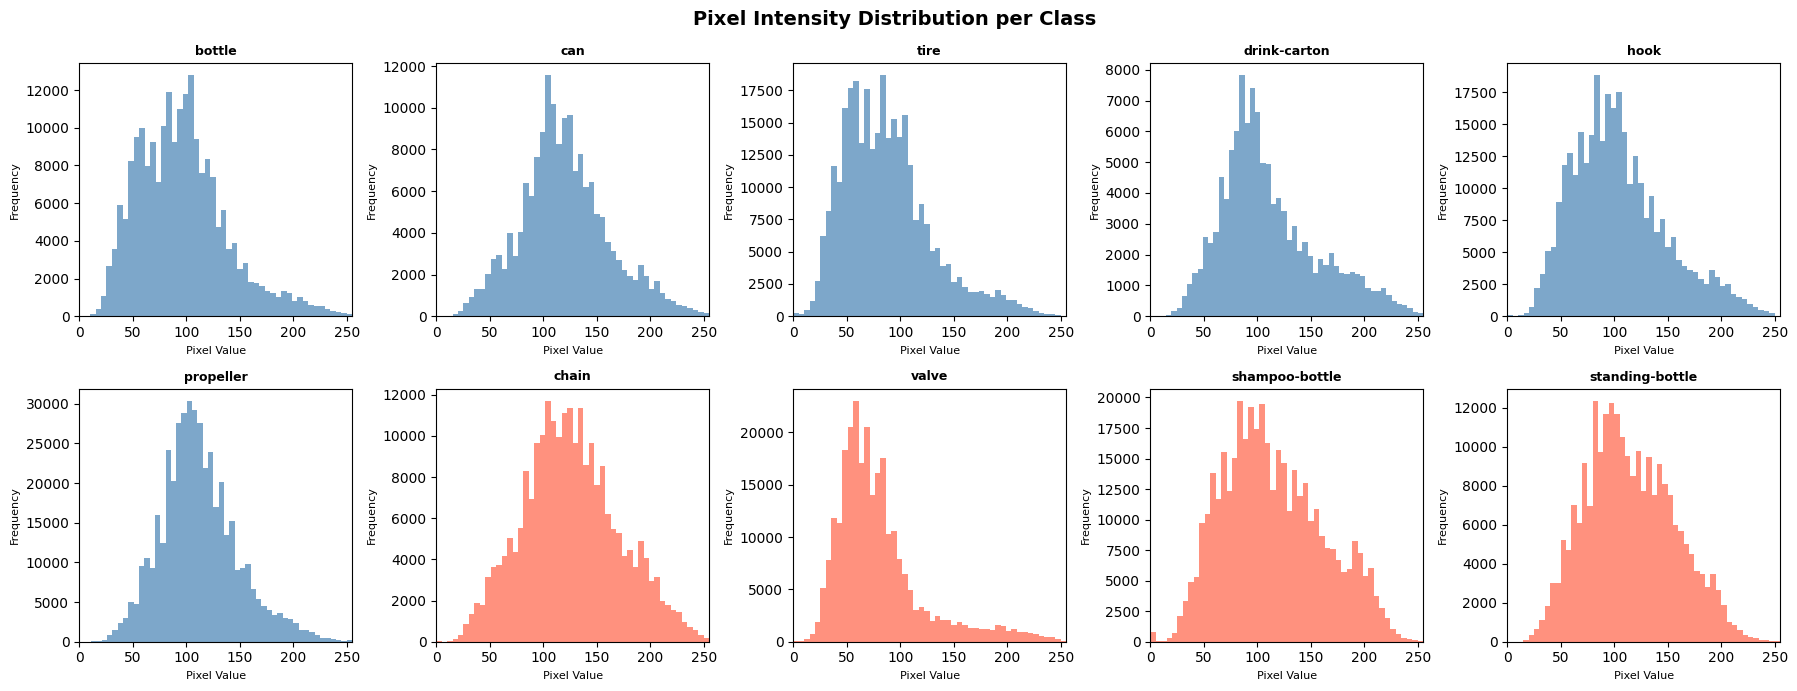

✅ Saved pixel_distributions.png


In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes      = axes.flatten()
all_cls   = KNOWN_CLASSES + UNKNOWN_CLASSES

for idx, cls in enumerate(all_cls):
    cls_path = os.path.join(WATER_PATH, cls)
    imgs     = [f for f in os.listdir(cls_path)
                if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))]
    
    # Collect pixel values from 30 random images
    all_pixels = []
    import random
    for img_name in random.sample(imgs, min(30, len(imgs))):
        img = cv2.imread(
            os.path.join(cls_path, img_name),
            cv2.IMREAD_GRAYSCALE
        )
        if img is not None:
            all_pixels.extend(img.flatten().tolist())
    
    color = 'steelblue' if cls in KNOWN_CLASSES else 'tomato'
    axes[idx].hist(all_pixels, bins=50, 
                   color=color, alpha=0.7,
                   edgecolor='none')
    axes[idx].set_title(cls, fontsize=9, fontweight='bold')
    axes[idx].set_xlabel('Pixel Value', fontsize=8)
    axes[idx].set_ylabel('Frequency', fontsize=8)
    axes[idx].set_xlim(0, 255)

# Hide any unused subplots
for idx in range(len(all_cls), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Pixel Intensity Distribution per Class',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/pixel_distributions.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved pixel_distributions.png")

In [10]:
print("Checking for corrupted images...")
print("=" * 45)

corrupted   = []
total_ok    = 0
total_bad   = 0

for cls in KNOWN_CLASSES + UNKNOWN_CLASSES:
    cls_path  = os.path.join(WATER_PATH, cls)
    imgs      = [f for f in os.listdir(cls_path)
                 if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))]
    cls_bad   = 0

    for img_name in imgs:
        img_path = os.path.join(cls_path, img_name)
        try:
            img = Image.open(img_path)
            img.verify()  # check if file is corrupted
            total_ok += 1
        except Exception as e:
            corrupted.append(img_path)
            cls_bad  += 1
            total_bad += 1

    status = "✅" if cls_bad == 0 else f"❌ {cls_bad} bad"
    print(f"  {cls:<25} {status}")

print(f"\nTotal OK      : {total_ok}")
print(f"Total corrupted: {total_bad}")

if total_bad == 0:
    print("\n✅ All images are valid!")
else:
    print(f"\n⚠️  Fix these files before training:")
    for f in corrupted:
        print(f"  {f}")

Checking for corrupted images...
  bottle                    ✅
  can                       ✅
  tire                      ✅
  drink-carton              ✅
  hook                      ✅
  propeller                 ✅
  chain                     ✅
  valve                     ✅
  shampoo-bottle            ✅
  standing-bottle           ✅

Total OK      : 2364
Total corrupted: 0

✅ All images are valid!


In [11]:
print("Checking image channels per class:")
print("=" * 45)

for cls in KNOWN_CLASSES + UNKNOWN_CLASSES:
    cls_path = os.path.join(WATER_PATH, cls)
    imgs     = [f for f in os.listdir(cls_path)
                if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))]

    channel_counts = {'grayscale': 0, 'RGB': 0, 'RGBA': 0, 'other': 0}

    for img_name in imgs[:30]:
        img = Image.open(os.path.join(cls_path, img_name))
        mode = img.mode
        if mode == 'L':
            channel_counts['grayscale'] += 1
        elif mode == 'RGB':
            channel_counts['RGB'] += 1
        elif mode == 'RGBA':
            channel_counts['RGBA'] += 1
        else:
            channel_counts['other'] += 1

    # Most common channel type
    dominant = max(channel_counts, key=channel_counts.get)
    print(f"  {cls:<25} → {dominant} "
          f"({channel_counts})")

print("""
⚠️  Important for ResNet-50:
   - ResNet-50 expects 3 channel (RGB) input
   - If grayscale → we convert to 3 channels
     by repeating the single channel 3 times
   - This is handled in preprocessing ✅
""")

Checking image channels per class:
  bottle                    → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  can                       → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  tire                      → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  drink-carton              → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  hook                      → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  propeller                 → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  chain                     → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  valve                     → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  shampoo-bottle            → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})
  standing-bottle           → RGBA ({'grayscale': 0, 'RGB': 0, 'RGBA': 30, 'other': 0})

⚠️  Important for ResNet-50:
   - ResNet-50 expects 3 channel (RGB) input
   - If gr

In [12]:
print("=" * 60)
print("        EDA SUMMARY REPORT")
print("=" * 60)

# Dataset stats
known_total   = sum(class_counts[c] for c in KNOWN_CLASSES)
unknown_total = sum(class_counts[c] for c in UNKNOWN_CLASSES)

print(f"""
DATASET OVERVIEW:
─────────────────────────────────────────
  Total images       : {sum(class_counts.values())}
  Known class images : {known_total}
  Unknown class imgs : {unknown_total}
  Number of known    : {len(KNOWN_CLASSES)}
  Number of unknown  : {len(UNKNOWN_CLASSES)}

CLASS IMBALANCE:
─────────────────────────────────────────
  Max class (bottle) : {class_counts['bottle']} images
  Min class (standing-bottle): {class_counts['standing-bottle']} images
  Imbalance ratio    : {class_counts['bottle']/class_counts['standing-bottle']:.1f}x
  
  ⚠️  hook ({class_counts['hook']}) and propeller ({class_counts['propeller']}) 
     are smallest known classes
  ✅  Will use weighted loss + augmentation

RECOMMENDED TRAIN/VAL/TEST SPLIT:
─────────────────────────────────────────
  Known classes:
  → Train : 70% = ~{int(known_total*0.70)} images
  → Val   : 15% = ~{int(known_total*0.15)} images  
  → Test  : 15% = ~{int(known_total*0.15)} images
  
  Unknown classes:
  → Test only (never train on these)
  → All {unknown_total} unknown images used for testing

PREPROCESSING PLAN:
─────────────────────────────────────────
  ✅ Resize all images to 224x224
  ✅ Convert grayscale to 3 channels
  ✅ Normalize with ImageNet mean/std
  ✅ Median filter for speckle noise
  ✅ CLAHE contrast enhancement
  ✅ Augmentation for small classes

NEXT STEPS:
─────────────────────────────────────────
  Step 2: Build PyTorch Dataset class
  Step 3: Train ResNet-50 baseline
  Step 4: Implement 3 OSR methods
  Step 5: Evaluate and compare
""")
print("=" * 60)

        EDA SUMMARY REPORT

DATASET OVERVIEW:
─────────────────────────────────────────
  Total images       : 2364
  Known class images : 1766
  Unknown class imgs : 598
  Number of known    : 6
  Number of unknown  : 4

CLASS IMBALANCE:
─────────────────────────────────────────
  Max class (bottle) : 449 images
  Min class (standing-bottle): 65 images
  Imbalance ratio    : 6.9x
  
  ⚠️  hook (133) and propeller (137) 
     are smallest known classes
  ✅  Will use weighted loss + augmentation

RECOMMENDED TRAIN/VAL/TEST SPLIT:
─────────────────────────────────────────
  Known classes:
  → Train : 70% = ~1236 images
  → Val   : 15% = ~264 images  
  → Test  : 15% = ~264 images
  
  Unknown classes:
  → Test only (never train on these)
  → All 598 unknown images used for testing

PREPROCESSING PLAN:
─────────────────────────────────────────
  ✅ Resize all images to 224x224
  ✅ Convert grayscale to 3 channels
  ✅ Normalize with ImageNet mean/std
  ✅ Median filter for speckle noise
  ✅ C

In [13]:
import os
import random
import numpy as np
import cv2
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from collections import Counter

print(f"✅ PyTorch version : {torch.__version__}")
print(f"✅ GPU available   : {torch.cuda.is_available()}")

✅ PyTorch version : 2.11.0+cu130
✅ GPU available   : True


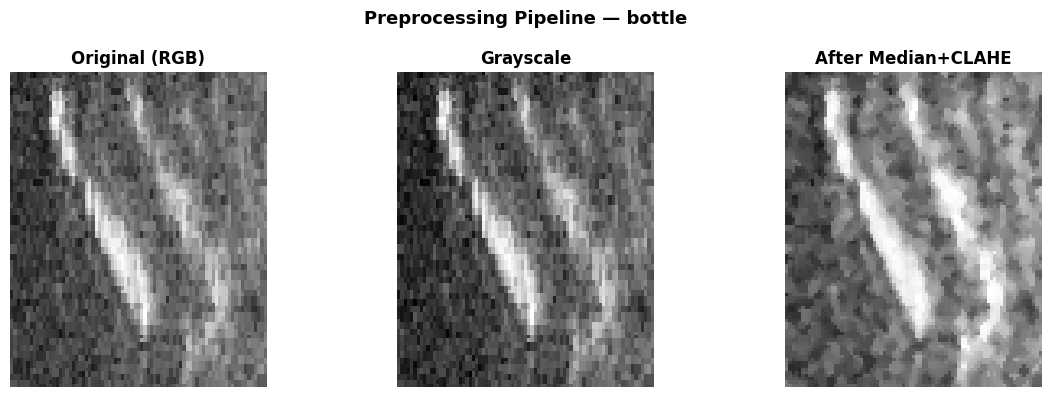

✅ Preprocessing works correctly!


In [14]:
# ── Preprocessing function ───────────────────────────────
def preprocess_sonar(image_path):
    """
    Load and preprocess a single sonar image.
    Handles RGBA → RGB conversion.
    Applies median filter + CLAHE.
    """
    # Load and convert RGBA → RGB
    img = Image.open(image_path).convert('RGB')
    img = np.array(img)

    # Convert to grayscale for filtering
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Step 1: Median filter — removes speckle noise
    denoised = cv2.medianBlur(gray, 3)

    # Step 2: CLAHE — enhances contrast
    clahe     = cv2.createCLAHE(clipLimit=2.0, 
                                  tileGridSize=(8, 8))
    enhanced  = clahe.apply(denoised)

    # Step 3: Convert back to 3 channel RGB
    # ResNet-50 needs 3 channels
    enhanced_rgb = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

    # Step 4: Convert back to PIL for torchvision transforms
    return Image.fromarray(enhanced_rgb)


# ── Test preprocessing on one image ─────────────────────
test_cls  = 'bottle'
test_path = os.path.join(WATER_PATH, test_cls)
test_img  = os.listdir(test_path)[0]
test_full = os.path.join(test_path, test_img)

# Show before and after
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Original
orig = Image.open(test_full).convert('RGB')
axes[0].imshow(orig)
axes[0].set_title('Original (RGB)', fontweight='bold')
axes[0].axis('off')

# Grayscale only
gray_img = cv2.cvtColor(np.array(orig), cv2.COLOR_RGB2GRAY)
axes[1].imshow(gray_img, cmap='gray')
axes[1].set_title('Grayscale', fontweight='bold')
axes[1].axis('off')

# Preprocessed
processed = preprocess_sonar(test_full)
axes[2].imshow(processed, cmap='gray')
axes[2].set_title('After Median+CLAHE', fontweight='bold')
axes[2].axis('off')

plt.suptitle(f'Preprocessing Pipeline — {test_cls}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/preprocessing_example.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Preprocessing works correctly!")

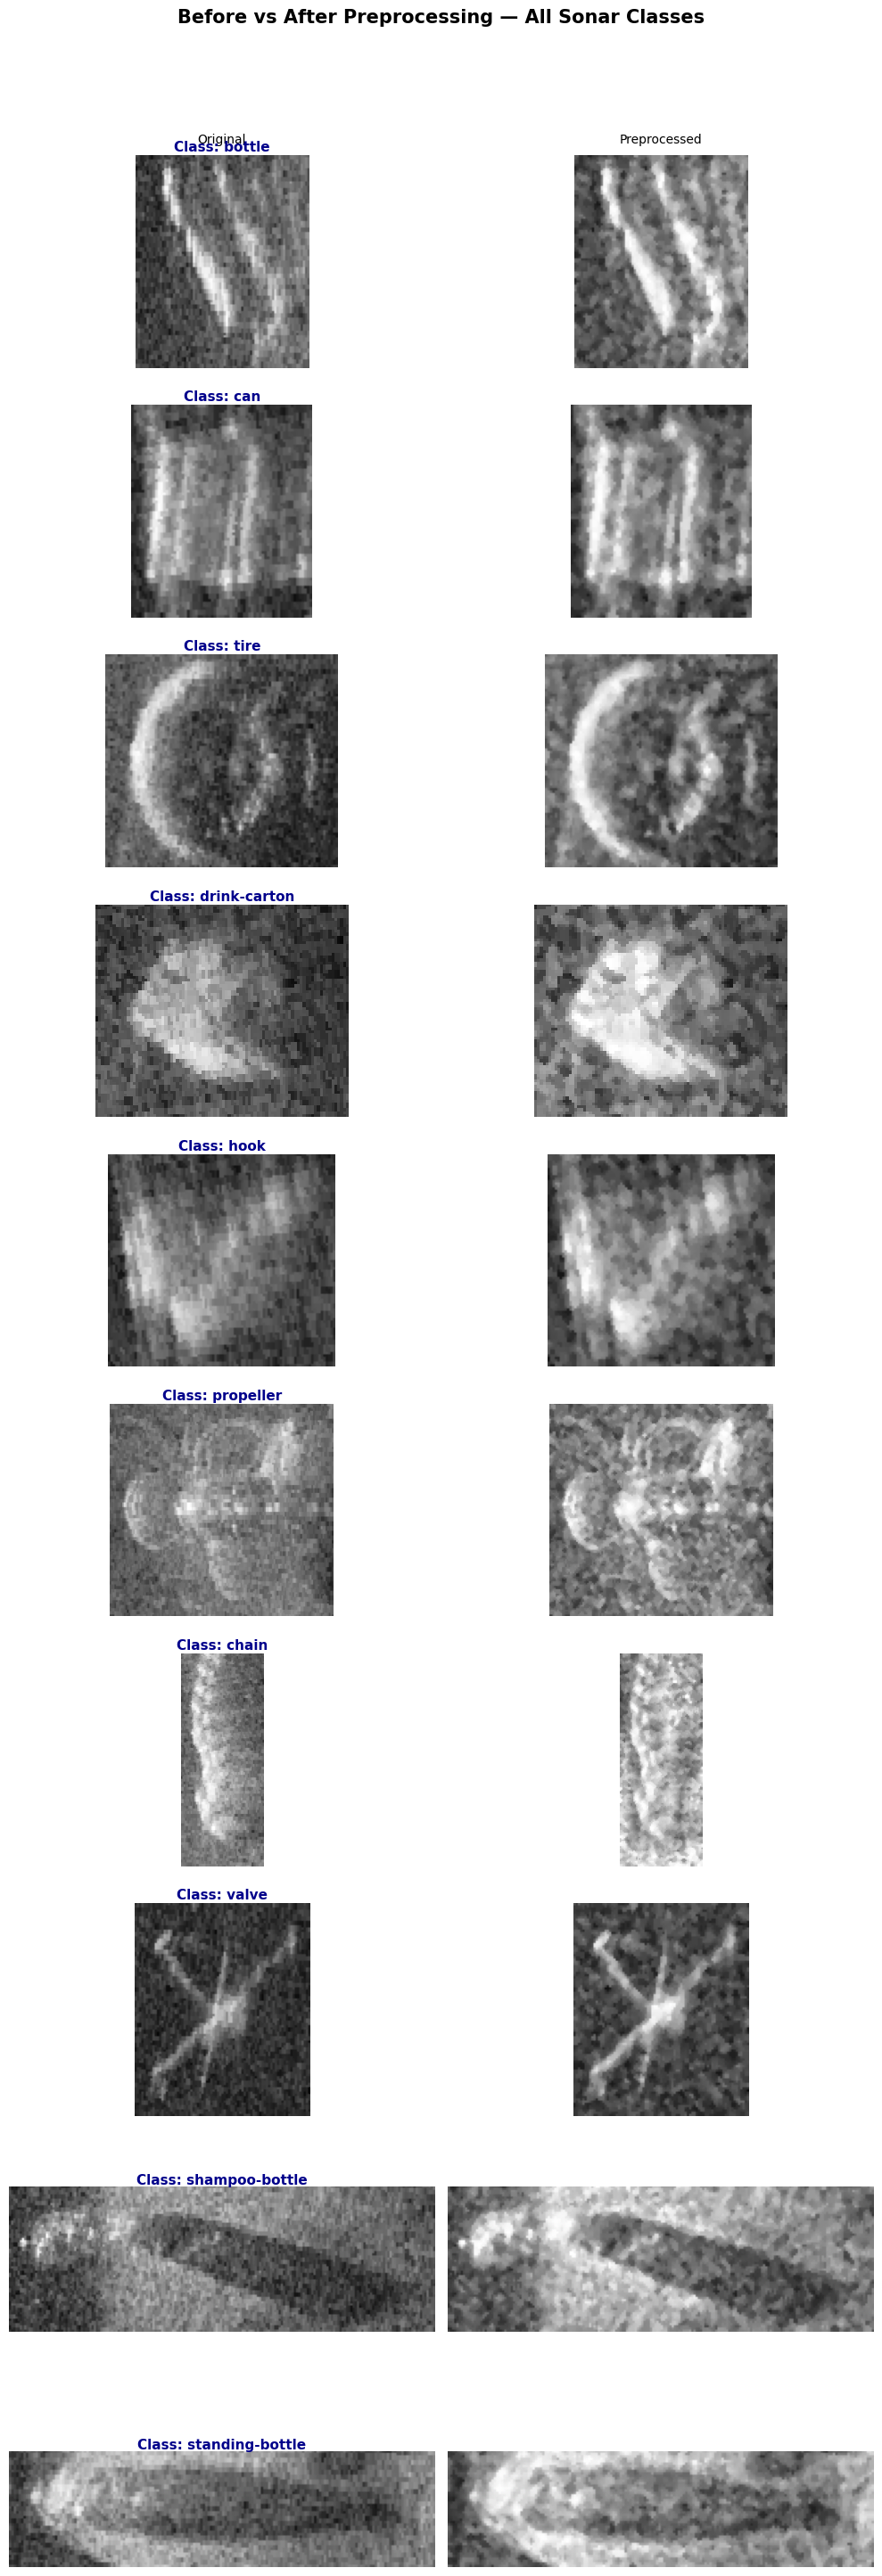

✅ Saved preprocessing_all_classes.png with class names


In [15]:
import matplotlib.pyplot as plt
import os
from PIL import Image

# Combine all classes for the loop
ALL_CLASSES = KNOWN_CLASSES + UNKNOWN_CLASSES

fig, axes = plt.subplots(
    len(ALL_CLASSES), 2, 
    figsize=(10, len(ALL_CLASSES) * 3)
)

for row, cls in enumerate(ALL_CLASSES):
    cls_path = os.path.join(WATER_PATH, cls)
    # Get the first image in the directory
    img_name = os.listdir(cls_path)[0]
    img_path = os.path.join(cls_path, img_name)

    # 1. Original Image
    orig = Image.open(img_path).convert('RGB')
    axes[row][0].imshow(orig)
    axes[row][0].axis('off')
    
    # 2. Preprocessed Image
    proc = preprocess_sonar(img_path)
    axes[row][1].imshow(proc, cmap='gray')
    axes[row][1].axis('off')

    # Add Class Name as a centered label over each row
    # We use text positioning to put the class name in the middle of the two subplots
    fig.text(0.5, 1.02, f"Class: {cls}", transform=axes[row][0].transAxes, 
             ha='center', fontsize=11, fontweight='bold', color='darkblue')

    # Add "Original" and "Preprocessed" labels only for the first row
    if row == 0:
        axes[row][0].set_title('Original', fontsize=10, pad=10)
        axes[row][1].set_title('Preprocessed', fontsize=10, pad=10)

# Set the main title
plt.suptitle('Before vs After Preprocessing — All Sonar Classes', 
             fontsize=15, fontweight='bold', y=0.98)

# The 'rect' parameter reserves space at the top [left, bottom, right, top]
# 0.95 ensures the suptitle doesn't crash into the first row of images
plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3.0)

plt.savefig(f'{FIGURES_DIR}/preprocessing_all_classes.png', 
            dpi=150, bbox_inches='tight')
plt.show()

print("✅ Saved preprocessing_all_classes.png with class names")

In [16]:
# ── ImageNet mean/std (used because ResNet pretrained on ImageNet)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Training transforms (with augmentation) ──────────────
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ── Validation/Test transforms (NO augmentation) ─────────
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("✅ Transforms defined!")
print("\nTraining transforms:")
print("  → Resize to 224x224")
print("  → Random horizontal flip")
print("  → Random vertical flip")
print("  → Random rotation ±15°")
print("  → Color jitter (brightness/contrast)")
print("  → Normalize with ImageNet stats")
print("\nTest transforms:")
print("  → Resize to 224x224")
print("  → Normalize with ImageNet stats")
print("  → NO augmentation")

✅ Transforms defined!

Training transforms:
  → Resize to 224x224
  → Random horizontal flip
  → Random vertical flip
  → Random rotation ±15°
  → Color jitter (brightness/contrast)
  → Normalize with ImageNet stats

Test transforms:
  → Resize to 224x224
  → Normalize with ImageNet stats
  → NO augmentation


In [17]:
class SonarDataset(Dataset):
    """
    PyTorch Dataset for Water Tank FLS Sonar Images.
    Handles RGBA to RGB conversion automatically.
    Applies sonar-specific preprocessing.
    """

    def __init__(self, 
                 data_list, 
                 transform=None,
                 preprocess=True):
        """
        Args:
            data_list  : list of (image_path, label) tuples
                         label = -1 for unknown classes
            transform  : torchvision transforms
            preprocess : apply median filter + CLAHE
        """
        self.data_list  = data_list
        self.transform  = transform
        self.preprocess = preprocess

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        img_path, label = self.data_list[idx]

        # Load image
        if self.preprocess:
            img = preprocess_sonar(img_path)  # median+CLAHE
        else:
            img = Image.open(img_path).convert('RGB')

        # Apply transforms
        if self.transform:
            img = self.transform(img)

        return img, label, img_path  # path useful for debugging


print("✅ SonarDataset class defined!")

✅ SonarDataset class defined!


In [18]:
def create_splits(dataset_path, known_classes,
                  unknown_classes, class_to_idx,
                  train_ratio=0.70,
                  val_ratio=0.15,
                  seed=42):
    """
    Split known classes into train/val/test.
    Unknown classes go entirely into test set.
    """
    random.seed(seed)
    np.random.seed(seed)

    train_list   = []
    val_list     = []
    test_known   = []
    test_unknown = []

    # ── Known classes → split 70/15/15 ───────────────────
    print("Known class splits:")
    print("-" * 50)
    for cls in known_classes:
        cls_path = os.path.join(dataset_path, cls)
        imgs     = sorted([f for f in os.listdir(cls_path)
                           if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])
        random.shuffle(imgs)

        n        = len(imgs)
        n_train  = int(n * train_ratio)
        n_val    = int(n * val_ratio)

        train_imgs = imgs[:n_train]
        val_imgs   = imgs[n_train:n_train + n_val]
        test_imgs  = imgs[n_train + n_val:]

        label = class_to_idx[cls]

        for img in train_imgs:
            train_list.append((os.path.join(cls_path, img), label))
        for img in val_imgs:
            val_list.append((os.path.join(cls_path, img), label))
        for img in test_imgs:
            test_known.append((os.path.join(cls_path, img), label))

        print(f"  {cls:<20} "
              f"train={len(train_imgs):>3} "
              f"val={len(val_imgs):>3} "
              f"test={len(test_imgs):>3}")

    # ── Unknown classes → test only, label = -1 ──────────
    print(f"\nUnknown class (test only):")
    print("-" * 50)
    for cls in unknown_classes:
        cls_path = os.path.join(dataset_path, cls)
        imgs     = sorted([f for f in os.listdir(cls_path)
                           if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])
        for img in imgs:
            test_unknown.append((os.path.join(cls_path, img), -1))
        print(f"  {cls:<20} test={len(imgs):>3}")

    test_list = test_known + test_unknown

    print(f"\n{'='*50}")
    print(f"FINAL SPLIT SUMMARY:")
    print(f"  Train    : {len(train_list):>4} images (known only)")
    print(f"  Val      : {len(val_list):>4} images (known only)")
    print(f"  Test     : {len(test_list):>4} images "
          f"({len(test_known)} known + {len(test_unknown)} unknown)")
    print(f"{'='*50}")

    return train_list, val_list, test_list


# ── Create splits ─────────────────────────────────────────
train_list, val_list, test_list = create_splits(
    WATER_PATH,
    KNOWN_CLASSES,
    UNKNOWN_CLASSES,
    CLASS_TO_IDX
)


Known class splits:
--------------------------------------------------
  bottle               train=314 val= 67 test= 68
  can                  train=256 val= 55 test= 56
  tire                 train=231 val= 49 test= 51
  drink-carton         train=244 val= 52 test= 53
  hook                 train= 93 val= 19 test= 21
  propeller            train= 95 val= 20 test= 22

Unknown class (test only):
--------------------------------------------------
  chain                test=226
  valve                test=208
  shampoo-bottle       test= 99
  standing-bottle      test= 65

FINAL SPLIT SUMMARY:
  Train    : 1233 images (known only)
  Val      :  262 images (known only)
  Test     :  869 images (271 known + 598 unknown)


In [19]:
# ── Create Dataset objects ────────────────────────────────
train_dataset = SonarDataset(train_list, 
                              transform=train_transform,
                              preprocess=True)

val_dataset   = SonarDataset(val_list,
                              transform=test_transform,
                              preprocess=True)

test_dataset  = SonarDataset(test_list,
                              transform=test_transform,
                              preprocess=True)

# ── Compute class weights for imbalanced training ─────────
label_list   = [label for _, label in train_list]
class_counts_train = Counter(label_list)
total_train  = len(label_list)

weights = []
for idx in range(NUM_CLASSES):
    count = class_counts_train.get(idx, 1)
    weights.append(total_train / (NUM_CLASSES * count))

CLASS_WEIGHTS_TENSOR = torch.FloatTensor(weights)
print("Class weights for loss function:")
for cls, w in zip(KNOWN_CLASSES, weights):
    print(f"  {cls:<20} weight = {w:.3f}")

# ── Create DataLoaders ────────────────────────────────────
BATCH_SIZE  = 32
NUM_WORKERS = 0 if os.name == 'nt' else 2
PIN_MEMORY  = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print(f"\n✅ DataLoaders created!")
print(f"  Train batches : {len(train_loader)}")
print(f"  Val batches   : {len(val_loader)}")
print(f"  Test batches  : {len(test_loader)}")
print(f"  Batch size    : {BATCH_SIZE}")


Class weights for loss function:
  bottle               weight = 0.654
  can                  weight = 0.803
  tire                 weight = 0.890
  drink-carton         weight = 0.842
  hook                 weight = 2.210
  propeller            weight = 2.163

✅ DataLoaders created!
  Train batches : 39
  Val batches   : 9
  Test batches  : 28
  Batch size    : 32


Batch verification:
  Image tensor shape : torch.Size([32, 3, 224, 224])
  Labels             : [0, 3, 0, 0, 3, 0, 3, 3, 4, 2, 1, 1, 0, 3, 4, 1, 0, 2, 1, 3, 1, 2, 4, 1, 1, 3, 2, 3, 5, 2, 2, 3]
  Label names        : ['bottle', 'drink-carton', 'bottle', 'bottle', 'drink-carton', 'bottle']
  Min pixel value    : -2.118
  Max pixel value    : 2.640


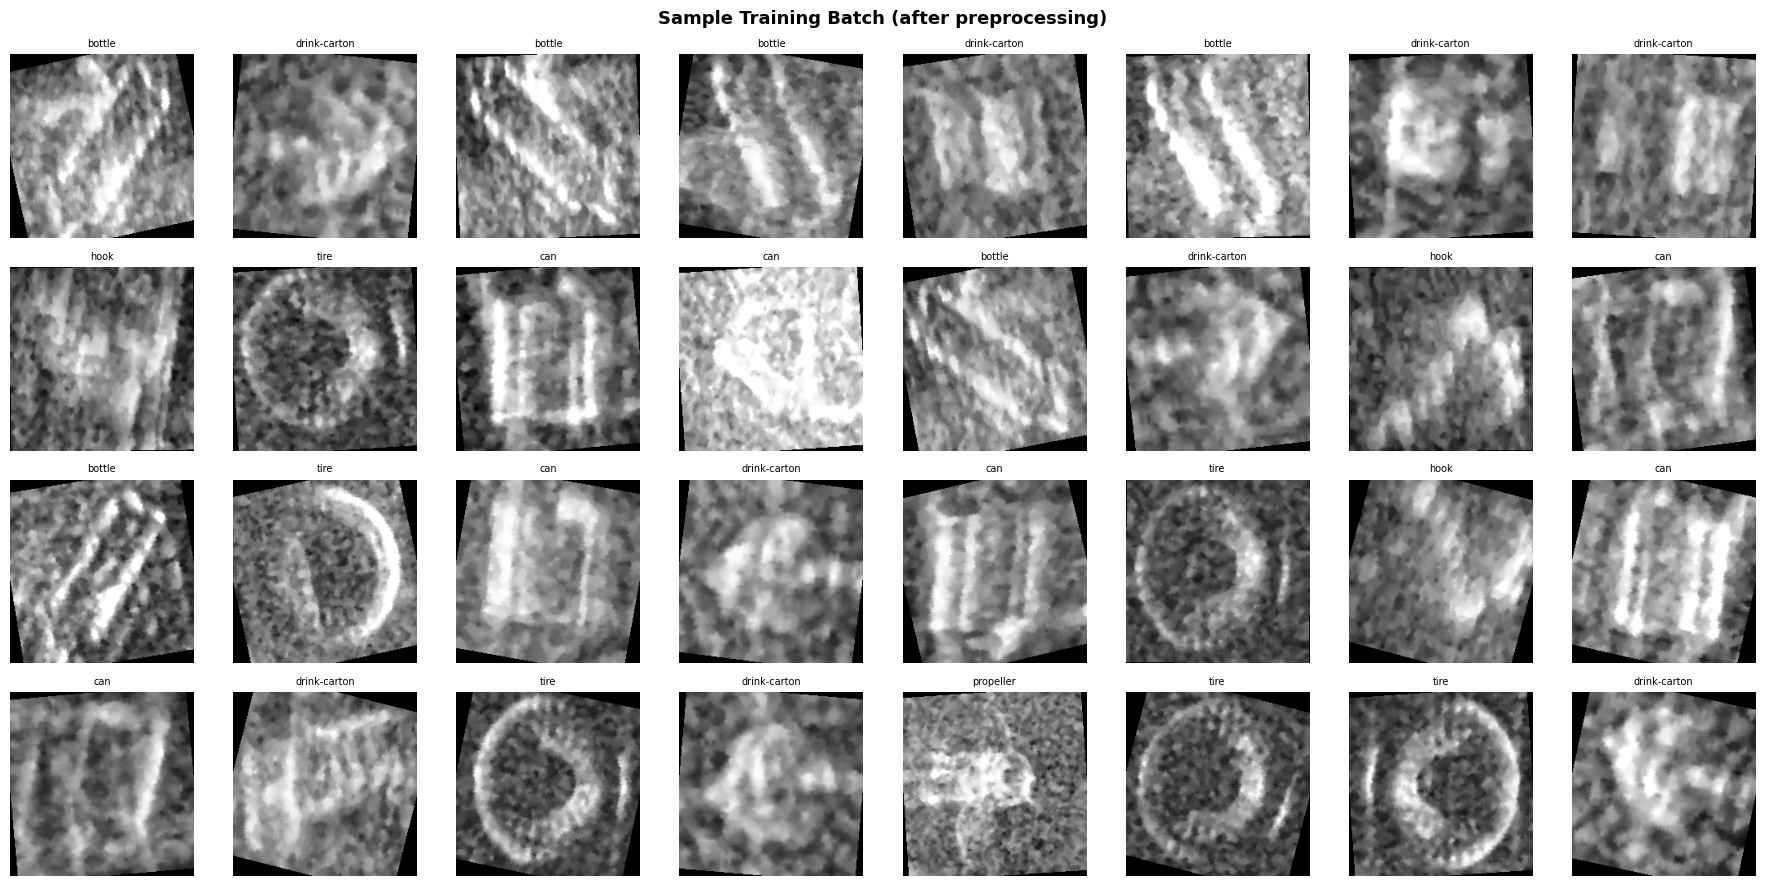

✅ DataLoader working correctly!


In [20]:
# ── Load one batch and verify ─────────────────────────────
images, labels, paths = next(iter(train_loader))

print("Batch verification:")
print(f"  Image tensor shape : {images.shape}")
print(f"  Labels             : {labels.tolist()}")
print(f"  Label names        : "
      f"{[IDX_TO_CLASS[l.item()] for l in labels[:6]]}")
print(f"  Min pixel value    : {images.min():.3f}")
print(f"  Max pixel value    : {images.max():.3f}")

# ── Visualize one batch ───────────────────────────────────
fig, axes = plt.subplots(4, 8, figsize=(18, 9))
axes      = axes.flatten()

# Denormalize for display
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

for i in range(min(32, len(images))):
    img = images[i] * std + mean  # denormalize
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    axes[i].imshow(img[:, :, 0], cmap='gray')
    axes[i].set_title(IDX_TO_CLASS[labels[i].item()],
                      fontsize=7)
    axes[i].axis('off')

plt.suptitle('Sample Training Batch (after preprocessing)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/sample_batch.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ DataLoader working correctly!")

# **Base Line RASNET model**

1. **Build ResNet-50**

In [21]:
import torchvision.models as models
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
import time
import copy

# ── Build ResNet-50 ───────────────────────────────────────
def build_resnet50(num_classes, pretrained=True):
    """
    Load pretrained ResNet-50 and replace
    final layer for our number of classes.
    """
    model = models.resnet50(
        weights=models.ResNet50_Weights.IMAGENET1K_V1
        if pretrained else None
    )

    # Freeze early layers (optional but helps with small data)
    for name, param in model.named_parameters():
        if 'layer1' in name or 'layer2' in name:
            param.requires_grad = False

    # Replace final FC layer
    in_features  = model.fc.in_features  # 2048
    model.fc     = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(512, num_classes)
    )

    return model


DEVICE = torch.device('cuda' if torch.cuda.is_available()
                       else 'cpu')

model  = build_resnet50(num_classes=NUM_CLASSES)
model  = model.to(DEVICE)

# ── Count parameters ──────────────────────────────────────
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters()
                       if p.requires_grad)

print("✅ ResNet-50 built successfully!")
print(f"\n  Device           : {DEVICE}")
print(f"  Total params     : {total_params:,}")
print(f"  Trainable params : {trainable_params:,}")
print(f"  Frozen params    : {total_params-trainable_params:,}")
print(f"\n  Input  : (batch, 3, 224, 224)")
print(f"  Output : (batch, {NUM_CLASSES})  ← one score per known class")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 228MB/s]


✅ ResNet-50 built successfully!

  Device           : cuda
  Total params     : 24,560,198
  Trainable params : 23,124,806
  Frozen params    : 1,435,392

  Input  : (batch, 3, 224, 224)
  Output : (batch, 6)  ← one score per known class


**2. Early Stoppage**

In [22]:
class EarlyStopping:
    def __init__(self, patience=5,
                 min_delta=0.001,
                 mode='max'):
        self.patience   = patience
        self.min_delta  = min_delta
        self.mode       = mode
        self.counter    = 0
        self.best_score = None
        self.stop       = False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False

        if self.mode == 'max':
            improved = score >= self.best_score + self.min_delta
        else:
            improved = score <= self.best_score - self.min_delta

        if improved:
            self.best_score = score
            self.counter    = 0
        else:
            self.counter += 1
            print(f"     ⏳ EarlyStopping: "
                  f"{self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.stop = True

        return self.stop

print("✅ EarlyStopping ready!")

✅ EarlyStopping ready!


**3.Trainer Class**

In [23]:
import copy
import time
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class Trainer:
    def __init__(self, model, optimizer,
                 criterion, scheduler,
                 device, save_dir):

        self.model     = model
        self.optimizer = optimizer
        self.criterion = criterion
        self.scheduler = scheduler
        self.device    = device
        self.save_dir  = save_dir
        self.history   = {
            'train_loss': [], 'train_acc': [],
            'val_loss'  : [], 'val_acc'  : []
        }
        self.best_val_acc = 0.0
        self.best_weights = None

    def train_epoch(self, loader):
        self.model.train()
        running_loss = 0.0
        correct = 0
        total   = 0

        for images, labels, _ in loader:
            images = images.to(self.device)
            labels = labels.to(self.device)

            self.optimizer.zero_grad()
            outputs = self.model(images)
            loss    = self.criterion(outputs, labels)
            loss.backward()
            self.optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted  = outputs.max(1)
            total        += labels.size(0)
            correct      += predicted.eq(labels).sum().item()

        return running_loss/total, 100.*correct/total

    def val_epoch(self, loader):
        self.model.eval()
        running_loss = 0.0
        correct = 0
        total   = 0

        with torch.no_grad():
            for images, labels, _ in loader:
                images  = images.to(self.device)
                labels  = labels.to(self.device)
                outputs = self.model(images)
                loss    = self.criterion(outputs, labels)

                running_loss += loss.item() * images.size(0)
                _, predicted  = outputs.max(1)
                total        += labels.size(0)
                correct      += predicted.eq(labels).sum().item()

        return running_loss/total, 100.*correct/total

    def fit(self, train_loader, val_loader,
            num_epochs, model_name='model',
            patience=5):
    
        early_stopping = EarlyStopping(
            patience=patience,
            min_delta=0.001,
            mode='max'
        )
    
        print(f"Training {model_name}...")
        print(f"Early stopping patience: {patience} epochs")
        print("=" * 65)
        print(f"{'Epoch':>6} {'T-Loss':>8} {'T-Acc':>8}"
              f" {'V-Loss':>8} {'V-Acc':>8} {'Time':>6}")
        print("-" * 65)
    
        for epoch in range(1, num_epochs + 1):
            start = time.time()
    
            t_loss, t_acc = self.train_epoch(train_loader)
            v_loss, v_acc = self.val_epoch(val_loader)
            self.scheduler.step()
    
            self.history['train_loss'].append(t_loss)
            self.history['train_acc'].append(t_acc)
            self.history['val_loss'].append(v_loss)
            self.history['val_acc'].append(v_acc)
    
            saved = ""
            if v_acc > self.best_val_acc:
                self.best_val_acc = v_acc
                self.best_weights = copy.deepcopy(
                    self.model.state_dict()
                )
                torch.save(
                    self.best_weights,
                    f'{self.save_dir}/{model_name}_best.pth'
                )
                saved = "✅"
    
            elapsed = time.time() - start
            print(f"{epoch:>6} {t_loss:>8.4f} {t_acc:>7.2f}%"
                  f" {v_loss:>8.4f} {v_acc:>7.2f}%"
                  f" {elapsed:>5.1f}s {saved}")
    
            if early_stopping(v_acc):
                print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
                print(f"   No improvement for {patience} epochs")
                break
    
        self.model.load_state_dict(self.best_weights)
        print("=" * 65)
        print(f"\n✅ Done! Best Val Acc : {self.best_val_acc:.2f}%")
        print(f"   Stopped at epoch  : {epoch}/{num_epochs}")
        return self.history

    def plot_history(self, model_name='model'):
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        epochs    = range(1, len(self.history['train_loss'])+1)

        axes[0].plot(epochs, self.history['train_loss'],
                     'steelblue', label='Train', linewidth=2)
        axes[0].plot(epochs, self.history['val_loss'],
                     'tomato', label='Val',
                     linewidth=2, linestyle='--')
        axes[0].set_title('Loss', fontweight='bold')
        axes[0].set_xlabel('Epoch')
        axes[0].legend()
        axes[0].grid(alpha=0.3)

        axes[1].plot(epochs, self.history['train_acc'],
                     'steelblue', label='Train', linewidth=2)
        axes[1].plot(epochs, self.history['val_acc'],
                     'tomato', label='Val',
                     linewidth=2, linestyle='--')
        axes[1].axhline(
            y=self.best_val_acc,
            color='green', linestyle=':',
            label=f'Best: {self.best_val_acc:.1f}%'
        )
        axes[1].set_title('Accuracy', fontweight='bold')
        axes[1].set_xlabel('Epoch')
        axes[1].legend()
        axes[1].grid(alpha=0.3)

        plt.suptitle(f'{model_name} Training Curves',
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(
            f'{FIGURES_DIR}/{model_name}_curves.png',
            dpi=150, bbox_inches='tight'
        )
        plt.show()

    def evaluate(self, test_loader, class_names):
        self.model.eval()
        all_preds  = []
        all_labels = []
        all_probs  = []

        with torch.no_grad():
            for images, labels, _ in test_loader:
                images  = images.to(self.device)
                outputs = self.model(images)
                probs   = torch.softmax(outputs, dim=1)
                _, preds = outputs.max(1)

                for i in range(len(labels)):
                    if labels[i].item() != -1:
                        all_preds.append(preds[i].item())
                        all_labels.append(labels[i].item())
                        all_probs.append(
                            probs[i].cpu().numpy()
                        )

        print("Closed-Set Classification Report:")
        print("=" * 55)
        print(classification_report(
            all_labels, all_preds,
            target_names=class_names
        ))

        # Confusion matrix
        cm  = confusion_matrix(all_labels, all_preds)
        fig, ax = plt.subplots(figsize=(8, 7))
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=class_names
        )
        disp.plot(ax=ax, cmap='Blues',
                  xticks_rotation=30)
        ax.set_title(
            'Confusion Matrix — Baseline',
            fontsize=13, fontweight='bold'
        )
        plt.tight_layout()
        plt.savefig(
            f'{FIGURES_DIR}/confusion_matrix_baseline.png',
            dpi=150, bbox_inches='tight'
        )
        plt.show()

        return all_labels, all_preds, all_probs

print("✅ Trainer class ready!")

✅ Trainer class ready!


Training resnet50_baseline...
Early stopping patience: 5 epochs
 Epoch   T-Loss    T-Acc   V-Loss    V-Acc   Time
-----------------------------------------------------------------
     1   1.0109   68.78%   0.3107   88.93%  16.2s ✅
     2   0.2119   92.54%   0.1346   95.04%  11.9s ✅
     3   0.1492   95.05%   0.0782   98.09%  12.1s ✅
     4   0.0985   96.43%   0.0958   96.18%  12.0s 
     ⏳ EarlyStopping: 1/5
     5   0.1041   96.59%   0.0574   98.09%  12.2s 
     ⏳ EarlyStopping: 2/5
     6   0.0899   97.08%   0.0308   98.85%  12.6s ✅
     7   0.0375   98.70%   0.0188   99.24%  12.8s ✅
     8   0.0203   99.19%   0.0393   98.85%  12.9s 
     ⏳ EarlyStopping: 1/5
     9   0.0173   99.43%   0.0431   98.85%  13.3s 
     ⏳ EarlyStopping: 2/5
    10   0.0183   99.59%   0.0399   98.47%  13.0s 
     ⏳ EarlyStopping: 3/5
    11   0.0201   99.19%   0.0218   99.24%  12.8s 
     ⏳ EarlyStopping: 4/5
    12   0.0126   99.68%   0.0270   99.24%  12.7s 
     ⏳ EarlyStopping: 5/5

🛑 Early stopping tri

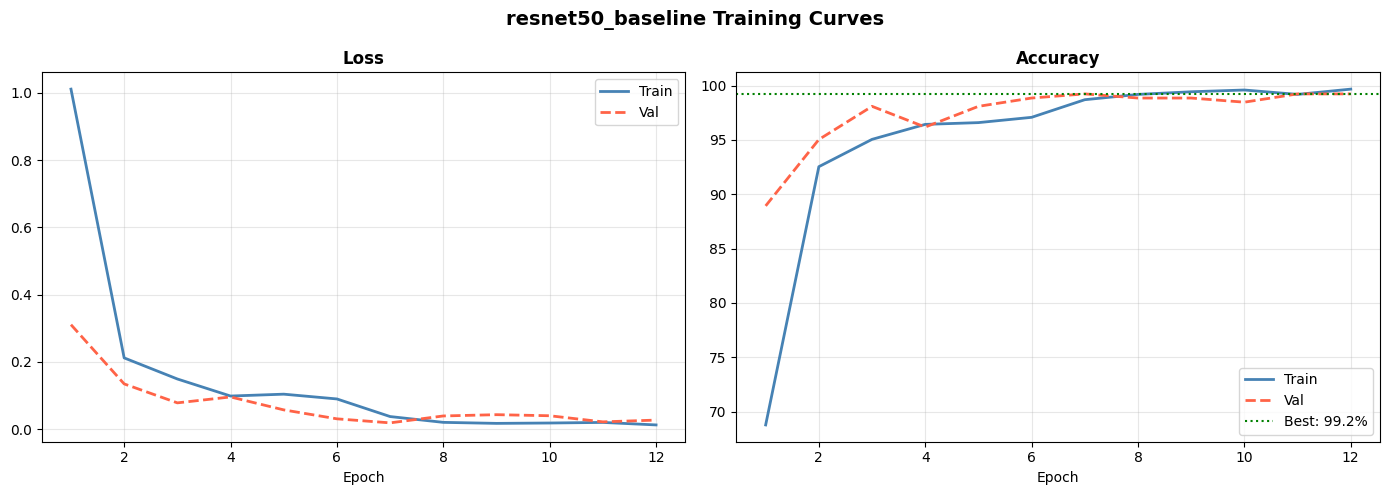

Closed-Set Classification Report:
              precision    recall  f1-score   support

      bottle       1.00      0.99      0.99        68
         can       0.98      1.00      0.99        56
        tire       0.98      1.00      0.99        51
drink-carton       1.00      1.00      1.00        53
        hook       1.00      1.00      1.00        21
   propeller       1.00      0.95      0.98        22

    accuracy                           0.99       271
   macro avg       0.99      0.99      0.99       271
weighted avg       0.99      0.99      0.99       271



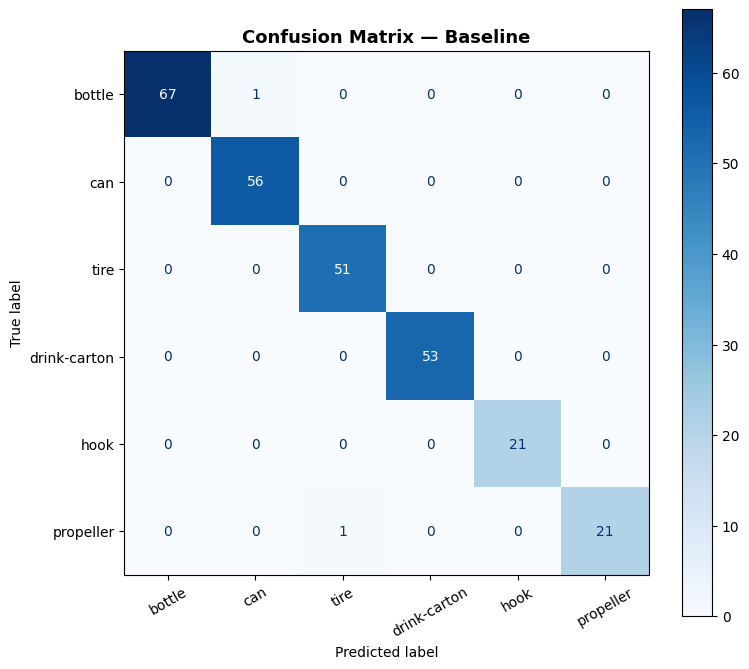

In [24]:
# ── Fresh model ───────────────────────────────────────────
model     = build_resnet50(NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS_TENSOR.to(DEVICE)
)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad,
           model.parameters()),
    lr=1e-4, weight_decay=1e-4
)
scheduler = StepLR(optimizer, step_size=7, gamma=0.5)

# ── Trainer ───────────────────────────────────────────────
trainer = Trainer(
    model     = model,
    optimizer = optimizer,
    criterion = criterion,
    scheduler = scheduler,
    device    = DEVICE,
    save_dir  = MODEL_DIR
)

# ── Train with early stopping ─────────────────────────────
history = trainer.fit(
    train_loader,
    val_loader,
    num_epochs = 30,
    model_name = 'resnet50_baseline',
    patience   = 5
)

# ── Plot + Evaluate ───────────────────────────────────────
trainer.plot_history('resnet50_baseline')
labels, preds, probs = trainer.evaluate(
    test_loader,
    KNOWN_CLASSES
)

**Checking for data leakage**

In [25]:
# ── Check for data leakage ────────────────────────────────
train_paths = set(path for path, _ in train_list)
val_paths   = set(path for path, _ in val_list)
test_paths  = set(path for path, _ in test_list)

train_val_overlap  = train_paths & val_paths
train_test_overlap = train_paths & test_paths
val_test_overlap   = val_paths   & test_paths

print("Data Leakage Check:")
print("=" * 40)
print(f"Train ∩ Val  overlap : {len(train_val_overlap)}")
print(f"Train ∩ Test overlap : {len(train_test_overlap)}")
print(f"Val   ∩ Test overlap : {len(val_test_overlap)}")

if (len(train_val_overlap) == 0 and
    len(train_test_overlap) == 0 and
    len(val_test_overlap) == 0):
    print("\n✅ No leakage — splits are clean!")
else:
    print("\n❌ LEAKAGE FOUND — need to fix splits!")

Data Leakage Check:
Train ∩ Val  overlap : 0
Train ∩ Test overlap : 0
Val   ∩ Test overlap : 0

✅ No leakage — splits are clean!


In [26]:
# ── Is val set too small? ─────────────────────────────────
print("Split sizes per class:")
print("=" * 50)

val_labels   = [label for _, label in val_list]
from collections import Counter
val_counts   = Counter(val_labels)

for idx, cls in IDX_TO_CLASS.items():
    count = val_counts.get(idx, 0)
    print(f"  {cls:<20} → {count} val images")

print(f"\nTotal val images: {len(val_list)}")
print(f"\nIf any class has <10 val images")
print(f"→ 100% acc is not meaningful")

Split sizes per class:
  bottle               → 67 val images
  can                  → 55 val images
  tire                 → 49 val images
  drink-carton         → 52 val images
  hook                 → 19 val images
  propeller            → 20 val images

Total val images: 262

If any class has <10 val images
→ 100% acc is not meaningful


# **MSP thresolg based OSR**

**1. Extract Softmax Scores for All Test Images**

In [27]:
import numpy as np
from sklearn.metrics import (roc_curve, auc,
                              precision_recall_curve,
                              average_precision_score)
import matplotlib.pyplot as plt

# ── Extract MSP scores from test set ─────────────────────
def extract_msp_scores(model, loader, device):
    """
    Extract maximum softmax probability scores
    for all images in loader.
    
    Returns:
        msp_scores : max softmax score per image
        true_labels: original labels (-1 for unknown)
        predictions: predicted class index
    """
    model.eval()
    msp_scores  = []
    true_labels = []
    predictions = []
    all_probs   = []

    with torch.no_grad():
        for images, labels, _ in loader:
            images  = images.to(device)
            outputs = model(images)
            probs   = torch.softmax(outputs, dim=1)

            # Maximum softmax probability
            max_probs, pred = probs.max(dim=1)

            msp_scores.extend(max_probs.cpu().numpy())
            true_labels.extend(labels.numpy())
            predictions.extend(pred.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return (np.array(msp_scores),
            np.array(true_labels),
            np.array(predictions),
            np.array(all_probs))


# ── Run extraction ────────────────────────────────────────
msp_scores, true_labels, predictions, all_probs = \
    extract_msp_scores(model, test_loader, DEVICE)

print("MSP Score Extraction Complete:")
print("=" * 45)
print(f"  Total test images : {len(msp_scores)}")
print(f"  Known images      : {(true_labels != -1).sum()}")
print(f"  Unknown images    : {(true_labels == -1).sum()}")
print(f"\nMSP Score Statistics:")
print(f"  Known   - Mean: "
      f"{msp_scores[true_labels != -1].mean():.4f}  "
      f"Min: {msp_scores[true_labels != -1].min():.4f}")
print(f"  Unknown - Mean: "
      f"{msp_scores[true_labels == -1].mean():.4f}  "
      f"Min: {msp_scores[true_labels == -1].min():.4f}")

MSP Score Extraction Complete:
  Total test images : 869
  Known images      : 271
  Unknown images    : 598

MSP Score Statistics:
  Known   - Mean: 0.9908  Min: 0.5386
  Unknown - Mean: 0.8083  Min: 0.2931


**2. Visualize MSP Score Distributions**

/tmp/ipykernel_50/1351701637.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(
/tmp/ipykernel_50/1351701637.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(


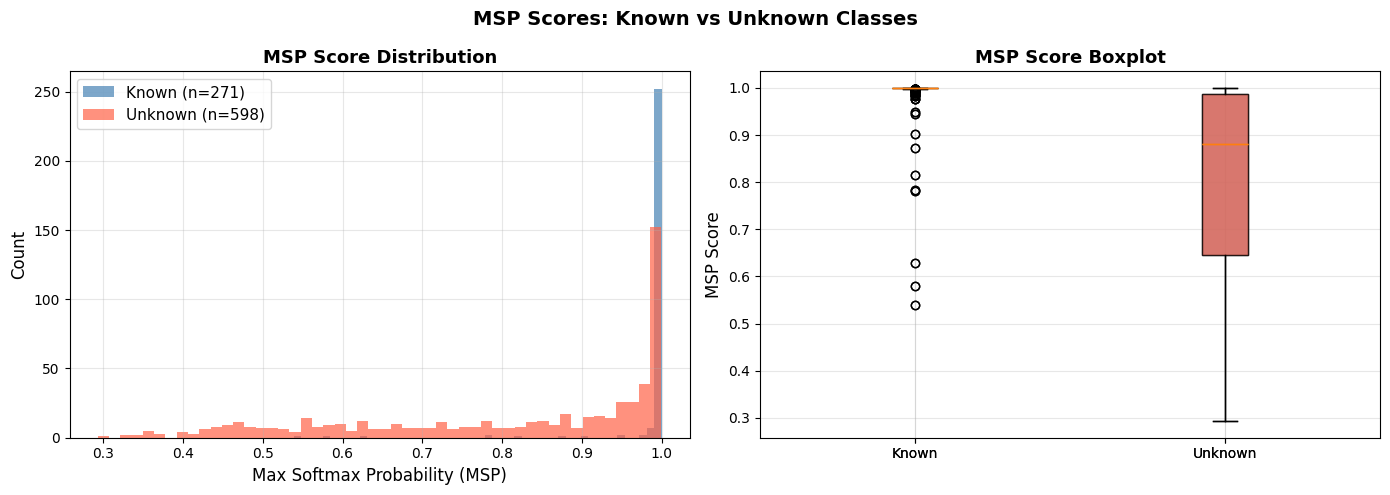

✅ Saved msp_distributions.png


In [28]:
# ── Separate known and unknown scores ─────────────────────
known_scores   = msp_scores[true_labels != -1]
unknown_scores = msp_scores[true_labels == -1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Histogram ─────────────────────────────────────────────
axes[0].hist(known_scores, bins=50,
             alpha=0.7, color='steelblue',
             label=f'Known (n={len(known_scores)})',
             edgecolor='none')
axes[0].hist(unknown_scores, bins=50,
             alpha=0.7, color='tomato',
             label=f'Unknown (n={len(unknown_scores)})',
             edgecolor='none')
axes[0].set_xlabel('Max Softmax Probability (MSP)',
                    fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('MSP Score Distribution',
                   fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# ── Box plot ──────────────────────────────────────────────
axes[1].boxplot(
    [known_scores, unknown_scores],
    labels=['Known', 'Unknown'],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.7),
)
# Color unknown box red
bp = axes[1].boxplot(
    [known_scores, unknown_scores],
    labels=['Known', 'Unknown'],
    patch_artist=True
)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][1].set_facecolor('tomato')
for box in bp['boxes']:
    box.set_alpha(0.7)

axes[1].set_ylabel('MSP Score', fontsize=12)
axes[1].set_title('MSP Score Boxplot',
                   fontsize=13, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.suptitle('MSP Scores: Known vs Unknown Classes',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_distributions.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved msp_distributions.png")

**3. Find Best Threshold τ**

In [29]:
# ── Convert to binary problem ─────────────────────────────
# Known = 1, Unknown = 0
binary_labels = (true_labels != -1).astype(int)

# ── ROC Curve ─────────────────────────────────────────────
fpr, tpr, thresholds = roc_curve(
    binary_labels, msp_scores
)
roc_auc = auc(fpr, tpr)

# ── Find best threshold at 95% TPR ────────────────────────
target_tpr  = 0.95
idx_95      = np.argmin(np.abs(tpr - target_tpr))
thresh_95   = thresholds[idx_95]
fpr_at_95   = fpr[idx_95]

# ── Find optimal threshold (Youden's J) ───────────────────
j_scores    = tpr - fpr
best_idx    = np.argmax(j_scores)
best_thresh = thresholds[best_idx]
best_tpr    = tpr[best_idx]
best_fpr    = fpr[best_idx]

print("Threshold Analysis:")
print("=" * 50)
print(f"  AUROC              : {roc_auc:.4f}")
print(f"\n  Best threshold (Youden's J):")
print(f"    τ = {best_thresh:.4f}")
print(f"    TPR = {best_tpr:.4f}")
print(f"    FPR = {best_fpr:.4f}")
print(f"\n  Threshold at 95% TPR:")
print(f"    τ   = {thresh_95:.4f}")
print(f"    FPR = {fpr_at_95:.4f}")
print(f"    TPR = {tpr[idx_95]:.4f}")

# Save threshold
BEST_THRESHOLD_MSP = best_thresh
print(f"\n✅ Using τ = {BEST_THRESHOLD_MSP:.4f} for MSP")

Threshold Analysis:
  AUROC              : 0.9069

  Best threshold (Youden's J):
    τ = 0.9980
    TPR = 0.8708
    FPR = 0.1455

  Threshold at 95% TPR:
    τ   = 0.9849
    FPR = 0.2592
    TPR = 0.9483

✅ Using τ = 0.9980 for MSP


**4. Plot ROC Curve**

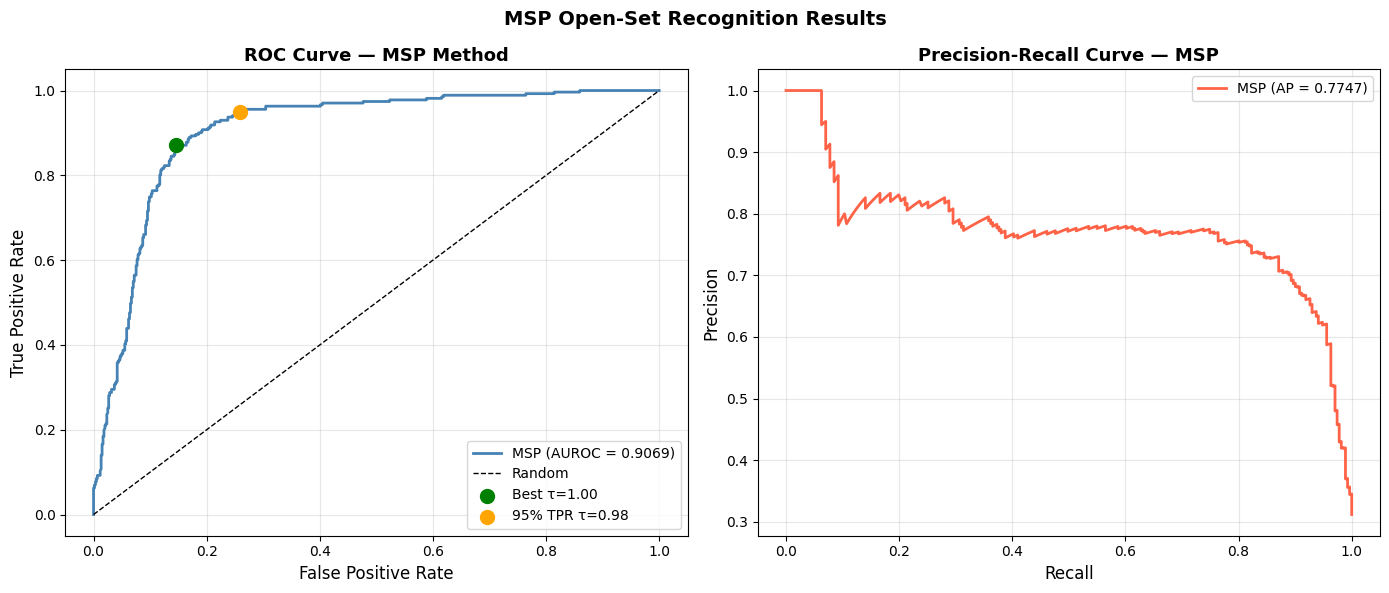

✅ Saved msp_roc_pr_curves.png


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── ROC Curve ─────────────────────────────────────────────
axes[0].plot(fpr, tpr,
             color='steelblue', linewidth=2,
             label=f'MSP (AUROC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1],
             'k--', linewidth=1, label='Random')
axes[0].scatter(best_fpr, best_tpr,
                color='green', s=100, zorder=5,
                label=f'Best τ={best_thresh:.2f}')
axes[0].scatter(fpr_at_95, tpr[idx_95],
                color='orange', s=100, zorder=5,
                label=f'95% TPR τ={thresh_95:.2f}')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve — MSP Method',
                   fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# ── Precision Recall Curve ────────────────────────────────
precision, recall, _ = precision_recall_curve(
    binary_labels, msp_scores
)
ap = average_precision_score(binary_labels, msp_scores)

axes[1].plot(recall, precision,
             color='tomato', linewidth=2,
             label=f'MSP (AP = {ap:.4f})')
axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curve — MSP',
                   fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.suptitle('MSP Open-Set Recognition Results',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_roc_pr_curves.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved msp_roc_pr_curves.png")

**5.Aplying MSP Threshold**

In [31]:
# ── Apply threshold and evaluate ──────────────────────────
def evaluate_osr(msp_scores, true_labels,
                 threshold, method_name):
    """
    Apply threshold and compute OSR metrics.
    Known  = score >= threshold
    Unknown= score <  threshold
    """
    binary_labels    = (true_labels != -1).astype(int)
    predicted_known  = (msp_scores >= threshold).astype(int)

    TP = int(((predicted_known == 1) & (binary_labels == 1)).sum())
    TN = int(((predicted_known == 0) & (binary_labels == 0)).sum())
    FP = int(((predicted_known == 1) & (binary_labels == 0)).sum())
    FN = int(((predicted_known == 0) & (binary_labels == 1)).sum())

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0.0
    UDR = TN / (TN + FP) if (TN + FP) > 0 else 0.0

    fpr_arr, tpr_arr, _ = roc_curve(binary_labels, msp_scores)
    auroc = float(auc(fpr_arr, tpr_arr))
    ap    = float(average_precision_score(binary_labels, msp_scores))

    print(f"\n{method_name} OSR Results:")
    print("=" * 45)
    print(f"  Threshold (τ)    : {threshold:.4f}")
    print(f"  AUROC            : {auroc:.4f}")
    print(f"  Average Precision: {ap:.4f}")
    print(f"  TPR (known acc)  : {TPR:.4f}")
    print(f"  FPR (false alarm): {FPR:.4f}")
    print(f"  UDR (unk detect) : {UDR:.4f}")
    print(f"\n  Confusion:")
    print(f"    TP={TP} TN={TN} FP={FP} FN={FN}")

    return {
        'method'   : method_name,
        'threshold': float(threshold),
        'auroc'    : auroc,
        'ap'       : ap,
        'tpr'      : float(TPR),
        'fpr'      : float(FPR),
        'udr'      : float(UDR),
        'tp'       : TP,
        'tn'       : TN,
        'fp'       : FP,
        'fn'       : FN,
        'fpr_arr'  : fpr_arr,
        'tpr_arr'  : tpr_arr,
        'scores'   : msp_scores,
    }


# ── Evaluate MSP with best threshold ─────────────────────
msp_results = evaluate_osr(
    msp_scores,
    true_labels,
    BEST_THRESHOLD_MSP,
    'MSP Threshold'
)

print("\n✅ MSP evaluation complete!")



MSP Threshold OSR Results:
  Threshold (τ)    : 0.9980
  AUROC            : 0.9069
  Average Precision: 0.7747
  TPR (known acc)  : 0.8708
  FPR (false alarm): 0.1455
  UDR (unk detect) : 0.8545

  Confusion:
    TP=236 TN=511 FP=87 FN=35

✅ MSP evaluation complete!


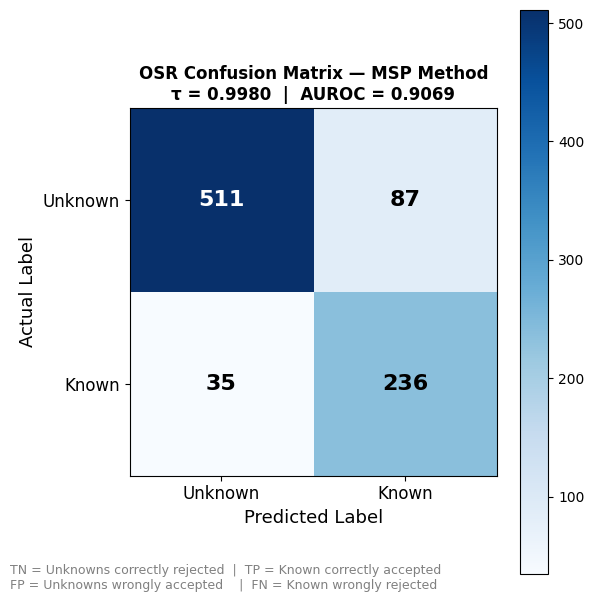

✅ Saved msp_osr_confusion_matrix.png


In [32]:
# ── OSR Decision for each image ───────────────────────────
binary_labels   = (true_labels != -1).astype(int)
predicted_known = (msp_scores >= BEST_THRESHOLD_MSP).astype(int)

# OSR Confusion Matrix
# Rows = Actual, Cols = Predicted
# Known→Known, Known→Unknown, Unknown→Known, Unknown→Unknown

osr_cm = confusion_matrix(binary_labels, predicted_known)

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(osr_cm, interpolation='nearest',
               cmap='Blues')
plt.colorbar(im)

# Labels
classes = ['Unknown', 'Known']
tick_marks = [0, 1]
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)
ax.set_xticklabels(classes, fontsize=12)
ax.set_yticklabels(classes, fontsize=12)

# Add numbers inside cells
thresh_cm = osr_cm.max() / 2
for i in range(2):
    for j in range(2):
        color = 'white' if osr_cm[i,j] > thresh_cm else 'black'
        ax.text(j, i, f'{osr_cm[i,j]}',
                ha='center', va='center',
                fontsize=16, fontweight='bold',
                color=color)

ax.set_ylabel('Actual Label', fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=13)
ax.set_title(
    f'OSR Confusion Matrix — MSP Method\n'
    f'τ = {BEST_THRESHOLD_MSP:.4f}  |  '
    f'AUROC = {msp_results["auroc"]:.4f}',
    fontsize=12, fontweight='bold'
)

# Add interpretation text
fig.text(.01, .01,
    'TN = Unknowns correctly rejected  |  '
    'TP = Known correctly accepted\n'
    'FP = Unknowns wrongly accepted    |  '
    'FN = Known wrongly rejected',
    fontsize=9, color='gray')

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_osr_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved msp_osr_confusion_matrix.png")

**Per Unknown Class Detection Rate**

Unknown Class Detection Analysis (MSP):
Class                 Total  Rejected  Detection%
-------------------------------------------------------
  chain                   226       150       66.4%  █████████████
  valve                   208       197       94.7%  ██████████████████
  shampoo-bottle           99        99      100.0%  ████████████████████
  standing-bottle          65        65      100.0%  ████████████████████


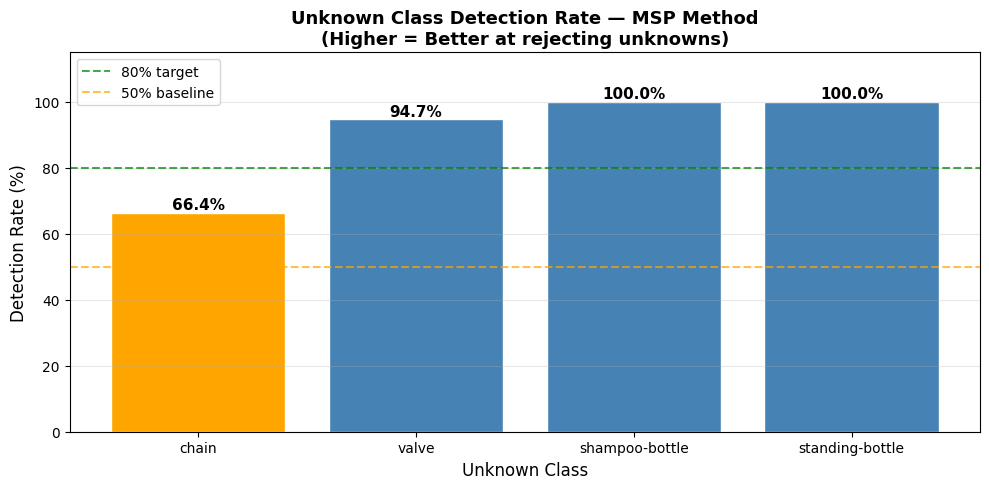

In [33]:
# ── How well does MSP reject each unknown class? ──────────
print("Unknown Class Detection Analysis (MSP):")
print("=" * 55)
print(f"{'Class':<20} {'Total':>6} "
      f"{'Rejected':>9} {'Detection%':>11}")
print("-" * 55)

unknown_detection = {}

for cls in UNKNOWN_CLASSES:
    cls_idx = [i for i, (path, label)
               in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]

    if not cls_idx:
        continue

    cls_scores     = msp_scores[cls_idx]
    cls_rejected   = int((cls_scores < BEST_THRESHOLD_MSP).sum())
    cls_total      = len(cls_scores)
    detection_rate = 100.0 * cls_rejected / cls_total

    unknown_detection[cls] = detection_rate
    bar = '█' * int(detection_rate / 5)
    print(f"  {cls:<20} {cls_total:>6} "
          f"{cls_rejected:>9} {detection_rate:>10.1f}%  {bar}")

# ── Plot per class detection ───────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
colors  = ['tomato' if v < 50 else
           'orange' if v < 80 else
           'steelblue'
           for v in unknown_detection.values()]

bars = ax.bar(unknown_detection.keys(),
               unknown_detection.values(),
               color=colors, edgecolor='white')

for bar, val in zip(bars, unknown_detection.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            f'{val:.1f}%',
            ha='center', fontsize=11,
            fontweight='bold')

ax.axhline(y=80, color='green',
           linestyle='--', alpha=0.7,
           label='80% target')
ax.axhline(y=50, color='orange',
           linestyle='--', alpha=0.7,
           label='50% baseline')
ax.set_ylim(0, 115)
ax.set_xlabel('Unknown Class', fontsize=12)
ax.set_ylabel('Detection Rate (%)', fontsize=12)
ax.set_title(
    'Unknown Class Detection Rate — MSP Method\n'
    '(Higher = Better at rejecting unknowns)',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_unknown_detection.png',
            dpi=150, bbox_inches='tight')
plt.show()


**Score Distribution per Unknown Class**

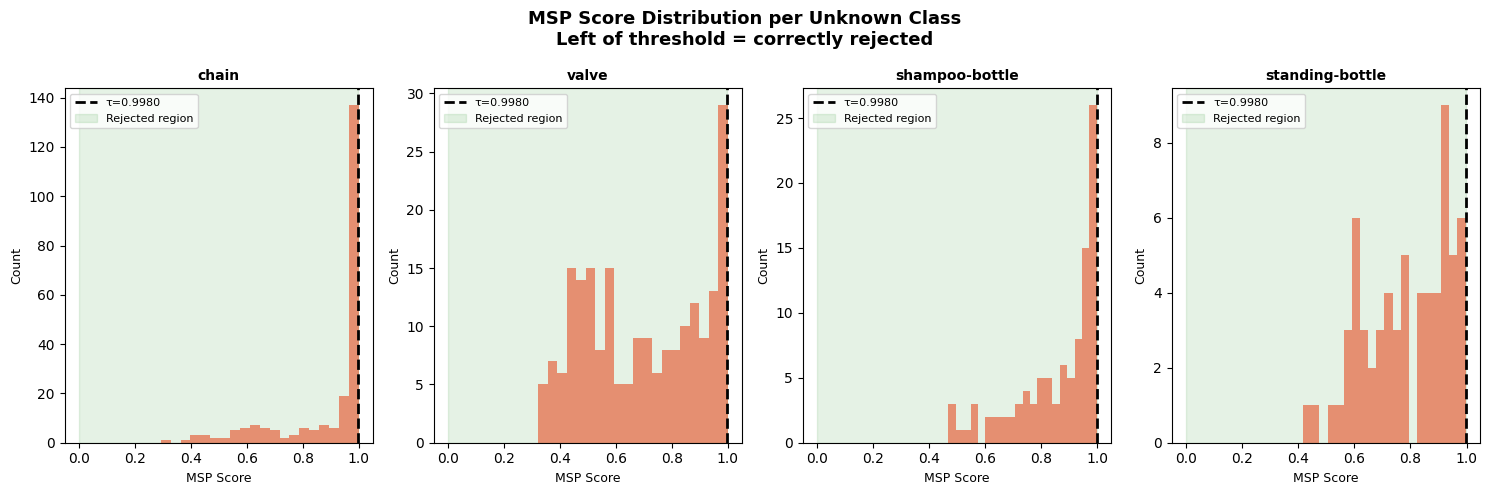

✅ Saved msp_per_unknown_scores.png


In [34]:
# ── MSP scores broken down by each unknown class ──────────
fig, axes = plt.subplots(
    1, len(UNKNOWN_CLASSES),
    figsize=(15, 5)
)

for idx, cls in enumerate(UNKNOWN_CLASSES):
    cls_idx = [i for i, (path, label)
               in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]

    cls_scores = msp_scores[cls_idx]

    axes[idx].hist(cls_scores, bins=20,
                   color='tomato', alpha=0.7,
                   edgecolor='none')
    axes[idx].axvline(
        x=BEST_THRESHOLD_MSP,
        color='black', linestyle='--',
        linewidth=2,
        label=f'τ={BEST_THRESHOLD_MSP:.4f}'
    )
    axes[idx].set_title(cls, fontsize=10, fontweight='bold')
    axes[idx].set_xlabel('MSP Score', fontsize=9)
    axes[idx].set_ylabel('Count', fontsize=9)
    axes[idx].axvspan(0, BEST_THRESHOLD_MSP,
                      alpha=0.1, color='green',
                      label='Rejected region')
    axes[idx].legend(fontsize=8)

plt.suptitle(
    'MSP Score Distribution per Unknown Class\n'
    'Left of threshold = correctly rejected',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_per_unknown_scores.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved msp_per_unknown_scores.png")


**Summary of MSP Threaholding**

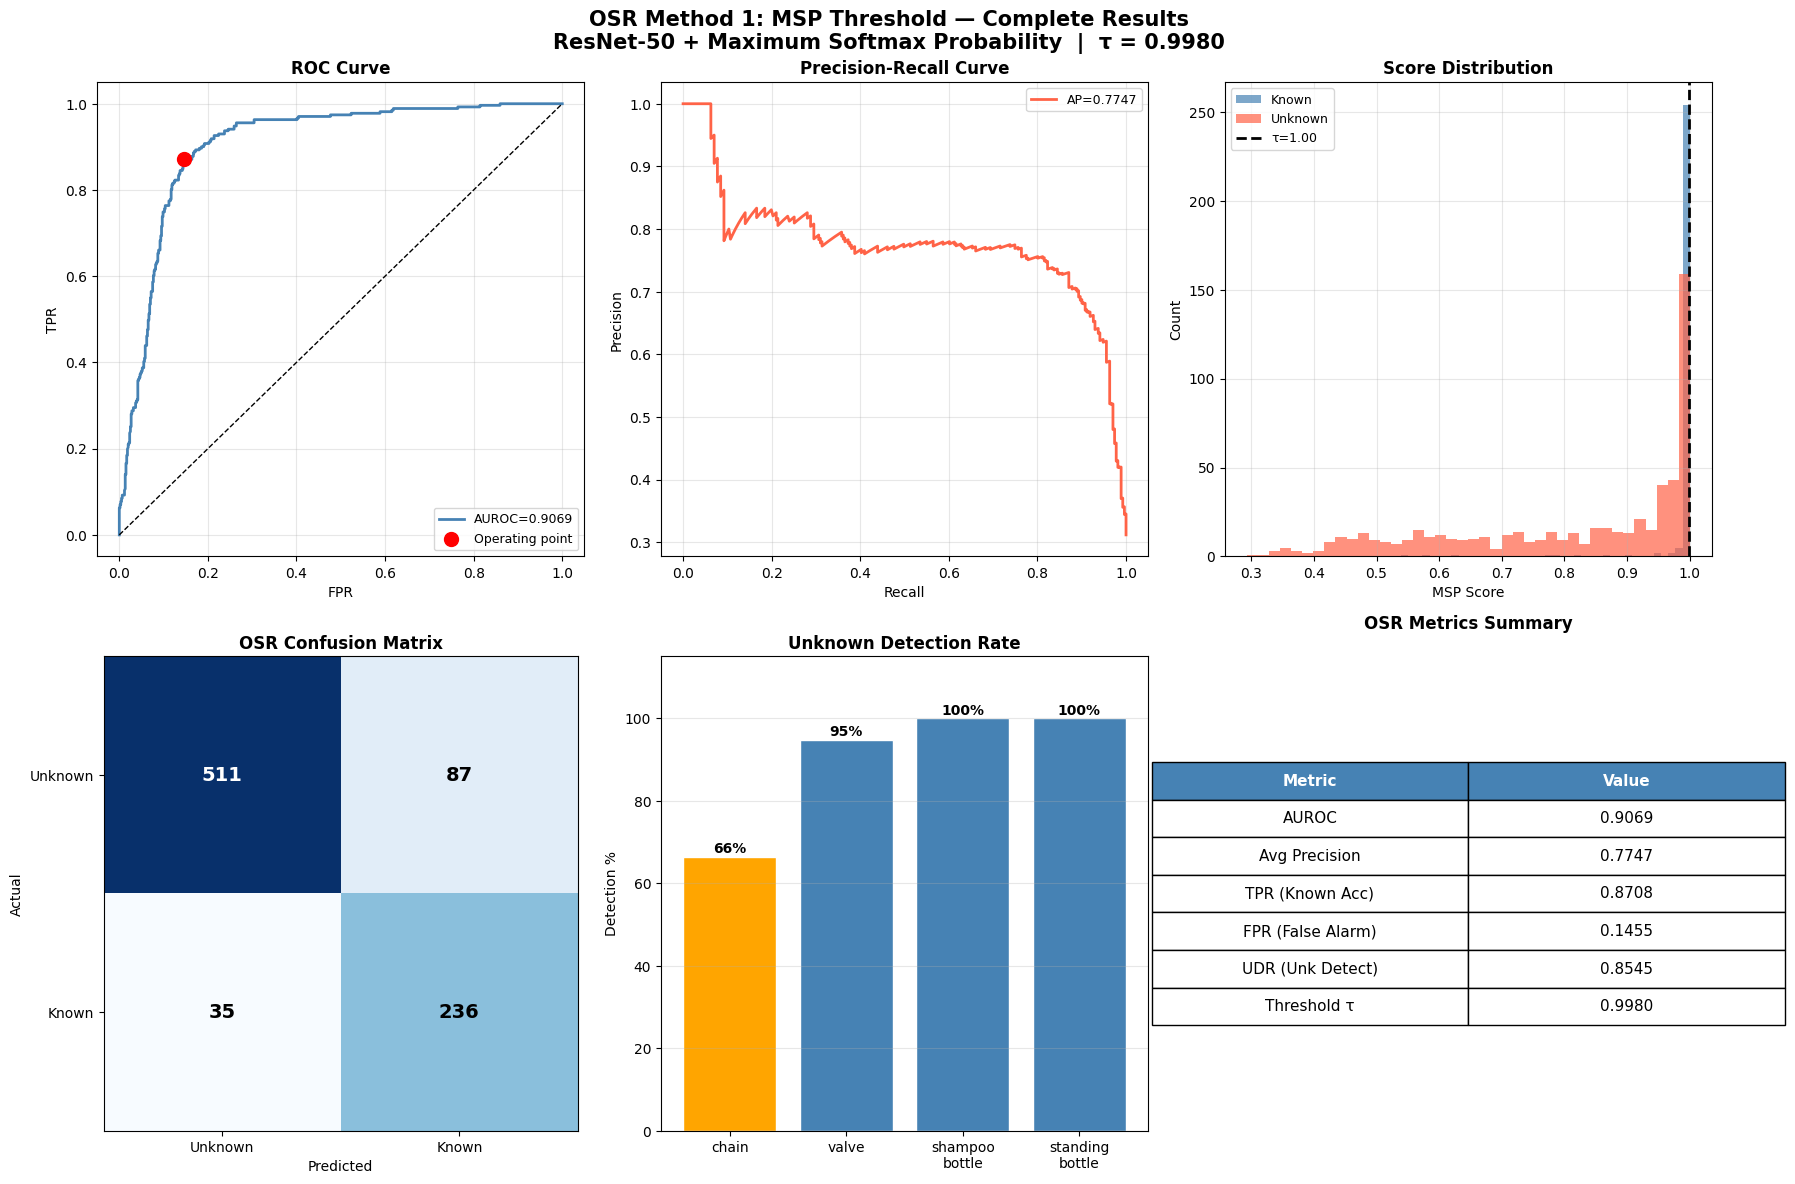

✅ Saved msp_complete_dashboard.png

🎯 This is your supervisor presentation figure!


In [35]:
# ── One figure showing everything ─────────────────────────
fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'OSR Method 1: MSP Threshold — Complete Results\n'
    f'ResNet-50 + Maximum Softmax Probability  |  '
    f'τ = {BEST_THRESHOLD_MSP:.4f}',
    fontsize=15, fontweight='bold', y=0.98
)

# ── 1. ROC Curve ──────────────────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
fpr_arr, tpr_arr, _ = roc_curve(binary_labels, msp_scores)
ax1.plot(fpr_arr, tpr_arr,
         color='steelblue', linewidth=2,
         label=f'AUROC={msp_results["auroc"]:.4f}')
ax1.plot([0,1],[0,1],'k--', linewidth=1)
ax1.scatter(msp_results['fpr'], msp_results['tpr'],
            color='red', s=100, zorder=5,
            label=f'Operating point')
ax1.set_title('ROC Curve', fontweight='bold')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

# ── 2. PR Curve ───────────────────────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
prec, rec, _ = precision_recall_curve(
    binary_labels, msp_scores
)
ap = average_precision_score(binary_labels, msp_scores)
ax2.plot(rec, prec, color='tomato',
         linewidth=2, label=f'AP={ap:.4f}')
ax2.set_title('Precision-Recall Curve', fontweight='bold')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

# ── 3. Score Distribution ─────────────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
ax3.hist(known_scores, bins=40, alpha=0.7,
         color='steelblue', label='Known',
         edgecolor='none')
ax3.hist(unknown_scores, bins=40, alpha=0.7,
         color='tomato', label='Unknown',
         edgecolor='none')
ax3.axvline(x=BEST_THRESHOLD_MSP,
            color='black', linestyle='--',
            linewidth=2, label=f'τ={BEST_THRESHOLD_MSP:.2f}')
ax3.set_title('Score Distribution', fontweight='bold')
ax3.set_xlabel('MSP Score')
ax3.set_ylabel('Count')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

# ── 4. OSR Confusion Matrix ───────────────────────────────
ax4 = fig.add_subplot(2, 3, 4)
im  = ax4.imshow(osr_cm, cmap='Blues')
ax4.set_xticks([0,1])
ax4.set_yticks([0,1])
ax4.set_xticklabels(['Unknown','Known'])
ax4.set_yticklabels(['Unknown','Known'])
thresh_cm = osr_cm.max() / 2
for i in range(2):
    for j in range(2):
        color = 'white' if osr_cm[i,j] > thresh_cm else 'black'
        ax4.text(j, i, str(osr_cm[i,j]),
                 ha='center', va='center',
                 fontsize=14, fontweight='bold',
                 color=color)
ax4.set_title('OSR Confusion Matrix', fontweight='bold')
ax4.set_xlabel('Predicted')
ax4.set_ylabel('Actual')

# ── 5. Per Unknown Detection ──────────────────────────────
ax5 = fig.add_subplot(2, 3, 5)
colors_bar = ['tomato' if v < 50 else
              'orange' if v < 80 else
              'steelblue'
              for v in unknown_detection.values()]
bars = ax5.bar(
    [c.replace('-','\n') for c in unknown_detection.keys()],
    unknown_detection.values(),
    color=colors_bar, edgecolor='white'
)
for bar, val in zip(bars, unknown_detection.values()):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f'{val:.0f}%',
             ha='center', fontsize=10,
             fontweight='bold')
ax5.set_ylim(0, 115)
ax5.set_title('Unknown Detection Rate', fontweight='bold')
ax5.set_ylabel('Detection %')
ax5.grid(axis='y', alpha=0.3)

# ── 6. Metrics Summary ────────────────────────────────────
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')

metrics = [
    ['Metric',           'Value'],
    ['AUROC',            f'{msp_results["auroc"]:.4f}'],
    ['Avg Precision',    f'{msp_results["ap"]:.4f}'],
    ['TPR (Known Acc)',  f'{msp_results["tpr"]:.4f}'],
    ['FPR (False Alarm)',f'{msp_results["fpr"]:.4f}'],
    ['UDR (Unk Detect)', f'{msp_results["udr"]:.4f}'],
    ['Threshold τ',      f'{BEST_THRESHOLD_MSP:.4f}'],
]

table = ax6.table(
    cellText  = metrics[1:],
    colLabels = metrics[0],
    loc       = 'center',
    cellLoc   = 'center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.3, 2.0)

# Color header
for j in range(2):
    table[0,j].set_facecolor('steelblue')
    table[0,j].set_text_props(color='white',
                               fontweight='bold')

ax6.set_title('OSR Metrics Summary',
               fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/msp_complete_dashboard.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved msp_complete_dashboard.png")
print("\n🎯 This is your supervisor presentation figure!")

In [36]:
# Save LIVE MSP results for final comparison table
import json

all_results = {
    'MSP': {
        'method'   : msp_results['method'],
        'auroc'    : round(float(msp_results['auroc']), 4),
        'ap'       : round(float(msp_results['ap']), 4),
        'tpr'      : round(float(msp_results['tpr']), 4),
        'fpr'      : round(float(msp_results['fpr']), 4),
        'udr'      : round(float(msp_results['udr']), 4),
        'threshold': float(msp_results['threshold']),
        'tp'       : int(msp_results['tp']),
        'tn'       : int(msp_results['tn']),
        'fp'       : int(msp_results['fp']),
        'fn'       : int(msp_results['fn']),
        'per_class_detection': {k: round(float(v), 2) for k, v in unknown_detection.items()},
    }
}

with open(f'{RESULTS_DIR}/all_results.json', 'w') as f:
    json.dump(all_results, f, indent=4)

print("✅ Live MSP results saved to all_results.json!")
print("  ", all_results['MSP'])
print("\nMethod 1 Complete ✅")


✅ Live MSP results saved to all_results.json!
   {'method': 'MSP Threshold', 'auroc': 0.9069, 'ap': 0.7747, 'tpr': 0.8708, 'fpr': 0.1455, 'udr': 0.8545, 'threshold': 0.9980217218399048, 'tp': 236, 'tn': 511, 'fp': 87, 'fn': 35, 'per_class_detection': {'chain': 66.37, 'valve': 94.71, 'shampoo-bottle': 100.0, 'standing-bottle': 100.0}}

Method 1 Complete ✅


# **One Class SVDD**

**Extract Embeddings Using ResNet-50**

In [37]:
# ── Extract embeddings from ResNet-50 ────────────────────
# We remove the final FC layer to get 2048-D features

class FeatureExtractor(nn.Module):
    """
    Wraps ResNet-50 and returns embeddings
    from the GAP layer (2048-D vector)
    instead of final class scores.
    """
    def __init__(self, resnet_model):
        super().__init__()
        # Everything except final FC layer
        self.features = nn.Sequential(
            *list(resnet_model.children())[:-1]
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(start_dim=1)  # (batch, 2048)
        return x


# ── Create feature extractor from trained model ───────────
feature_extractor = FeatureExtractor(model).to(DEVICE)
feature_extractor.eval()

# ── Test it works ─────────────────────────────────────────
with torch.no_grad():
    test_batch, _, _ = next(iter(train_loader))
    test_batch       = test_batch.to(DEVICE)
    test_embeddings  = feature_extractor(test_batch)

print("✅ Feature extractor ready!")
print(f"   Input shape  : {test_batch.shape}")
print(f"   Output shape : {test_embeddings.shape}")
print(f"   Embedding dim: {test_embeddings.shape[1]}")

✅ Feature extractor ready!
   Input shape  : torch.Size([32, 3, 224, 224])
   Output shape : torch.Size([32, 2048])
   Embedding dim: 2048


**Extract All Train & Test Embeddings**

In [38]:
def extract_embeddings(feature_extractor,
                        loader, device):
    """
    Extract embeddings for all images in loader.
    Returns embeddings, labels, paths.
    """
    feature_extractor.eval()
    all_embeddings = []
    all_labels     = []
    all_paths      = []

    with torch.no_grad():
        for images, labels, paths in loader:
            images     = images.to(device)
            embeddings = feature_extractor(images)

            all_embeddings.append(
                embeddings.cpu().numpy()
            )
            all_labels.extend(labels.numpy())
            all_paths.extend(paths)

    return (np.vstack(all_embeddings),
            np.array(all_labels),
            all_paths)


# ── Extract for train and test ────────────────────────────
print("Extracting train embeddings...")
train_embeddings, train_labels, train_paths = \
    extract_embeddings(feature_extractor,
                       train_loader, DEVICE)

print("Extracting test embeddings...")
test_embeddings, test_labels, test_paths = \
    extract_embeddings(feature_extractor,
                       test_loader, DEVICE)

print("\n✅ Embeddings extracted!")
print(f"   Train: {train_embeddings.shape}")
print(f"   Test : {test_embeddings.shape}")
print(f"   Train known only: "
      f"{(train_labels != -1).sum()} images")
print(f"   Test known      : "
      f"{(test_labels != -1).sum()} images")
print(f"   Test unknown    : "
      f"{(test_labels == -1).sum()} images")

Extracting train embeddings...
Extracting test embeddings...

✅ Embeddings extracted!
   Train: (1233, 2048)
   Test : (869, 2048)
   Train known only: 1233 images
   Test known      : 271 images
   Test unknown    : 598 images


**Train Deep SVDD**

In [39]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import normalize
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import average_precision_score

# ── Get only known class embeddings for training ──────────
known_mask       = train_labels != -1
train_known_emb  = train_embeddings[known_mask]
train_known_lbls = train_labels[known_mask]

print(f"Training SVDD on {len(train_known_emb)} "
      f"known class embeddings...")

# ── Normalize embeddings ──────────────────────────────────
# Important for SVDD — unit norm vectors work better
train_known_norm = normalize(train_known_emb,
                              norm='l2')

# ── Train One-Class SVM (SVDD approximation) ──────────────
# nu     : upper bound on fraction of outliers
# kernel : rbf works best for high-dim embeddings
# gamma  : kernel coefficient
ocsvm = OneClassSVM(
    kernel='rbf',
    nu=0.1,       # expect ~10% outliers
    gamma='scale'
)
ocsvm.fit(train_known_norm)

print("✅ One-Class SVM trained!")
print(f"   Kernel    : RBF")
print(f"   Nu        : 0.1")
print(f"   Trained on: {len(train_known_norm)} embeddings")

Training SVDD on 1233 known class embeddings...
✅ One-Class SVM trained!
   Kernel    : RBF
   Nu        : 0.1
   Trained on: 1233 embeddings


**Implement Deep SVDD with Centroid**

In [40]:
# ── Deep SVDD: centroid-based approach ────────────────────
# More aligned with your proposal's equation (2)

# Compute centroid of all known training embeddings
centroid = torch.tensor(
    train_known_emb.mean(axis=0),
    dtype=torch.float32
)

# Per-class centroids
class_centroids = {}
for cls_idx in range(NUM_CLASSES):
    cls_mask = train_known_lbls == cls_idx
    if cls_mask.sum() > 0:
        cls_centroid = train_known_emb[cls_mask].mean(axis=0)
        class_centroids[cls_idx] = torch.tensor(
            cls_centroid, dtype=torch.float32
        )

print("✅ Centroids computed!")
print(f"   Global centroid shape : {centroid.shape}")
print(f"   Per-class centroids   : {len(class_centroids)}")
for idx, cls in IDX_TO_CLASS.items():
    c = class_centroids[idx]
    print(f"   {cls:<20} centroid norm: "
          f"{c.norm().item():.4f}")

✅ Centroids computed!
   Global centroid shape : torch.Size([2048])
   Per-class centroids   : 6
   bottle               centroid norm: 30.2434
   can                  centroid norm: 31.9825
   tire                 centroid norm: 32.6486
   drink-carton         centroid norm: 29.7000
   hook                 centroid norm: 35.5503
   propeller            centroid norm: 34.4480


**Score All Test Images**

In [41]:
# ── Normalize test embeddings ─────────────────────────────
test_norm = normalize(test_embeddings, norm='l2')

# ── Method A: One-Class SVM scores ───────────────────────
# decision_function: higher = more like known
ocsvm_scores = ocsvm.decision_function(test_norm)

# ── Method B: Distance to global centroid ────────────────
test_tensor  = torch.tensor(test_embeddings,
                              dtype=torch.float32)
centroid_distances = torch.norm(
    test_tensor - centroid.unsqueeze(0),
    dim=1
).numpy()

# Convert distance to score
# (negate so higher = more like known)
distance_scores = -centroid_distances

# ── Method C: Distance to nearest class centroid ──────────
# From your proposal equation (2)
all_centroids = torch.stack(
    [class_centroids[i] for i in range(NUM_CLASSES)]
)

min_distances = []
predicted_classes = []

for emb in test_tensor:
    dists     = torch.norm(
        emb.unsqueeze(0) - all_centroids,
        dim=1
    )
    min_dist, pred_cls = dists.min(dim=0)
    min_distances.append(min_dist.item())
    predicted_classes.append(pred_cls.item())

min_distances     = np.array(min_distances)
predicted_classes = np.array(predicted_classes)

# Negate for scoring (lower distance = more known)
nearest_centroid_scores = -min_distances

print("✅ Scores computed!")
print(f"\nScore Statistics:")
print(f"{'Method':<25} {'Known Mean':>12} "
      f"{'Unknown Mean':>13}")
print("-" * 55)

known_m   = test_labels != -1
unknown_m = test_labels == -1

for name, scores in [
    ('OC-SVM',           ocsvm_scores),
    ('Global Centroid',  distance_scores),
    ('Nearest Centroid', nearest_centroid_scores)
]:
    k_mean = scores[known_m].mean()
    u_mean = scores[unknown_m].mean()
    sep    = '✅' if k_mean > u_mean else '❌'
    print(f"  {name:<23} {k_mean:>12.4f} "
          f"{u_mean:>13.4f} {sep}")

✅ Scores computed!

Score Statistics:
Method                      Known Mean  Unknown Mean
-------------------------------------------------------
  OC-SVM                        0.5141       -0.6668 ✅
  Global Centroid             -23.9393      -19.8898 ❌
  Nearest Centroid             -9.8077      -18.6471 ✅


**Evaluate All Three SVDD Variants**

In [42]:
def evaluate_svdd(scores, true_labels, method_name):
    """Evaluate OSR performance for SVDD / distance-based variant."""
    binary_labels = (true_labels != -1).astype(int)

    fpr_arr, tpr_arr, thresholds = roc_curve(binary_labels, scores)
    auroc = float(auc(fpr_arr, tpr_arr))
    ap    = float(average_precision_score(binary_labels, scores))

    j_scores    = tpr_arr - fpr_arr
    best_idx    = int(np.argmax(j_scores))
    best_thresh = float(thresholds[best_idx])

    pred_known = (scores >= best_thresh).astype(int)
    TP = int(((pred_known == 1) & (binary_labels == 1)).sum())
    TN = int(((pred_known == 0) & (binary_labels == 0)).sum())
    FP = int(((pred_known == 1) & (binary_labels == 0)).sum())
    FN = int(((pred_known == 0) & (binary_labels == 1)).sum())

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0.0
    UDR = TN / (TN + FP) if (TN + FP) > 0 else 0.0

    print(f"\n{method_name}:")
    print(f"  Thresh: {best_thresh:.4f}")
    print(f"  AUROC : {auroc:.4f}")
    print(f"  AP    : {ap:.4f}")
    print(f"  TPR   : {TPR:.4f}")
    print(f"  FPR   : {FPR:.4f}")
    print(f"  UDR   : {UDR:.4f}")
    print(f"  CM    : TP={TP} TN={TN} FP={FP} FN={FN}")

    return {
        'method'    : method_name,
        'auroc'     : auroc,
        'ap'        : ap,
        'tpr'       : float(TPR),
        'fpr'       : float(FPR),
        'udr'       : float(UDR),
        'threshold' : best_thresh,
        'tp'        : TP,
        'tn'        : TN,
        'fp'        : FP,
        'fn'        : FN,
        'fpr_arr'   : fpr_arr,
        'tpr_arr'   : tpr_arr,
        'scores'    : scores,
    }


print("SVDD Variant Evaluation:")
print("=" * 50)

svdd_ocsvm   = evaluate_svdd(ocsvm_scores, test_labels, 'OC-SVM')
svdd_global  = evaluate_svdd(distance_scores, test_labels, 'Global Centroid')
svdd_nearest = evaluate_svdd(nearest_centroid_scores, test_labels, 'Nearest Centroid')

best_svdd = max([svdd_ocsvm, svdd_global, svdd_nearest], key=lambda x: x['auroc'])
print(f"\n✅ Best SVDD variant: {best_svdd['method']}")
print(f"   AUROC: {best_svdd['auroc']:.4f}")


SVDD Variant Evaluation:

OC-SVM:
  Thresh: -0.6260
  AUROC : 0.6982
  AP    : 0.3943
  TPR   : 0.9926
  FPR   : 0.5100
  UDR   : 0.4900
  CM    : TP=269 TN=293 FP=305 FN=2

Global Centroid:
  Thresh: -37.3574
  AUROC : 0.2371
  AP    : 0.2064
  TPR   : 0.9815
  FPR   : 0.9298
  UDR   : 0.0702
  CM    : TP=266 TN=42 FP=556 FN=5

Nearest Centroid:
  Thresh: -13.8392
  AUROC : 0.9175
  AP    : 0.8568
  TPR   : 0.8856
  FPR   : 0.1405
  UDR   : 0.8595
  CM    : TP=240 TN=514 FP=84 FN=31

✅ Best SVDD variant: Nearest Centroid
   AUROC: 0.9175


**SVDD Complete Dashboard**

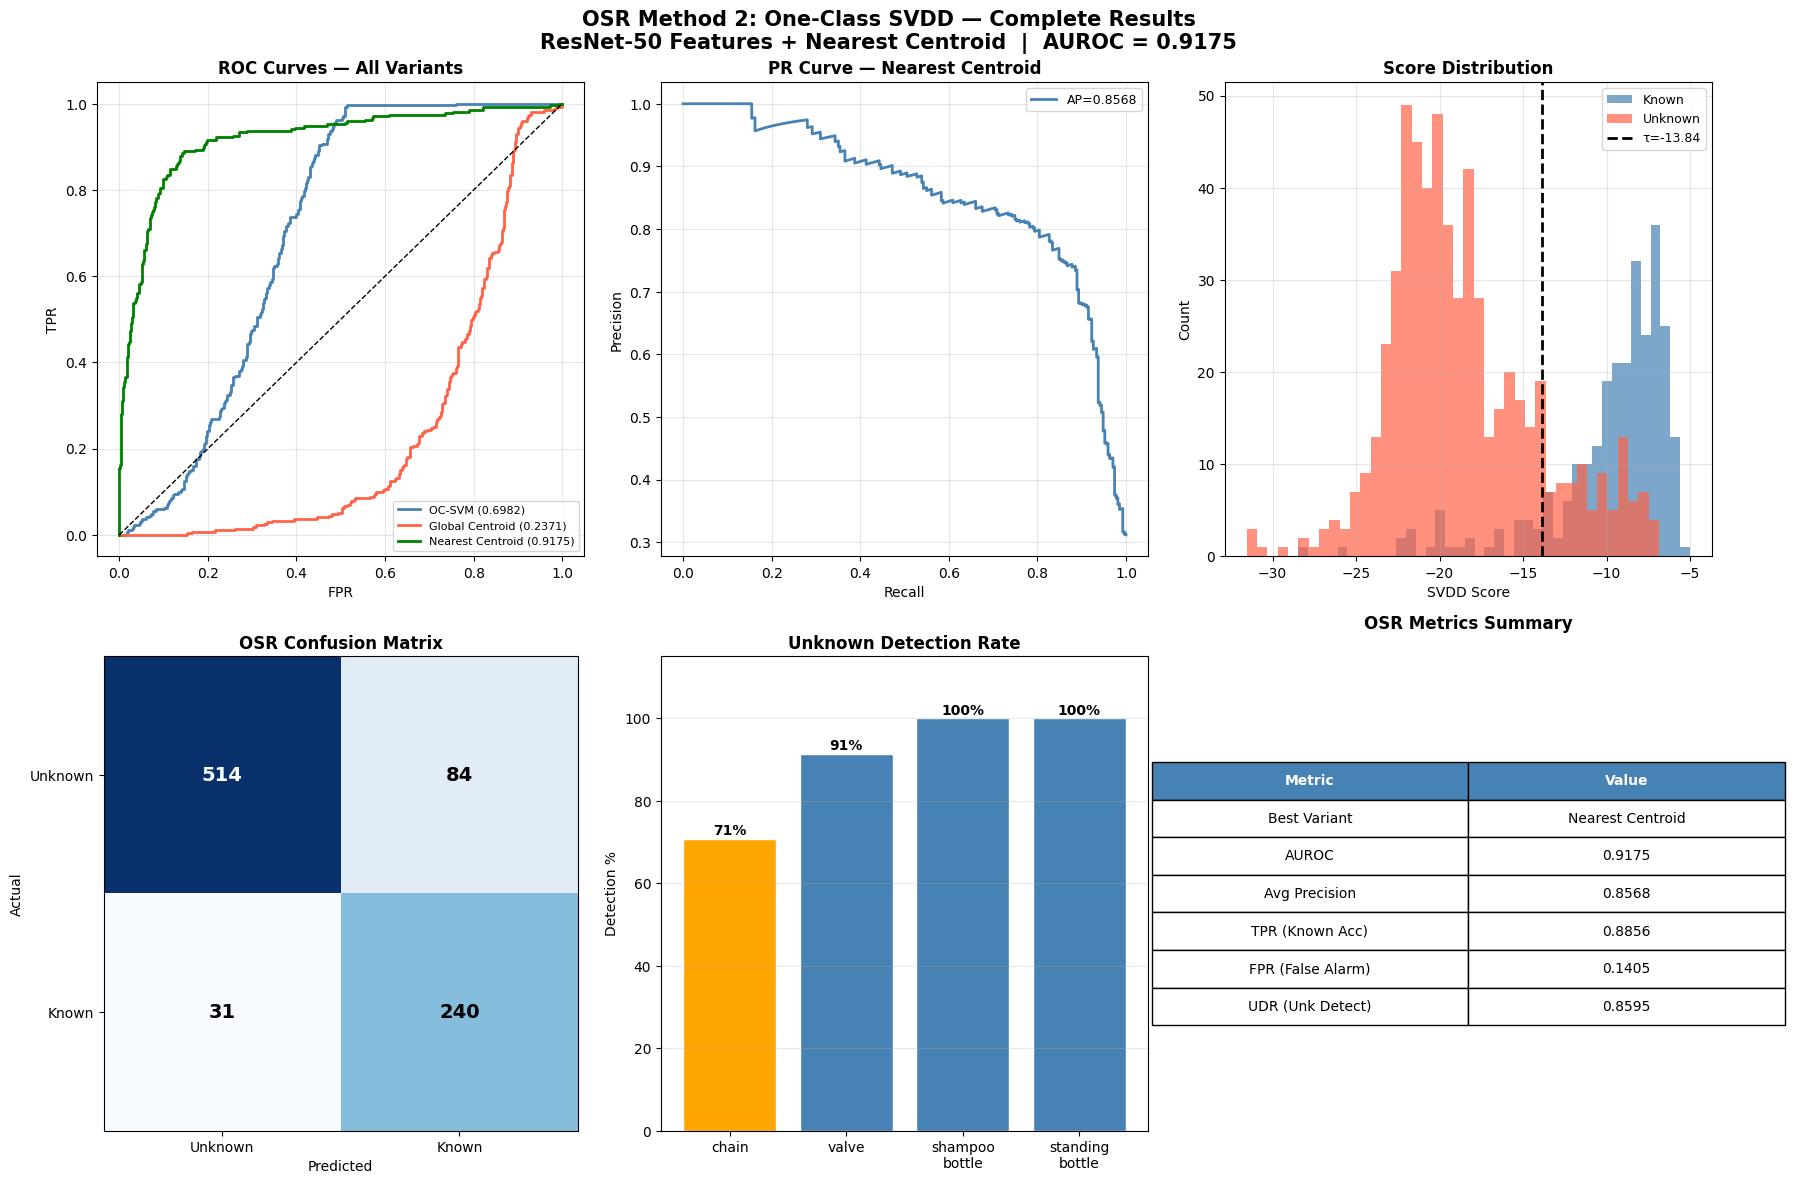

✅ Saved svdd_complete_dashboard.png


In [43]:
fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'OSR Method 2: One-Class SVDD — Complete Results\n'
    f'ResNet-50 Features + {best_svdd["method"]}  |  '
    f'AUROC = {best_svdd["auroc"]:.4f}',
    fontsize=15, fontweight='bold', y=0.98
)

binary_labels  = (test_labels != -1).astype(int)
best_scores    = best_svdd['scores']
known_scores_s = best_scores[test_labels != -1]
unk_scores_s   = best_scores[test_labels == -1]

# ── 1. ROC Curves all variants ────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
for res, color, name in [
    (svdd_ocsvm,   'steelblue', 'OC-SVM'),
    (svdd_global,  'tomato',    'Global Centroid'),
    (svdd_nearest, 'green',     'Nearest Centroid')
]:
    ax1.plot(res['fpr_arr'], res['tpr_arr'],
             color=color, linewidth=2,
             label=f'{name} ({res["auroc"]:.4f})')
ax1.plot([0,1],[0,1],'k--', linewidth=1)
ax1.set_title('ROC Curves — All Variants',
               fontweight='bold')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

# ── 2. PR Curve best variant ──────────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
prec, rec, _ = precision_recall_curve(
    binary_labels, best_scores
)
ax2.plot(rec, prec, color='steelblue',
         linewidth=2,
         label=f'AP={best_svdd["ap"]:.4f}')
ax2.set_title(f'PR Curve — {best_svdd["method"]}',
               fontweight='bold')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

# ── 3. Score Distribution ─────────────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
ax3.hist(known_scores_s, bins=40, alpha=0.7,
         color='steelblue', label='Known',
         edgecolor='none')
ax3.hist(unk_scores_s, bins=40, alpha=0.7,
         color='tomato', label='Unknown',
         edgecolor='none')
ax3.axvline(x=best_svdd['threshold'],
            color='black', linestyle='--',
            linewidth=2,
            label=f'τ={best_svdd["threshold"]:.2f}')
ax3.set_title('Score Distribution', fontweight='bold')
ax3.set_xlabel('SVDD Score')
ax3.set_ylabel('Count')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

# ── 4. OSR Confusion Matrix ───────────────────────────────
ax4 = fig.add_subplot(2, 3, 4)
pred_known = (best_scores >= best_svdd['threshold']
              ).astype(int)
svdd_cm    = confusion_matrix(binary_labels, pred_known)
im = ax4.imshow(svdd_cm, cmap='Blues')
ax4.set_xticks([0,1])
ax4.set_yticks([0,1])
ax4.set_xticklabels(['Unknown','Known'])
ax4.set_yticklabels(['Unknown','Known'])
thresh_cm = svdd_cm.max() / 2
for i in range(2):
    for j in range(2):
        color = ('white' if svdd_cm[i,j] > thresh_cm
                 else 'black')
        ax4.text(j, i, str(svdd_cm[i,j]),
                 ha='center', va='center',
                 fontsize=14, fontweight='bold',
                 color=color)
ax4.set_title('OSR Confusion Matrix', fontweight='bold')
ax4.set_xlabel('Predicted')
ax4.set_ylabel('Actual')

# ── 5. Per Unknown Detection ──────────────────────────────
ax5 = fig.add_subplot(2, 3, 5)
svdd_unknown_detection = {}
for cls in UNKNOWN_CLASSES:
    cls_idx = [i for i, (path, label)
               in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]
    if not cls_idx:
        continue
    cls_scores = best_scores[cls_idx]
    rejected   = (cls_scores < best_svdd['threshold']
                  ).sum()
    rate       = 100. * rejected / len(cls_scores)
    svdd_unknown_detection[cls] = rate

colors_bar = ['tomato' if v < 50 else
              'orange' if v < 80 else
              'steelblue'
              for v in svdd_unknown_detection.values()]

bars = ax5.bar(
    [c.replace('-','\n')
     for c in svdd_unknown_detection.keys()],
    svdd_unknown_detection.values(),
    color=colors_bar, edgecolor='white'
)
for bar, val in zip(bars,
                     svdd_unknown_detection.values()):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f'{val:.0f}%',
             ha='center', fontsize=10,
             fontweight='bold')
ax5.set_ylim(0, 115)
ax5.set_title('Unknown Detection Rate',
               fontweight='bold')
ax5.set_ylabel('Detection %')
ax5.grid(axis='y', alpha=0.3)

# ── 6. Metrics Summary ────────────────────────────────────
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
metrics = [
    ['Metric',            'Value'],
    ['Best Variant',      best_svdd['method']],
    ['AUROC',             f'{best_svdd["auroc"]:.4f}'],
    ['Avg Precision',     f'{best_svdd["ap"]:.4f}'],
    ['TPR (Known Acc)',   f'{best_svdd["tpr"]:.4f}'],
    ['FPR (False Alarm)', f'{best_svdd["fpr"]:.4f}'],
    ['UDR (Unk Detect)',  f'{best_svdd["udr"]:.4f}'],
]
table = ax6.table(
    cellText  = metrics[1:],
    colLabels = metrics[0],
    loc       = 'center',
    cellLoc   = 'center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.3, 2.0)
for j in range(2):
    table[0,j].set_facecolor('steelblue')
    table[0,j].set_text_props(
        color='white', fontweight='bold'
    )
ax6.set_title('OSR Metrics Summary',
               fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(
    f'{FIGURES_DIR}/svdd_complete_dashboard.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print("✅ Saved svdd_complete_dashboard.png")

In [44]:
# ── Update results dictionary (LIVE, no hardcoding) ───────
all_results['SVDD'] = {
    'method'   : best_svdd['method'],
    'auroc'    : round(float(best_svdd['auroc']), 4),
    'ap'       : round(float(best_svdd['ap']), 4),
    'tpr'      : round(float(best_svdd['tpr']), 4),
    'fpr'      : round(float(best_svdd['fpr']), 4),
    'udr'      : round(float(best_svdd['udr']), 4),
    'threshold': float(best_svdd['threshold']),
    'tp'       : int(best_svdd['tp']),
    'tn'       : int(best_svdd['tn']),
    'fp'       : int(best_svdd['fp']),
    'fn'       : int(best_svdd['fn']),
    'per_class_detection': {k: round(float(v), 2) for k, v in svdd_unknown_detection.items()},
    'variants': {
        v['method']: {
            'auroc': round(float(v['auroc']), 4),
            'ap'   : round(float(v['ap']), 4),
            'tpr'  : round(float(v['tpr']), 4),
            'fpr'  : round(float(v['fpr']), 4),
            'udr'  : round(float(v['udr']), 4),
        }
        for v in [svdd_ocsvm, svdd_global, svdd_nearest]
    }
}

with open(f'{RESULTS_DIR}/all_results.json', 'w') as f:
    json.dump(all_results, f, indent=4)

print("✅ Live SVDD results saved to all_results.json!")
print("  ", all_results['SVDD']['per_class_detection'])


✅ Live SVDD results saved to all_results.json!
   {'chain': 70.8, 'valve': 91.35, 'shampoo-bottle': 100.0, 'standing-bottle': 100.0}


# Deep Matric Learning


**Install & Import Metric Learning Library**

In [45]:
!pip install pytorch-metric-learning -q

from pytorch_metric_learning import losses, miners
from pytorch_metric_learning.distances import CosineSimilarity
import torch.nn.functional as F

print("✅ Metric learning library ready!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.5.5 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
torchvision 0.26.0+cu130 requires torch==2.11.0, but you have torch 2.15.0 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.5 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
✅ Metric learning library ready!


**Build Embedding Network**

In [46]:
class EmbeddingNet(nn.Module):
    """
    ResNet-50 backbone + embedding projection head.
    Produces L2-normalized 128-D embeddings
    optimized for metric learning.
    """
    def __init__(self, embedding_dim=128):
        super().__init__()

        # Load pretrained ResNet-50
        resnet = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V1
        )

        # Feature extractor (remove final FC)
        self.backbone = nn.Sequential(
            *list(resnet.children())[:-1]
        )

        # Freeze early layers
        for name, param in self.backbone.named_parameters():
            if 'layer1' in name or 'layer2' in name:
                param.requires_grad = False

        # Projection head: 2048 → 512 → 128
        self.projector = nn.Sequential(
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, embedding_dim)
        )

        self.embedding_dim = embedding_dim

    def forward(self, x):
        # Extract features
        features = self.backbone(x)
        features = features.flatten(start_dim=1)  # (B, 2048)

        # Project to embedding space
        embeddings = self.projector(features)     # (B, 128)

        # L2 normalize — unit sphere
        embeddings = F.normalize(embeddings, p=2, dim=1)

        return embeddings


# ── Build model ───────────────────────────────────────────
EMBEDDING_DIM  = 128
embedding_model = EmbeddingNet(
    embedding_dim=EMBEDDING_DIM
).to(DEVICE)

# ── Count params ──────────────────────────────────────────
total     = sum(p.numel() for p in embedding_model.parameters())
trainable = sum(p.numel() for p in embedding_model.parameters()
                if p.requires_grad)

print("✅ EmbeddingNet built!")
print(f"   Embedding dim   : {EMBEDDING_DIM}")
print(f"   Total params    : {total:,}")
print(f"   Trainable params: {trainable:,}")
print(f"\n   Input  : (batch, 3, 224, 224)")
print(f"   Output : (batch, {EMBEDDING_DIM})  ← L2 normalized")

✅ EmbeddingNet built!
   Embedding dim   : 128
   Total params    : 24,623,808
   Trainable params: 24,623,808

   Input  : (batch, 3, 224, 224)
   Output : (batch, 128)  ← L2 normalized


**Define Triplet Loss + Miner**

In [47]:
# ── Triplet Loss with online hard mining ──────────────────
# Miner finds hardest triplets in each batch automatically

triplet_loss = losses.TripletMarginLoss(
    margin=0.2,               # minimum distance between
                               # positive and negative pairs
    distance=CosineSimilarity(),
    reducer=None
)

# Hard triplet miner — finds most informative triplets
miner = miners.TripletMarginMiner(
    margin=0.2,
    distance=CosineSimilarity(),
    type_of_triplets='hard'   # hardest negatives only
)

# ── Optimizer ─────────────────────────────────────────────
metric_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad,
           embedding_model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

metric_scheduler = StepLR(
    metric_optimizer,
    step_size=7,
    gamma=0.5
)

print("✅ Metric learning configured!")
print(f"   Loss    : Triplet Margin Loss")
print(f"   Margin  : 0.2")
print(f"   Miner   : Hard Triplet Miner")
print(f"   Distance: Cosine Similarity")
print(f"   Optimizer: Adam (lr=1e-4)")

✅ Metric learning configured!
   Loss    : Triplet Margin Loss
   Margin  : 0.2
   Miner   : Hard Triplet Miner
   Distance: Cosine Similarity
   Optimizer: Adam (lr=1e-4)


**Custom Metric Training Loop**

In [48]:
def train_metric_epoch(model, loader,
                        loss_fn, miner,
                        optimizer, device):
    """
    Train one epoch with triplet loss.
    Different from classification — no accuracy metric.
    We track loss and number of mined triplets.
    """
    model.train()
    running_loss   = 0.0
    total_triplets = 0
    total_batches  = 0

    for images, labels, _ in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Get embeddings
        embeddings = model(images)

        # Mine hard triplets
        hard_pairs = miner(embeddings, labels)
        num_triplets = len(hard_pairs[0])

        # Compute triplet loss
        loss = loss_fn(embeddings, labels, hard_pairs)

        loss.backward()
        optimizer.step()

        running_loss   += loss.item()
        total_triplets += num_triplets
        total_batches  += 1

    avg_loss     = running_loss / total_batches
    avg_triplets = total_triplets / total_batches

    return avg_loss, avg_triplets


def validate_metric(model, loader,
                     loss_fn, miner, device):
    """Validate metric learning model."""
    model.eval()
    running_loss   = 0.0
    total_batches  = 0

    with torch.no_grad():
        for images, labels, _ in loader:
            images = images.to(device)
            labels = labels.to(device)

            embeddings   = model(images)
            hard_pairs   = miner(embeddings, labels)
            loss         = loss_fn(embeddings,
                                    labels,
                                    hard_pairs)

            running_loss  += loss.item()
            total_batches += 1

    return running_loss / total_batches


print("✅ Metric training functions defined!")

✅ Metric training functions defined!


**Train Embedding Model**

In [49]:
NUM_METRIC_EPOCHS = 30
best_metric_loss  = float('inf')
best_metric_wts   = copy.deepcopy(
    embedding_model.state_dict()
)

metric_history = {
    'train_loss': [],
    'val_loss'  : [],
    'triplets'  : []
}

early_stop_metric = EarlyStopping(
    patience=5,
    min_delta=0.001,
    mode='min'         # watching LOSS not accuracy
)

print("Training Embedding Network with Triplet Loss...")
print("=" * 65)
print(f"{'Epoch':>6} {'T-Loss':>10} {'V-Loss':>10} "
      f"{'Triplets':>10} {'Time':>6}")
print("-" * 65)

for epoch in range(1, NUM_METRIC_EPOCHS + 1):
    start = time.time()

    t_loss, triplets = train_metric_epoch(
        embedding_model, train_loader,
        triplet_loss, miner,
        metric_optimizer, DEVICE
    )
    v_loss = validate_metric(
        embedding_model, val_loader,
        triplet_loss, miner, DEVICE
    )

    metric_scheduler.step()

    metric_history['train_loss'].append(t_loss)
    metric_history['val_loss'].append(v_loss)
    metric_history['triplets'].append(triplets)

    saved = ""
    if v_loss < best_metric_loss:
        best_metric_loss = v_loss
        best_metric_wts  = copy.deepcopy(
            embedding_model.state_dict()
        )
        torch.save(
            best_metric_wts,
            f'{MODEL_DIR}/embedding_model_best.pth'
        )
        saved = "✅"

    elapsed = time.time() - start
    print(f"{epoch:>6} {t_loss:>10.4f} {v_loss:>10.4f} "
          f"{triplets:>10.0f} {elapsed:>5.1f}s {saved}")

    if early_stop_metric(v_loss):
        print(f"\n🛑 Early stopping at epoch {epoch}!")
        break

embedding_model.load_state_dict(best_metric_wts)
print("=" * 65)
print(f"\n✅ Training complete!")
print(f"   Best Val Loss: {best_metric_loss:.4f}")

Training Embedding Network with Triplet Loss...
 Epoch     T-Loss     V-Loss   Triplets   Time
-----------------------------------------------------------------
     1     0.2941     0.1567        717  15.4s ✅
     2     0.2934     0.0894        226  15.6s ✅
     3     0.2828     0.0536        128  14.9s ✅
     4     0.2460     0.0609         81  14.2s 
     ⏳ EarlyStopping: 1/5
     5     0.2657     0.0541         99  14.1s 
     ⏳ EarlyStopping: 2/5
     6     0.2192     0.0298         51  14.3s ✅
     7     0.1780     0.0320         22  14.3s 
     ⏳ EarlyStopping: 1/5
     8     0.1447     0.0000         39  14.4s ✅
     9     0.1674     0.0231         24  14.3s 
     ⏳ EarlyStopping: 1/5
    10     0.1466     0.0292         18  14.1s 
     ⏳ EarlyStopping: 2/5
    11     0.1025     0.0000          9  13.9s 
     ⏳ EarlyStopping: 3/5
    12     0.1143     0.0240         16  13.9s 
     ⏳ EarlyStopping: 4/5
    13     0.0695     0.0000          6  13.7s 
     ⏳ EarlyStopping: 5/5

🛑

**Extract Metric Embeddings**

In [50]:
# ── Extract embeddings from trained metric model ──────────
print("Extracting metric embeddings...")

metric_train_emb, metric_train_labels, _ = \
    extract_embeddings(embedding_model,
                       train_loader, DEVICE)

metric_test_emb, metric_test_labels, _ = \
    extract_embeddings(embedding_model,
                       test_loader, DEVICE)

# ── Compute per-class centroids in metric space ───────────
metric_centroids = {}
known_mask       = metric_train_labels != -1

for cls_idx in range(NUM_CLASSES):
    cls_mask = metric_train_labels == cls_idx
    if cls_mask.sum() > 0:
        metric_centroids[cls_idx] = \
            metric_train_emb[cls_mask].mean(axis=0)

print(f"✅ Metric embeddings extracted!")
print(f"   Train shape : {metric_train_emb.shape}")
print(f"   Test shape  : {metric_test_emb.shape}")
print(f"   Centroids   : {len(metric_centroids)} classes")
print(f"   Embedding dim: {metric_test_emb.shape[1]}")

Extracting metric embeddings...
✅ Metric embeddings extracted!
   Train shape : (1233, 128)
   Test shape  : (869, 128)
   Centroids   : 6 classes
   Embedding dim: 128


**Compute OSR Scores & Evaluate**

In [51]:
# ── Distance to nearest centroid in metric space ──────────
all_centroids_metric = np.stack(
    [metric_centroids[i] for i in range(NUM_CLASSES)]
)

metric_distances = []
metric_pred_cls  = []

for emb in metric_test_emb:
    dists   = np.linalg.norm(emb - all_centroids_metric, axis=1)
    min_idx = int(np.argmin(dists))
    metric_distances.append(dists[min_idx])
    metric_pred_cls.append(min_idx)

metric_distances = np.array(metric_distances)
metric_pred_cls  = np.array(metric_pred_cls)

# Negate — higher score = more likely known
metric_scores = -metric_distances

# ── Evaluate OSR ──────────────────────────────────────────
metric_results = evaluate_svdd(
    metric_scores,
    metric_test_labels,
    'Deep Metric Learning'
)

# ── Known-class closed-set accuracy in DML space ──────────
known_mask_test = metric_test_labels != -1
dml_closed_acc  = float((metric_pred_cls[known_mask_test] == metric_test_labels[known_mask_test]).mean())
print(f"\nDML Nearest-Centroid Known Closed-Set Acc: {dml_closed_acc*100:.2f}%")

# ── Per-unknown-class breakdown for DML ───────────────────
dml_unknown_detection = {}
print("\nUnknown Class Detection Analysis (DML):")
print("=" * 55)
print(f"{'Class':<20} {'Total':>6} {'Rejected':>9} {'Detection%':>11}")
print("-" * 55)
for cls in UNKNOWN_CLASSES:
    cls_idx = [i for i, (path, label) in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]
    if not cls_idx:
        continue
    cls_sc       = metric_scores[cls_idx]
    cls_rejected = int((cls_sc < metric_results['threshold']).sum())
    det_rate     = 100.0 * cls_rejected / len(cls_sc)
    dml_unknown_detection[cls] = det_rate
    print(f"  {cls:<20} {len(cls_sc):>6} {cls_rejected:>9} {det_rate:>10.1f}%")

# ── Live Cross-Method Comparison ──────────────────────────
print(f"\n{'='*65}")
print("LIVE COMPARISON ACROSS ALL 3 METHODS:")
print(f"{'='*65}")
print(f"{'Method':<25} {'AUROC':>8} {'AP':>8} {'TPR':>8} {'FPR':>8} {'UDR':>8}")
print(f"{'-'*65}")
for name, res in [('MSP Threshold', msp_results),
                  (f"SVDD ({best_svdd['method']})", best_svdd),
                  ('Metric Learning', metric_results)]:
    print(f"{name:<25} "
          f"{res['auroc']:>8.4f} "
          f"{res['ap']:>8.4f} "
          f"{res['tpr']:>8.4f} "
          f"{res['fpr']:>8.4f} "
          f"{res['udr']:>8.4f}")



Deep Metric Learning:
  Thresh: -0.2378
  AUROC : 0.9603
  AP    : 0.9235
  TPR   : 0.9077
  FPR   : 0.0987
  UDR   : 0.9013
  CM    : TP=246 TN=539 FP=59 FN=25

DML Nearest-Centroid Known Closed-Set Acc: 100.00%

Unknown Class Detection Analysis (DML):
Class                 Total  Rejected  Detection%
-------------------------------------------------------
  chain                   226       182       80.5%
  valve                   208       193       92.8%
  shampoo-bottle           99        99      100.0%
  standing-bottle          65        65      100.0%

LIVE COMPARISON ACROSS ALL 3 METHODS:
Method                       AUROC       AP      TPR      FPR      UDR
-----------------------------------------------------------------
MSP Threshold               0.9069   0.7747   0.8708   0.1455   0.8545
SVDD (Nearest Centroid)     0.9175   0.8568   0.8856   0.1405   0.8595
Metric Learning             0.9603   0.9235   0.9077   0.0987   0.9013


**t-SNE Visualization**

Computing t-SNE (this takes ~1-2 minutes)...


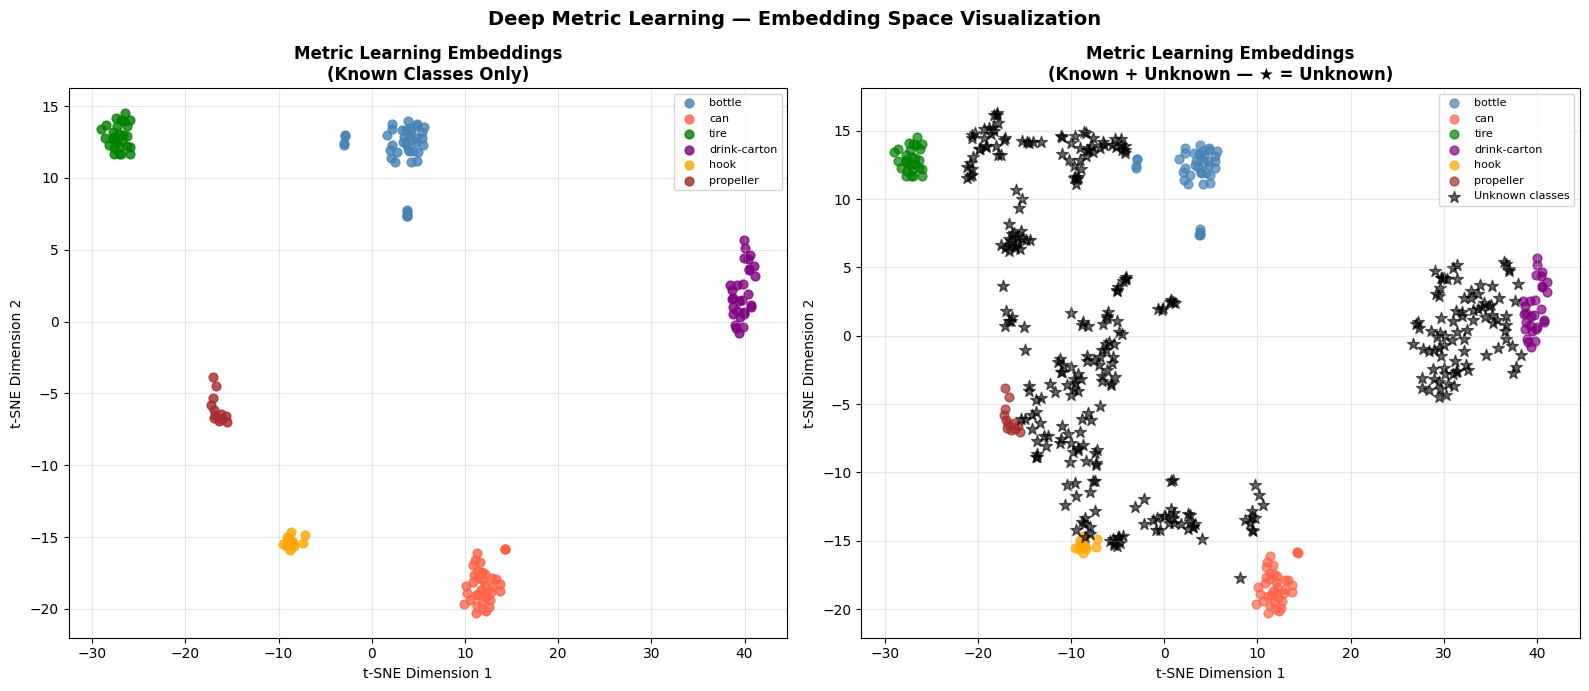

✅ Saved metric_tsne.png
   This is your best visualization for supervisor!


In [52]:
from sklearn.manifold import TSNE

print("Computing t-SNE (this takes ~1-2 minutes)...")

# ── Combine known test + unknown test ─────────────────────
# Use subset for speed
np.random.seed(42)
sample_size = min(500, len(metric_test_emb))
sample_idx  = np.random.choice(
    len(metric_test_emb), sample_size, replace=False
)

sample_emb    = metric_test_emb[sample_idx]
sample_labels = metric_test_labels[sample_idx]

# ── Fit t-SNE ─────────────────────────────────────────────
import inspect
_tsne_iter_kw = {'max_iter': 1000} if 'max_iter' in inspect.signature(TSNE).parameters else {'n_iter': 1000}
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    **_tsne_iter_kw
)
emb_2d = tsne.fit_transform(sample_emb)

# ── Plot ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Colors for known classes
known_colors = [
    'steelblue', 'tomato', 'green',
    'purple', 'orange', 'brown'
]

# ── Plot 1: Known classes only ────────────────────────────
for cls_idx, cls_name in IDX_TO_CLASS.items():
    mask = sample_labels == cls_idx
    if mask.sum() > 0:
        axes[0].scatter(
            emb_2d[mask, 0], emb_2d[mask, 1],
            c=known_colors[cls_idx],
            label=cls_name, s=40, alpha=0.8
        )

axes[0].set_title(
    'Metric Learning Embeddings\n(Known Classes Only)',
    fontsize=12, fontweight='bold'
)
axes[0].legend(fontsize=8, loc='best')
axes[0].grid(alpha=0.3)
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')

# ── Plot 2: Known + Unknown ───────────────────────────────
for cls_idx, cls_name in IDX_TO_CLASS.items():
    mask = sample_labels == cls_idx
    if mask.sum() > 0:
        axes[1].scatter(
            emb_2d[mask, 0], emb_2d[mask, 1],
            c=known_colors[cls_idx],
            label=cls_name, s=40, alpha=0.7
        )

# Unknown classes as stars
unknown_mask = sample_labels == -1
if unknown_mask.sum() > 0:
    axes[1].scatter(
        emb_2d[unknown_mask, 0],
        emb_2d[unknown_mask, 1],
        c='black', marker='*',
        s=80, alpha=0.6,
        label='Unknown classes'
    )

axes[1].set_title(
    'Metric Learning Embeddings\n'
    '(Known + Unknown — ★ = Unknown)',
    fontsize=12, fontweight='bold'
)
axes[1].legend(fontsize=8, loc='best')
axes[1].grid(alpha=0.3)
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')

plt.suptitle(
    'Deep Metric Learning — Embedding Space Visualization',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    f'{FIGURES_DIR}/metric_tsne.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print("✅ Saved metric_tsne.png")
print("   This is your best visualization for supervisor!")

**Save Results**

In [53]:
all_results['MetricLearning'] = {
    'method'     : metric_results['method'],
    'auroc'      : round(float(metric_results['auroc']), 4),
    'ap'         : round(float(metric_results['ap']), 4),
    'tpr'        : round(float(metric_results['tpr']), 4),
    'fpr'        : round(float(metric_results['fpr']), 4),
    'udr'        : round(float(metric_results['udr']), 4),
    'threshold'  : float(metric_results['threshold']),
    'closed_acc' : round(dml_closed_acc, 4),
    'tp'         : int(metric_results['tp']),
    'tn'         : int(metric_results['tn']),
    'fp'         : int(metric_results['fp']),
    'fn'         : int(metric_results['fn']),
    'per_class_detection': {k: round(float(v), 2) for k, v in dml_unknown_detection.items()},
}

with open(f'{RESULTS_DIR}/all_results.json', 'w') as f:
    json.dump(all_results, f, indent=4)

print("✅ All live results saved to all_results.json!")
print("  ", all_results['MetricLearning'])


✅ All live results saved to all_results.json!
   {'method': 'Deep Metric Learning', 'auroc': 0.9603, 'ap': 0.9235, 'tpr': 0.9077, 'fpr': 0.0987, 'udr': 0.9013, 'threshold': -0.23778758943080902, 'closed_acc': 1.0, 'tp': 246, 'tn': 539, 'fp': 59, 'fn': 25, 'per_class_detection': {'chain': 80.53, 'valve': 92.79, 'shampoo-bottle': 100.0, 'standing-bottle': 100.0}}


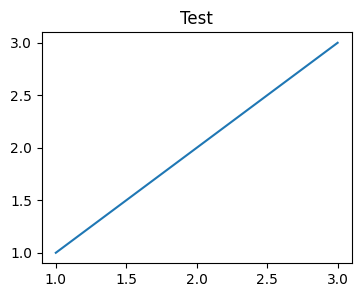

✅ matplotlib working correctly!
   matplotlib version: 3.10.0


In [54]:
# ── Reimport everything cleanly ───────────────────────────
import importlib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# Force reimport
importlib.reload(matplotlib)
importlib.reload(plt)

# Test it works
fig, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.plot([1,2,3], [1,2,3])
plt.title("Test")
plt.show()
plt.close()

print("✅ matplotlib working correctly!")
print(f"   matplotlib version: {matplotlib.__version__}")

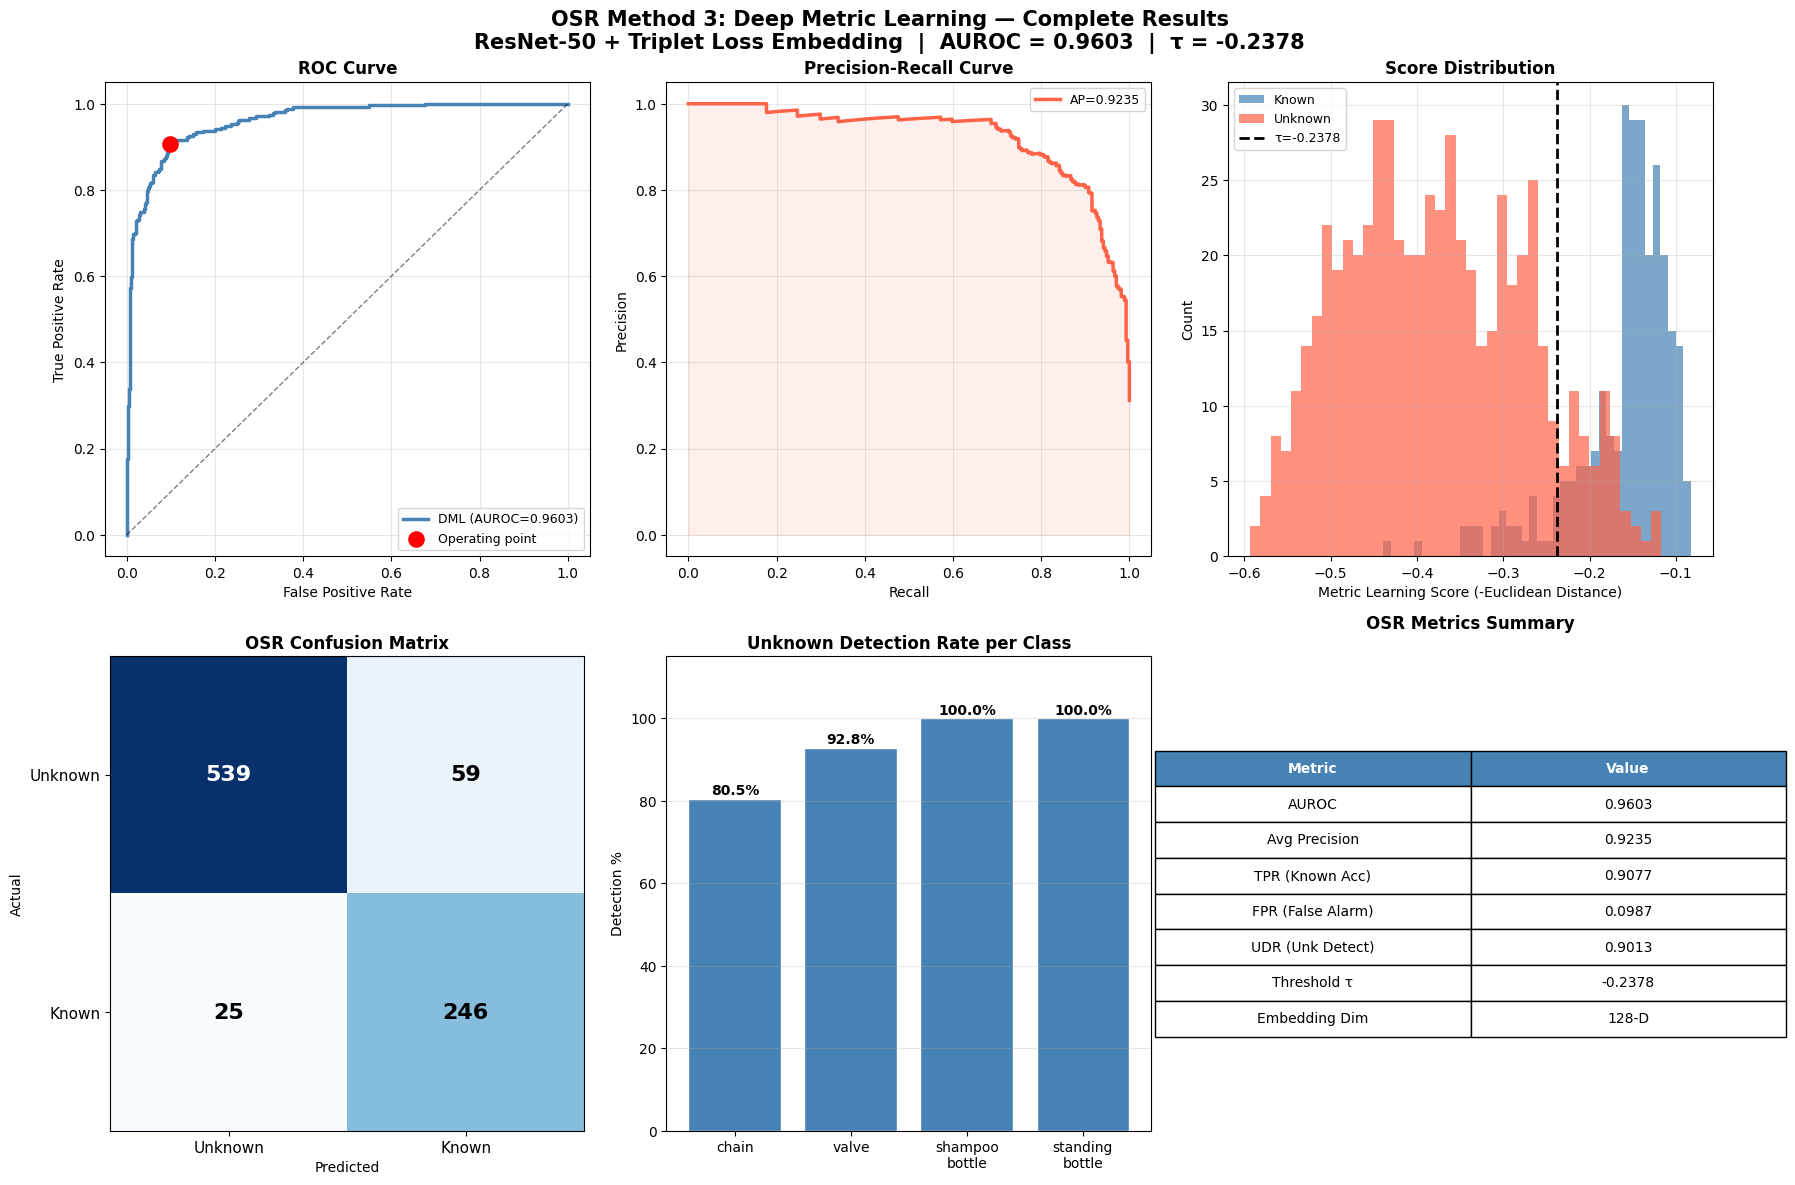

✅ Saved dml_complete_dashboard.png (100% live metrics)


In [55]:
fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'OSR Method 3: Deep Metric Learning — Complete Results\n'
    'ResNet-50 + Triplet Loss Embedding  |  '
    f'AUROC = {metric_results["auroc"]:.4f}  |  τ = {metric_results["threshold"]:.4f}',
    fontsize=15, fontweight='bold', y=0.98
)

binary_labels  = (metric_test_labels != -1).astype(int)
known_scores_m = metric_scores[metric_test_labels != -1]
unk_scores_m   = metric_scores[metric_test_labels == -1]
best_thresh    = metric_results['threshold']

# ── 1. ROC Curve ──────────────────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
fpr_arr, tpr_arr, _ = roc_curve(binary_labels, metric_scores)
auroc = auc(fpr_arr, tpr_arr)

ax1.plot(fpr_arr, tpr_arr, color='steelblue', linewidth=2.5,
         label=f'DML (AUROC={auroc:.4f})')
ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5)
ax1.scatter(metric_results['fpr'], metric_results['tpr'],
            color='red', s=120, zorder=5, label='Operating point')
ax1.set_title('ROC Curve', fontsize=12, fontweight='bold')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

# ── 2. PR Curve ───────────────────────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
prec, rec, _ = precision_recall_curve(binary_labels, metric_scores)
ap = average_precision_score(binary_labels, metric_scores)
ax2.plot(rec, prec, color='tomato', linewidth=2.5, label=f'AP={ap:.4f}')
ax2.fill_between(rec, prec, alpha=0.1, color='tomato')
ax2.set_title('Precision-Recall Curve', fontsize=12, fontweight='bold')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

# ── 3. Score Distribution ─────────────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
ax3.hist(known_scores_m, bins=40, alpha=0.7, color='steelblue',
         label='Known', edgecolor='none')
ax3.hist(unk_scores_m, bins=40, alpha=0.7, color='tomato',
         label='Unknown', edgecolor='none')
ax3.axvline(x=best_thresh, color='black', linestyle='--',
            linewidth=2, label=f'τ={best_thresh:.4f}')
ax3.set_title('Score Distribution', fontsize=12, fontweight='bold')
ax3.set_xlabel('Metric Learning Score (-Euclidean Distance)')
ax3.set_ylabel('Count')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

# ── 4. OSR Confusion Matrix ───────────────────────────────
ax4 = fig.add_subplot(2, 3, 4)
pred_known = (metric_scores >= best_thresh).astype(int)
dml_cm     = confusion_matrix(binary_labels, pred_known)
im = ax4.imshow(dml_cm, cmap='Blues')
ax4.set_xticks([0, 1])
ax4.set_yticks([0, 1])
ax4.set_xticklabels(['Unknown', 'Known'], fontsize=11)
ax4.set_yticklabels(['Unknown', 'Known'], fontsize=11)
thresh_cm = dml_cm.max() / 2
for i in range(2):
    for j in range(2):
        color = 'white' if dml_cm[i, j] > thresh_cm else 'black'
        ax4.text(j, i, str(dml_cm[i, j]),
                 ha='center', va='center',
                 fontsize=16, fontweight='bold', color=color)
ax4.set_title('OSR Confusion Matrix', fontsize=12, fontweight='bold')
ax4.set_xlabel('Predicted')
ax4.set_ylabel('Actual')

# ── 5. Per Unknown Detection Rate ─────────────────────────
ax5 = fig.add_subplot(2, 3, 5)
dml_unknown_detection = {}
for cls in UNKNOWN_CLASSES:
    cls_idx = [i for i, (path, label) in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]
    if not cls_idx:
        continue
    cls_scores = metric_scores[cls_idx]
    rejected   = (cls_scores < best_thresh).sum()
    dml_unknown_detection[cls] = 100.0 * rejected / len(cls_scores)

colors_bar = ['tomato' if v < 50 else 'orange' if v < 80 else 'steelblue'
              for v in dml_unknown_detection.values()]
bars = ax5.bar([c.replace('-', '\n') for c in dml_unknown_detection.keys()],
               dml_unknown_detection.values(),
               color=colors_bar, edgecolor='white')
for bar, val in zip(bars, dml_unknown_detection.values()):
    ax5.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax5.set_ylim(0, 115)
ax5.set_title('Unknown Detection Rate per Class', fontsize=12, fontweight='bold')
ax5.set_ylabel('Detection %')
ax5.grid(axis='y', alpha=0.3)

# ── 6. Metrics Summary Table (100% LIVE) ──────────────────
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
metrics_data = [
    ['Metric',            'Value'],
    ['AUROC',             f'{metric_results["auroc"]:.4f}'],
    ['Avg Precision',     f'{metric_results["ap"]:.4f}'],
    ['TPR (Known Acc)',   f'{metric_results["tpr"]:.4f}'],
    ['FPR (False Alarm)', f'{metric_results["fpr"]:.4f}'],
    ['UDR (Unk Detect)',  f'{metric_results["udr"]:.4f}'],
    ['Threshold τ',       f'{metric_results["threshold"]:.4f}'],
    ['Embedding Dim',     f'{EMBEDDING_DIM}-D'],
]
table = ax6.table(cellText=metrics_data[1:], colLabels=metrics_data[0],
                  loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.3, 1.9)
for j in range(2):
    table[0, j].set_facecolor('steelblue')
    table[0, j].set_text_props(color='white', fontweight='bold')
ax6.set_title('OSR Metrics Summary', fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/dml_complete_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved dml_complete_dashboard.png (100% live metrics)")


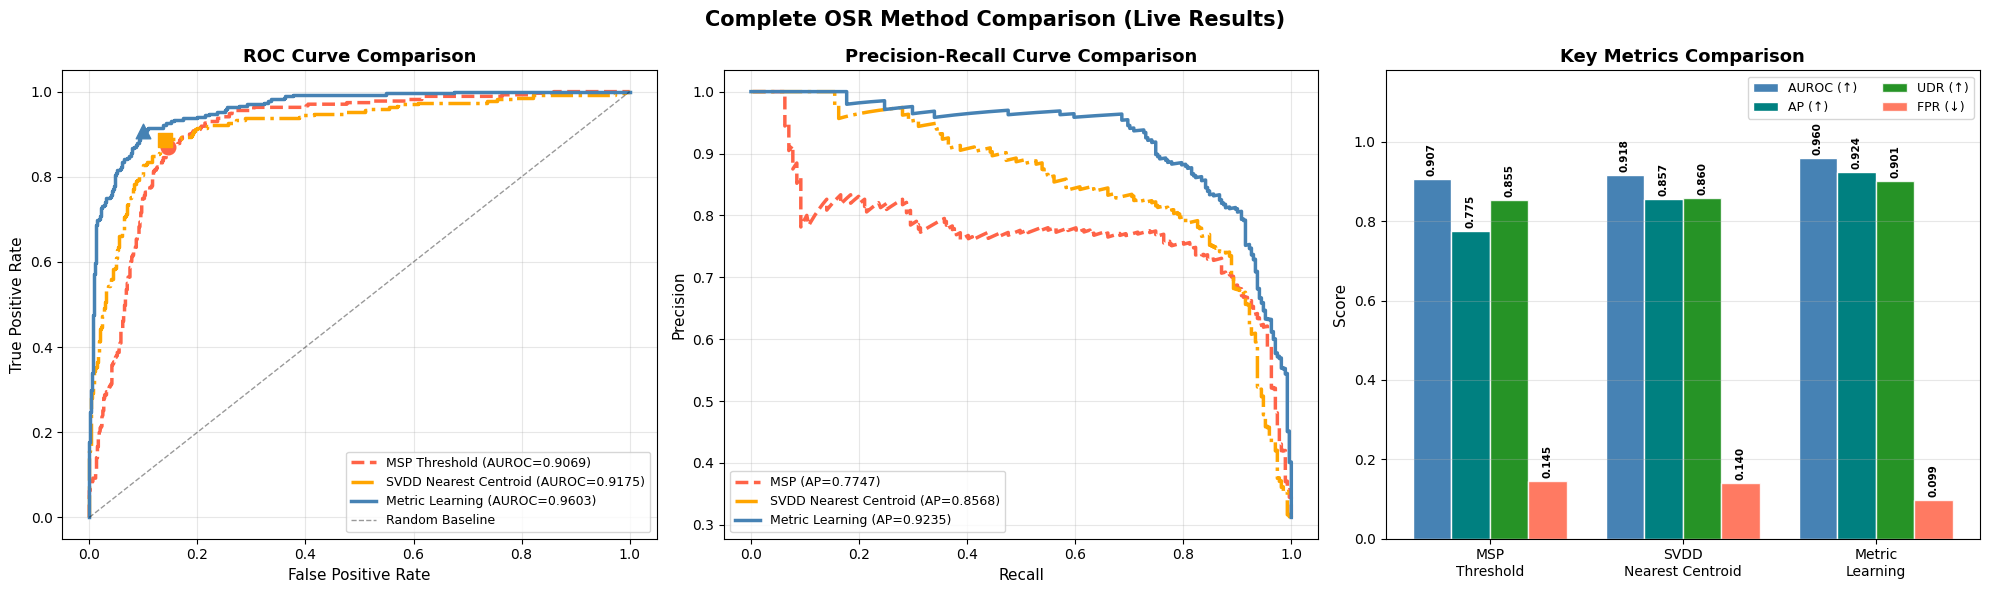

✅ Saved all_methods_comparison.png (100% live metrics)


In [56]:
# ── Recompute all ROC & PR curves dynamically ─────────────
binary_labels_all = (test_labels != -1).astype(int)

fpr_msp,  tpr_msp,  _ = roc_curve(binary_labels_all, msp_scores)
fpr_svdd, tpr_svdd, _ = roc_curve(binary_labels_all, best_svdd['scores'])
fpr_dml,  tpr_dml,  _ = roc_curve(binary_labels_all, metric_scores)

prec_msp,  rec_msp,  _ = precision_recall_curve(binary_labels_all, msp_scores)
prec_svdd, rec_svdd, _ = precision_recall_curve(binary_labels_all, best_svdd['scores'])
prec_dml,  rec_dml,  _ = precision_recall_curve(binary_labels_all, metric_scores)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ── 1. ROC Comparison ─────────────────────────────────────
axes[0].plot(fpr_msp, tpr_msp, color='tomato', linewidth=2.5, linestyle='--',
             label=f'MSP Threshold (AUROC={msp_results["auroc"]:.4f})')
axes[0].plot(fpr_svdd, tpr_svdd, color='orange', linewidth=2.5, linestyle='-.',
             label=f'SVDD {best_svdd["method"]} (AUROC={best_svdd["auroc"]:.4f})')
axes[0].plot(fpr_dml, tpr_dml, color='steelblue', linewidth=2.5,
             label=f'Metric Learning (AUROC={metric_results["auroc"]:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.4, label='Random Baseline')

axes[0].scatter(msp_results['fpr'],    msp_results['tpr'],    color='tomato',    s=110, zorder=5, marker='o')
axes[0].scatter(best_svdd['fpr'],      best_svdd['tpr'],      color='orange',    s=110, zorder=5, marker='s')
axes[0].scatter(metric_results['fpr'], metric_results['tpr'], color='steelblue', s=110, zorder=5, marker='^')

axes[0].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].legend(fontsize=9, loc='lower right')
axes[0].grid(alpha=0.3)

# ── 2. Precision-Recall Comparison ────────────────────────
axes[1].plot(rec_msp, prec_msp, color='tomato', linewidth=2.5, linestyle='--',
             label=f'MSP (AP={msp_results["ap"]:.4f})')
axes[1].plot(rec_svdd, prec_svdd, color='orange', linewidth=2.5, linestyle='-.',
             label=f'SVDD {best_svdd["method"]} (AP={best_svdd["ap"]:.4f})')
axes[1].plot(rec_dml, prec_dml, color='steelblue', linewidth=2.5,
             label=f'Metric Learning (AP={metric_results["ap"]:.4f})')

axes[1].set_title('Precision-Recall Curve Comparison', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].legend(fontsize=9, loc='lower left')
axes[1].grid(alpha=0.3)

# ── 3. Bar Chart Comparison (100% LIVE) ───────────────────
methods = ['MSP\nThreshold', f'SVDD\n{best_svdd["method"]}', 'Metric\nLearning']
aurocs  = [msp_results['auroc'], best_svdd['auroc'], metric_results['auroc']]
aps     = [msp_results['ap'],    best_svdd['ap'],    metric_results['ap']]
udrs    = [msp_results['udr'],   best_svdd['udr'],   metric_results['udr']]
fprs    = [msp_results['fpr'],   best_svdd['fpr'],   metric_results['fpr']]

x = np.arange(len(methods))
w = 0.20

b1 = axes[2].bar(x - 1.5*w, aurocs, w, label='AUROC (↑)', color='steelblue', edgecolor='white')
b2 = axes[2].bar(x - 0.5*w, aps,    w, label='AP (↑)',    color='teal',      edgecolor='white')
b3 = axes[2].bar(x + 0.5*w, udrs,   w, label='UDR (↑)',   color='green',     edgecolor='white', alpha=0.85)
b4 = axes[2].bar(x + 1.5*w, fprs,   w, label='FPR (↓)',   color='tomato',    edgecolor='white', alpha=0.85)

for bars in [b1, b2, b3, b4]:
    for bar in bars:
        axes[2].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.012,
            f'{bar.get_height():.3f}',
            ha='center', fontsize=7.5, fontweight='bold', rotation=90
        )

axes[2].set_xticks(x)
axes[2].set_xticklabels(methods, fontsize=10)
axes[2].set_ylim(0, 1.18)
axes[2].set_ylabel('Score', fontsize=11)
axes[2].set_title('Key Metrics Comparison', fontsize=13, fontweight='bold')
axes[2].legend(fontsize=9, ncol=2)
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Complete OSR Method Comparison (Live Results)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/all_methods_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved all_methods_comparison.png (100% live metrics)")


**Per Class Unknown Detection All Methods**

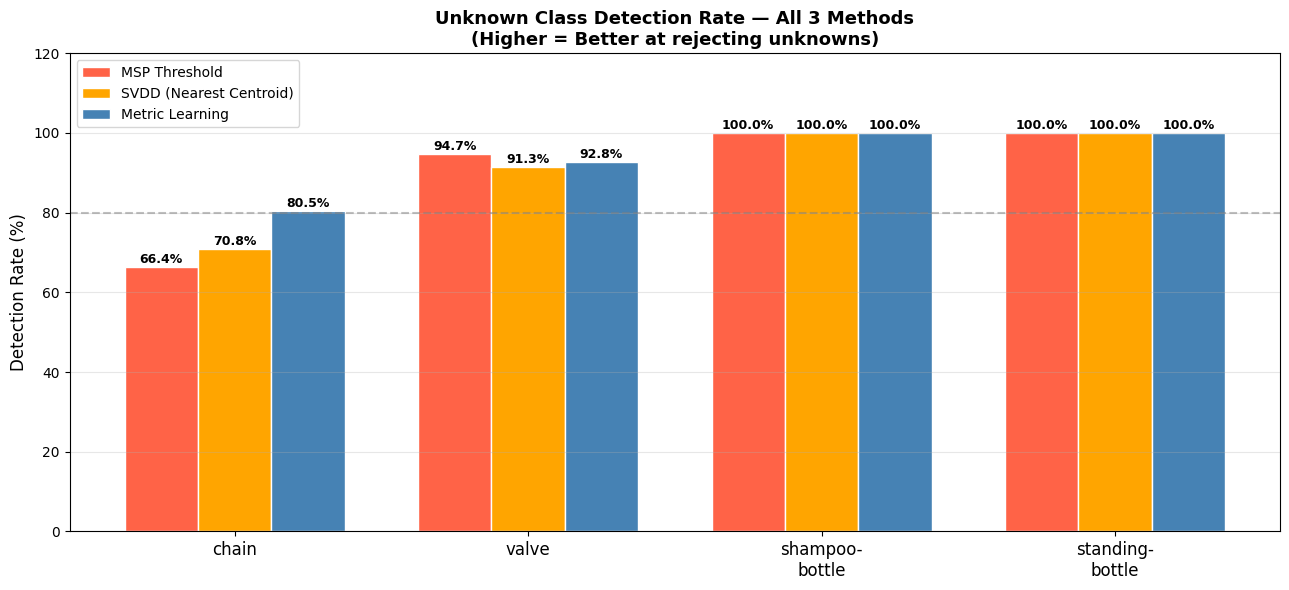

✅ Saved all_methods_unknown_detection.png (100% live metrics)


In [57]:
# ── Compare unknown detection across all 3 methods (100% LIVE) ──
msp_det  = unknown_detection
svdd_det = svdd_unknown_detection
dml_det  = {}

for cls in UNKNOWN_CLASSES:
    cls_idx = [i for i, (path, label) in enumerate(test_list)
               if label == -1 and os.path.basename(os.path.dirname(path)) == cls]
    if not cls_idx:
        continue
    cls_sc   = metric_scores[cls_idx]
    rejected = (cls_sc < metric_results['threshold']).sum()
    dml_det[cls] = round(100.0 * rejected / len(cls_sc), 1)

fig, ax = plt.subplots(figsize=(13, 6))

classes_short = [c.replace('-', '-\n') for c in UNKNOWN_CLASSES]
x = np.arange(len(UNKNOWN_CLASSES))
w = 0.25

msp_vals  = [msp_det.get(c, 0.0)  for c in UNKNOWN_CLASSES]
svdd_vals = [svdd_det.get(c, 0.0) for c in UNKNOWN_CLASSES]
dml_vals  = [dml_det.get(c, 0.0)  for c in UNKNOWN_CLASSES]

b1 = ax.bar(x - w, msp_vals,  w, label='MSP Threshold', color='tomato',    edgecolor='white')
b2 = ax.bar(x,     svdd_vals, w, label=f'SVDD ({best_svdd["method"]})', color='orange', edgecolor='white')
b3 = ax.bar(x + w, dml_vals,  w, label='Metric Learning', color='steelblue', edgecolor='white')

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f'{bar.get_height():.1f}%',
            ha='center', fontsize=9, fontweight='bold'
        )

ax.set_xticks(x)
ax.set_xticklabels(classes_short, fontsize=12)
ax.set_ylim(0, 120)
ax.set_ylabel('Detection Rate (%)', fontsize=12)
ax.set_title(
    'Unknown Class Detection Rate — All 3 Methods\n'
    '(Higher = Better at rejecting unknowns)',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=10)
ax.axhline(y=80, color='gray', linestyle='--', alpha=0.5)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/all_methods_unknown_detection.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved all_methods_unknown_detection.png (100% live metrics)")


**t-SNE Embedding Visualization**

Computing t-SNE (1-2 mins)...


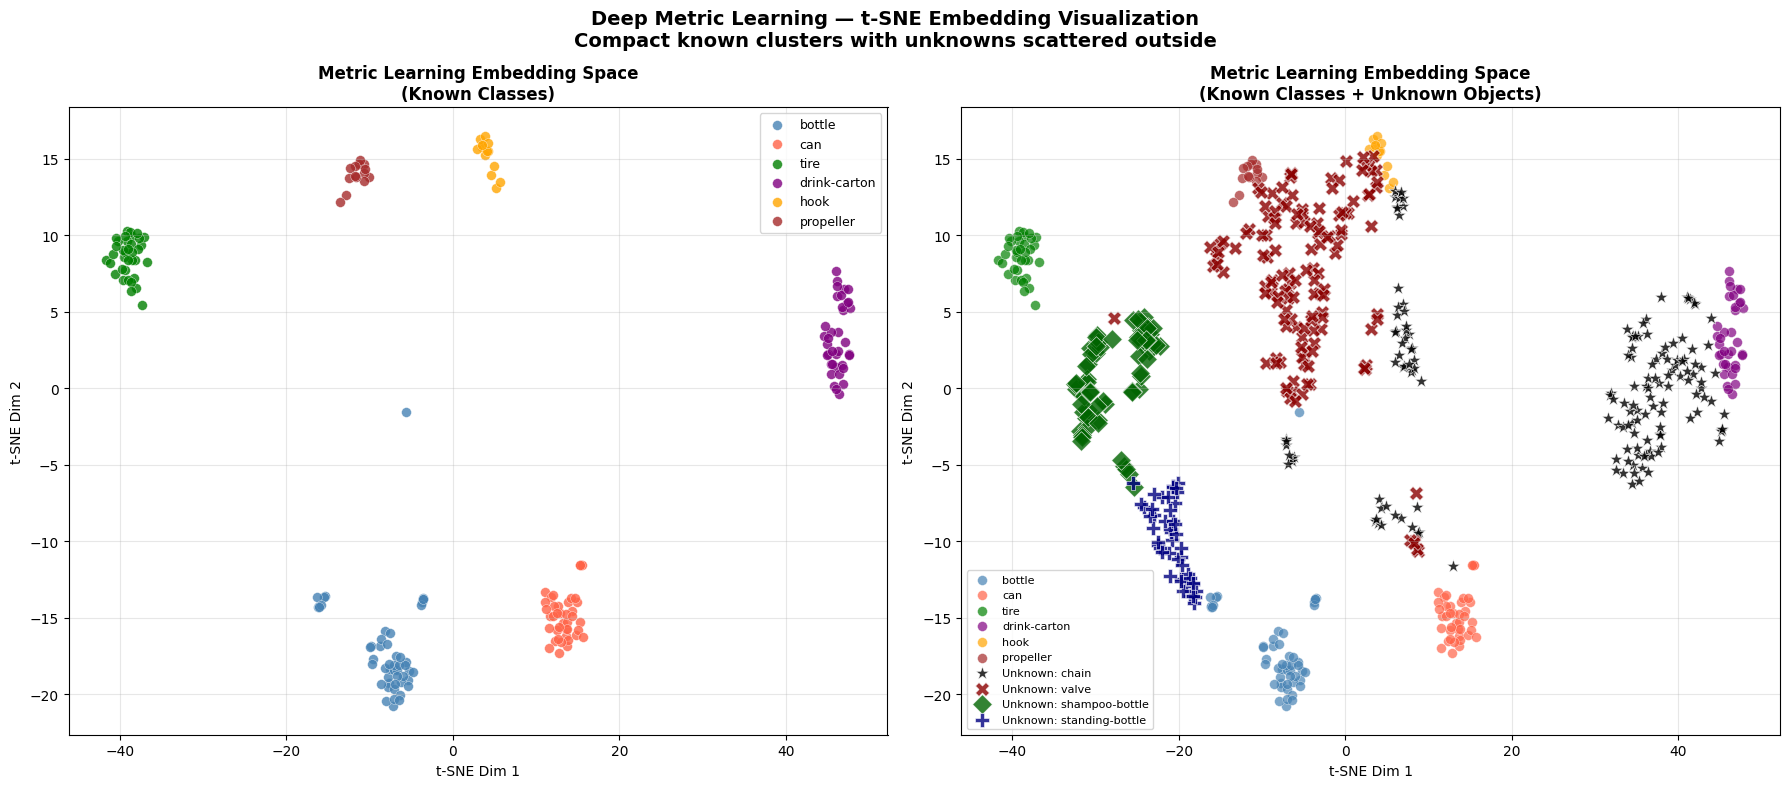

✅ Saved dml_tsne_visualization.png


In [58]:
from sklearn.manifold import TSNE

print("Computing t-SNE (1-2 mins)...")

np.random.seed(42)
sample_size = min(600, len(metric_test_emb))
sample_idx  = np.random.choice(
    len(metric_test_emb), sample_size, replace=False
)
sample_emb    = metric_test_emb[sample_idx]
sample_labels = metric_test_labels[sample_idx]

import inspect
_tsne_iter_kw = {'max_iter': 1000} if 'max_iter' in inspect.signature(TSNE).parameters else {'n_iter': 1000}
tsne  = TSNE(n_components=2, perplexity=30,
              random_state=42, **_tsne_iter_kw)
emb2d = tsne.fit_transform(sample_emb)

known_colors = ['steelblue','tomato','green',
                 'purple','orange','brown']

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ── Plot 1: Known classes only ────────────────────────────
for cls_idx, cls_name in IDX_TO_CLASS.items():
    mask = sample_labels == cls_idx
    if mask.sum() > 0:
        axes[0].scatter(
            emb2d[mask, 0], emb2d[mask, 1],
            c=known_colors[cls_idx],
            label=cls_name, s=50, alpha=0.8,
            edgecolors='white', linewidths=0.3
        )
axes[0].set_title(
    'Metric Learning Embedding Space\n(Known Classes)',
    fontsize=12, fontweight='bold'
)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)
axes[0].set_xlabel('t-SNE Dim 1')
axes[0].set_ylabel('t-SNE Dim 2')

# ── Plot 2: Known + Unknown ───────────────────────────────
for cls_idx, cls_name in IDX_TO_CLASS.items():
    mask = sample_labels == cls_idx
    if mask.sum() > 0:
        axes[1].scatter(
            emb2d[mask, 0], emb2d[mask, 1],
            c=known_colors[cls_idx],
            label=cls_name, s=50, alpha=0.7,
            edgecolors='white', linewidths=0.3
        )

# Unknown classes — different markers per class
unk_markers = ['*', 'X', 'D', 'P']
unk_colors  = ['black','darkred','darkgreen','navy']
for i, cls in enumerate(UNKNOWN_CLASSES):
    cls_indices = [j for j, (path, label)
                   in enumerate(test_list)
                   if label == -1 and cls in path]
    # Find which sample_idx correspond to these
    unk_mask = np.array([
        j for j, idx in enumerate(sample_idx)
        if idx < len(test_list) and
           test_list[idx][1] == -1 and
           os.path.basename(os.path.dirname(test_list[idx][0])) == cls
    ])
    if len(unk_mask) > 0:
        axes[1].scatter(
            emb2d[unk_mask, 0],
            emb2d[unk_mask, 1],
            c=unk_colors[i],
            marker=unk_markers[i],
            s=100, alpha=0.8,
            label=f'Unknown: {cls}',
            edgecolors='white', linewidths=0.5
        )

axes[1].set_title(
    'Metric Learning Embedding Space\n'
    '(Known Classes + Unknown Objects)',
    fontsize=12, fontweight='bold'
)
axes[1].legend(fontsize=8, loc='best')
axes[1].grid(alpha=0.3)
axes[1].set_xlabel('t-SNE Dim 1')
axes[1].set_ylabel('t-SNE Dim 2')

plt.suptitle(
    'Deep Metric Learning — t-SNE Embedding Visualization\n'
    'Compact known clusters with unknowns scattered outside',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    f'{FIGURES_DIR}/dml_tsne_visualization.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print("✅ Saved dml_tsne_visualization.png")

**Final Summary Dashboard All Methods**

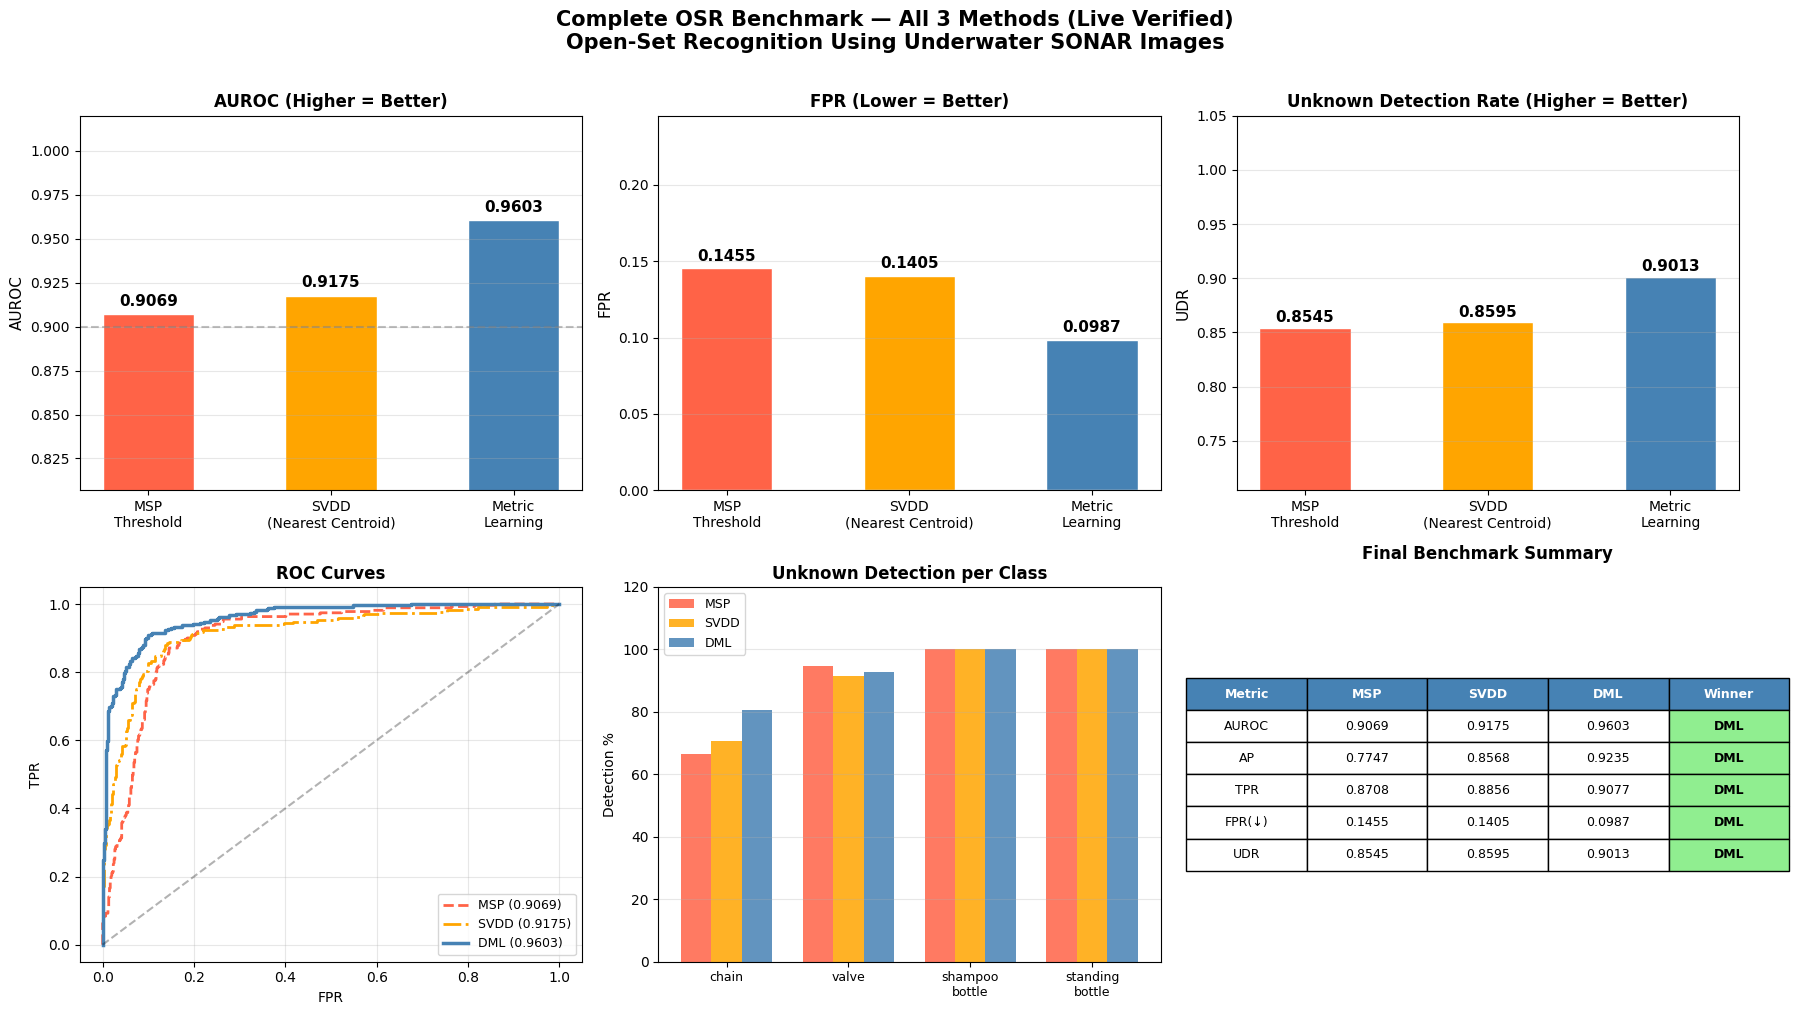

✅ Saved final_benchmark_dashboard.png and benchmark_summary.csv (100% live metrics)!


In [59]:
import csv

fig = plt.figure(figsize=(18, 10))
fig.suptitle(
    'Complete OSR Benchmark — All 3 Methods (Live Verified)\n'
    'Open-Set Recognition Using Underwater SONAR Images',
    fontsize=15, fontweight='bold', y=1.01
)

methods = ['MSP\nThreshold', f'SVDD\n({best_svdd["method"]})', 'Metric\nLearning']
aurocs  = [msp_results['auroc'], best_svdd['auroc'], metric_results['auroc']]
aps     = [msp_results['ap'],    best_svdd['ap'],    metric_results['ap']]
tprs    = [msp_results['tpr'],   best_svdd['tpr'],   metric_results['tpr']]
fprs    = [msp_results['fpr'],   best_svdd['fpr'],   metric_results['fpr']]
udrs    = [msp_results['udr'],   best_svdd['udr'],   metric_results['udr']]
colors  = ['tomato', 'orange', 'steelblue']

# ── 1. AUROC comparison ───────────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
bars = ax1.bar(methods, aurocs, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, aurocs):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontweight='bold', fontsize=11)
ax1.set_ylim(max(0.5, min(aurocs) - 0.1), 1.02)
ax1.set_ylabel('AUROC', fontsize=11)
ax1.set_title('AUROC (Higher = Better)', fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
ax1.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)

# ── 2. FPR comparison ─────────────────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
bars = ax2.bar(methods, fprs, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, fprs):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontweight='bold', fontsize=11)
ax2.set_ylim(0, max(fprs) + 0.1)
ax2.set_ylabel('FPR', fontsize=11)
ax2.set_title('FPR (Lower = Better)', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# ── 3. UDR comparison ─────────────────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
bars = ax3.bar(methods, udrs, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, udrs):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontweight='bold', fontsize=11)
ax3.set_ylim(max(0.4, min(udrs) - 0.15), 1.05)
ax3.set_ylabel('UDR', fontsize=11)
ax3.set_title('Unknown Detection Rate (Higher = Better)', fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

# ── 4. All ROC curves ─────────────────────────────────────
ax4 = fig.add_subplot(2, 3, 4)
ax4.plot(fpr_msp,  tpr_msp,  color='tomato',    linewidth=2, linestyle='--',
         label=f'MSP ({msp_results["auroc"]:.4f})')
ax4.plot(fpr_svdd, tpr_svdd, color='orange',    linewidth=2, linestyle='-.',
         label=f'SVDD ({best_svdd["auroc"]:.4f})')
ax4.plot(fpr_dml,  tpr_dml,  color='steelblue', linewidth=2.5,
         label=f'DML ({metric_results["auroc"]:.4f})')
ax4.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax4.set_title('ROC Curves', fontweight='bold')
ax4.set_xlabel('FPR')
ax4.set_ylabel('TPR')
ax4.legend(fontsize=9)
ax4.grid(alpha=0.3)

# ── 5. Unknown detection per class (100% LIVE) ────────────
ax5 = fig.add_subplot(2, 3, 5)
classes_s = [c.replace('-', '\n') for c in UNKNOWN_CLASSES]
x = np.arange(len(UNKNOWN_CLASSES))
w = 0.25
msp_v  = [unknown_detection.get(c, 0.0)      for c in UNKNOWN_CLASSES]
svdd_v = [svdd_unknown_detection.get(c, 0.0) for c in UNKNOWN_CLASSES]
dml_v  = [dml_unknown_detection.get(c, 0.0)  for c in UNKNOWN_CLASSES]

ax5.bar(x - w, msp_v,  w, label='MSP',  color='tomato',    alpha=0.85)
ax5.bar(x,     svdd_v, w, label='SVDD', color='orange',    alpha=0.85)
ax5.bar(x + w, dml_v,  w, label='DML',  color='steelblue', alpha=0.85)
ax5.set_xticks(x)
ax5.set_xticklabels(classes_s, fontsize=9)
ax5.set_ylim(0, 120)
ax5.set_ylabel('Detection %')
ax5.set_title('Unknown Detection per Class', fontweight='bold')
ax5.legend(fontsize=9)
ax5.grid(axis='y', alpha=0.3)

# ── 6. Final metrics table (100% LIVE + Dynamic Winner) ───
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
short_names = ['MSP', 'SVDD', 'DML']

def winner_name(vals, lower_better=False):
    idx = int(np.argmin(vals)) if lower_better else int(np.argmax(vals))
    return short_names[idx]

table_data = [
    ['Metric', 'MSP', 'SVDD', 'DML', 'Winner'],
    ['AUROC',  f'{aurocs[0]:.4f}', f'{aurocs[1]:.4f}', f'{aurocs[2]:.4f}', winner_name(aurocs)],
    ['AP',     f'{aps[0]:.4f}',    f'{aps[1]:.4f}',    f'{aps[2]:.4f}',    winner_name(aps)],
    ['TPR',    f'{tprs[0]:.4f}',   f'{tprs[1]:.4f}',   f'{tprs[2]:.4f}',   winner_name(tprs)],
    ['FPR(↓)', f'{fprs[0]:.4f}',   f'{fprs[1]:.4f}',   f'{fprs[2]:.4f}',   winner_name(fprs, lower_better=True)],
    ['UDR',    f'{udrs[0]:.4f}',   f'{udrs[1]:.4f}',   f'{udrs[2]:.4f}',   winner_name(udrs)],
]

table = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                  loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.8)
for j in range(5):
    table[0, j].set_facecolor('steelblue')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(1, 6):
    table[i, 4].set_facecolor('lightgreen')
    table[i, 4].set_text_props(fontweight='bold')

ax6.set_title('Final Benchmark Summary', fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/final_benchmark_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Save clean CSV summary ────────────────────────────────
csv_path = f'{RESULTS_DIR}/benchmark_summary.csv'
with open(csv_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['Method', 'AUROC', 'AP', 'TPR', 'FPR', 'UDR', 'Threshold'])
    writer.writerow(['MSP Threshold', f'{aurocs[0]:.4f}', f'{aps[0]:.4f}', f'{tprs[0]:.4f}', f'{fprs[0]:.4f}', f'{udrs[0]:.4f}', f'{msp_results["threshold"]:.4f}'])
    writer.writerow([f'SVDD ({best_svdd["method"]})', f'{aurocs[1]:.4f}', f'{aps[1]:.4f}', f'{tprs[1]:.4f}', f'{fprs[1]:.4f}', f'{udrs[1]:.4f}', f'{best_svdd["threshold"]:.4f}'])
    writer.writerow(['Deep Metric Learning', f'{aurocs[2]:.4f}', f'{aps[2]:.4f}', f'{tprs[2]:.4f}', f'{fprs[2]:.4f}', f'{udrs[2]:.4f}', f'{metric_results["threshold"]:.4f}'])

print("✅ Saved final_benchmark_dashboard.png and benchmark_summary.csv (100% live metrics)!")


# Phase 2 turntable dataset testing

**Load Turntable Dataset**

In [60]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from PIL import Image

print("✅ All imports ready!")

✅ All imports ready!


In [61]:
# ── Turntable dataset path (Auto-detect Kaggle vs Local) ──
KAGGLE_TURNTABLE = '/kaggle/input/datasets/mariyaabdul/marine-debris-fls/marine-debris-fls-datasets/md_fls_dataset/data/turntable-cropped'
LOCAL_TURNTABLE  = os.path.join(os.getcwd(), 'md_fls_dataset', 'data', 'turntable-cropped')
TURNTABLE_PATH   = KAGGLE_TURNTABLE if os.path.exists(KAGGLE_TURNTABLE) else LOCAL_TURNTABLE

if not os.path.exists(TURNTABLE_PATH):
    print(f"⚠️ Turntable path not found: {TURNTABLE_PATH}")
else:
    print("Turntable Dataset Classes:")
    print("=" * 50)

    turntable_classes = sorted([
        c for c in os.listdir(TURNTABLE_PATH)
        if os.path.isdir(os.path.join(TURNTABLE_PATH, c))
    ])

    turntable_counts = {}
    total_turntable  = 0

    for cls in turntable_classes:
        imgs = sorted([f for f in os.listdir(os.path.join(TURNTABLE_PATH, cls))
                       if f.lower().endswith(('.png','.jpg','.jpeg','.bmp'))])
        turntable_counts[cls] = len(imgs)
        total_turntable += len(imgs)
        print(f"  {cls:<25} → {len(imgs):>4} images")

    print(f"\n  {'TOTAL':<25} → {total_turntable:>4} images")


Turntable Dataset Classes:
  brown-glass-bottle        →  210 images
  can                       →  410 images
  drink-carton              →  428 images
  drink-sachet              →  222 images
  glass-bottle              →  480 images
  glass-jar                 →  432 images
  large-tire                →  204 images
  metal-bottle              →  222 images
  metal-box                 →  176 images
  plastic-bidon             →  196 images
  plastic-bottle            →  440 images
  plastic-pipe              →  220 images
  plastic-propeller         →  224 images
  potion-glass-bottle       →  218 images
  rotating-platform         →  186 images
  small-tire                →  234 images
  valve                     →  200 images
  wrench                    →  240 images

  TOTAL                     → 4942 images


In [62]:
import json, os
import numpy as np
import torch

DEPLOY_DIR = f'{WORK_DIR}/deploy'
os.makedirs(DEPLOY_DIR, exist_ok=True)

# 1. Network weights (the best weights are currently loaded in memory)
torch.save(model.state_dict(),           f'{DEPLOY_DIR}/resnet50_baseline.pth')
torch.save(embedding_model.state_dict(), f'{DEPLOY_DIR}/embedding_model.pth')

# 2. Class centroids for SVDD (2048-D) and DML (128-D)
svdd_centroids = np.stack([class_centroids[i].numpy() for i in range(NUM_CLASSES)])
dml_centroids  = np.stack([metric_centroids[i]        for i in range(NUM_CLASSES)])
np.savez(f'{DEPLOY_DIR}/centroids.npz', svdd=svdd_centroids, dml=dml_centroids)

# 3. Thresholds, class names, normalization constants
config = {
    'known_classes': KNOWN_CLASSES,
    'embedding_dim': EMBEDDING_DIM,
    'thresholds': {
        'msp' : float(BEST_THRESHOLD_MSP),
        'svdd': float(best_svdd['threshold']),
        'dml' : float(metric_results['threshold']),
    },
    'imagenet_mean': IMAGENET_MEAN,
    'imagenet_std' : IMAGENET_STD,
}
with open(f'{DEPLOY_DIR}/config.json', 'w') as f:
    json.dump(config, f, indent=2)

print("Saved:", os.listdir(DEPLOY_DIR))
print("Thresholds:", config['thresholds'])

Saved: ['embedding_model.pth', 'resnet50_baseline.pth', 'centroids.npz', 'config.json']
Thresholds: {'msp': 0.9980217218399048, 'svdd': -13.839166641235352, 'dml': -0.23778758943080902}


In [63]:
inference_code = "import json\nimport numpy as np\nimport cv2\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport torchvision.models as models\nimport torchvision.transforms as T\nfrom PIL import Image\n\n\ndef build_resnet50(num_classes):\n    m = models.resnet50(weights=None)\n    m.fc = nn.Sequential(\n        nn.Dropout(0.3), nn.Linear(2048, 512), nn.ReLU(),\n        nn.Dropout(0.2), nn.Linear(512, num_classes))\n    return m\n\n\nclass EmbeddingNet(nn.Module):\n    def __init__(self, embedding_dim=128):\n        super().__init__()\n        resnet = models.resnet50(weights=None)\n        self.backbone = nn.Sequential(*list(resnet.children())[:-1])\n        self.projector = nn.Sequential(\n            nn.Linear(2048, 512), nn.BatchNorm1d(512), nn.ReLU(),\n            nn.Dropout(0.3), nn.Linear(512, embedding_dim))\n\n    def forward(self, x):\n        f = self.backbone(x).flatten(start_dim=1)\n        return F.normalize(self.projector(f), p=2, dim=1)\n\n\ndef preprocess_sonar(img: Image.Image) -> Image.Image:\n    rgb  = np.array(img.convert('RGB'))          # drops the alpha channel\n    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)\n    gray = cv2.medianBlur(gray, 3)\n    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)\n    return Image.fromarray(cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB))\n\n\nclass OSRPredictor:\n    def __init__(self, deploy_dir, device=None):\n        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')\n        cfg = json.load(open(f'{deploy_dir}/config.json'))\n        self.classes = cfg['known_classes']\n        self.th      = cfg['thresholds']\n        c = np.load(f'{deploy_dir}/centroids.npz')\n        self.c_svdd, self.c_dml = c['svdd'], c['dml']\n\n        self.clf = build_resnet50(len(self.classes))\n        self.clf.load_state_dict(torch.load(\n            f'{deploy_dir}/resnet50_baseline.pth', map_location=self.device))\n        self.clf.to(self.device).eval()\n        # same network minus the final FC layer -> 2048-D features for SVDD\n        self.extractor = nn.Sequential(*list(self.clf.children())[:-1])\n\n        self.emb = EmbeddingNet(cfg['embedding_dim'])\n        self.emb.load_state_dict(torch.load(\n            f'{deploy_dir}/embedding_model.pth', map_location=self.device))\n        self.emb.to(self.device).eval()\n\n        self.tf = T.Compose([\n            T.Resize((224, 224)), T.ToTensor(),\n            T.Normalize(cfg['imagenet_mean'], cfg['imagenet_std'])])\n\n    def _verdict(self, score, threshold, cls_idx):\n        known = score >= threshold\n        return {'status': 'known' if known else 'unknown',\n                'class': self.classes[cls_idx] if known else None,\n                'score': score, 'threshold': threshold}\n\n    @torch.no_grad()\n    def predict(self, image: Image.Image):\n        x = self.tf(preprocess_sonar(image)).unsqueeze(0).to(self.device)\n\n        probs = torch.softmax(self.clf(x), dim=1)[0].cpu().numpy()          # MSP\n        feat  = self.extractor(x).flatten(1)[0].cpu().numpy()               # SVDD\n        d_s   = np.linalg.norm(self.c_svdd - feat, axis=1)\n        emb   = self.emb(x)[0].cpu().numpy()                                # DML\n        d_m   = np.linalg.norm(self.c_dml - emb, axis=1)\n\n        return {\n            'msp' : self._verdict(float(probs.max()), self.th['msp'],  int(probs.argmax())),\n            'svdd': self._verdict(float(-d_s.min()),  self.th['svdd'], int(d_s.argmin())),\n            'dml' : self._verdict(float(-d_m.min()),  self.th['dml'],  int(d_m.argmin())),\n            'class_probabilities': {c: float(p) for c, p in zip(self.classes, probs)},\n        }"
with open(os.path.join(DEPLOY_DIR, 'inference.py'), 'w') as f:
    f.write(inference_code)
print('Saved:', os.path.join(DEPLOY_DIR, 'inference.py'))


Saved: /kaggle/working/deploy/inference.py


In [64]:
import sys
if DEPLOY_DIR not in sys.path:
    sys.path.append(DEPLOY_DIR)
from inference import OSRPredictor
from PIL import Image

predictor = OSRPredictor(DEPLOY_DIR)

known_path   = next(p for p, l in test_list if l != -1)
unknown_path = next(p for p, l in test_list if l == -1)

for path in [known_path, unknown_path]:
    print(os.path.basename(os.path.dirname(path)))
    for method, r in predictor.predict(Image.open(path)).items():
        if method != 'class_probabilities':
            print(f"  {method:<5} {r['status']:<8} {r['class']}  score={r['score']:.4f}")

i = [p for p, _ in test_list].index(known_path)
print("\nNotebook scores  MSP/DML/SVDD:",
      round(float(msp_scores[i]), 4), round(float(metric_scores[i]), 4), round(float(best_svdd['scores'][i]), 4))


bottle
  msp   known    bottle  score=0.9999
  svdd  known    bottle  score=-10.4573
  dml   known    bottle  score=-0.1694
chain
  msp   known    hook  score=0.9999
  svdd  unknown  None  score=-27.0109
  dml   unknown  None  score=-0.4876

Notebook scores  MSP/DML/SVDD: 0.9999 -0.1694 -10.4573


In [65]:
import shutil
from IPython.display import FileLink

shutil.make_archive(os.path.join(WORK_DIR, 'sonar_osr_deploy'), 'zip', DEPLOY_DIR)
shutil.make_archive(os.path.join(WORK_DIR, 'paper_figures'), 'zip', FIGURES_DIR)
shutil.make_archive(os.path.join(WORK_DIR, 'paper_results'), 'zip', RESULTS_DIR)

print("✅ Ready: sonar_osr_deploy.zip, paper_figures.zip, paper_results.zip")
try:
    display(FileLink(os.path.relpath(os.path.join(WORK_DIR, 'paper_figures.zip'))))
    display(FileLink(os.path.relpath(os.path.join(WORK_DIR, 'paper_results.zip'))))
except Exception:
    pass


✅ Ready: sonar_osr_deploy.zip, paper_figures.zip, paper_results.zip


/kaggle/working/paper_figures.zip

/kaggle/working/paper_results.zip

In [66]:
# ══════════════════════════════════════════════════════════════════════════════
# EXPORT ALL-IN-ONE SELF-CONTAINED MODEL BUNDLE (100% LIVE CENTROIDS & THRESHOLDS)
# ══════════════════════════════════════════════════════════════════════════════
import torch
import numpy as np
from IPython.display import FileLink

osr_bundle = {
    # Neural Network Weights
    'resnet_state_dict': model.state_dict(),
    'metric_state_dict': embedding_model.state_dict(),

    # Live Class Centroids (for SVDD 2048-D & Metric Learning 128-D)
    'metric_centroids': {c: np.asarray(metric_centroids[c]) for c in range(NUM_CLASSES)},
    'svdd_centroids'  : {c: class_centroids[c].detach().cpu().numpy() for c in range(NUM_CLASSES)},

    # Live Calibrated Decision Thresholds (tau)
    'thresholds': {
        'msp' : float(BEST_THRESHOLD_MSP),
        'svdd': float(best_svdd['threshold']),
        'dml' : float(metric_results['threshold']),
    },

    # Class metadata
    'classes'     : KNOWN_CLASSES,
    'class_to_idx': CLASS_TO_IDX,
    'idx_to_class': IDX_TO_CLASS,
    'image_size'  : (224, 224),
}

save_path = os.path.join(WORK_DIR, 'osr_checkpoint.pth')
torch.save(osr_bundle, save_path)
print("✅ Saved all-in-one OSR bundle to:", save_path)
print("   Exported thresholds:", osr_bundle['thresholds'])

try:
    display(FileLink(os.path.relpath(save_path)))
except Exception:
    pass


✅ Saved all-in-one OSR bundle to: /kaggle/working/osr_checkpoint.pth
   Exported thresholds: {'msp': 0.9980217218399048, 'svdd': -13.839166641235352, 'dml': -0.23778758943080902}


/kaggle/working/osr_checkpoint.pth